# New demand actors: EOM and aFRR price impact

This notebook measures the day-ahead (EOM) and aFRR energy negative price impact of three hard-to-abate demand
sectors added on top of the base German/European scenario: **steel plants, cement plants, and aviation + maritime
E-fuel demand**. Each with-actors scenario is compared with the matching no-actor baseline, hour by hour, for the
same family and year.

The 384 simulations come in two bidding treatments, and **each is analysed on its own, never against the other**:

- **Part A — price-taker cases** (8 cases x 6 families x 4 years = 192 scenarios): the actors bid at the market cap,
  so their demand always clears.
- **Part B — price-setter (`_BID`) cases** (192 scenarios): the steel and cement plants bid their own assumed
  price and are curtailed when the clearing price exceeds it; aviation + maritime remain price-takers.

Both parts run the same analysis in the same order (section numbers carry the part letter: A1 ... A11, B1 ... B11), so a
result in Part A can be located in Part B by its number. The methodology notes and the plant-location map come first
because they apply to both.

In [1]:
from pathlib import Path
import sys

notebook_dir = Path.cwd() if (Path.cwd() / "actor_impact_utils.py").exists() else Path.cwd() / "examples" / "notebooks"
sys.path.insert(0, str(notebook_dir))

import matplotlib.pyplot as plt
from IPython.display import Markdown, display
import numpy as np
import pandas as pd

import actor_impact_utils as aiu

plt.rcParams.update(
    {
        "figure.dpi": 130,
        "savefig.dpi": 200,
        "font.size": 10,
        "axes.titlesize": 12,
        "axes.labelsize": 10,
        "axes.spines.top": False,
        "axes.spines.right": False,
        "axes.grid": True,
        "grid.alpha": 0.25,
        "grid.linewidth": 0.6,
    }
)

# Okabe-Ito colorblind-safe qualitative palette, fixed assignment per category.
COLOR = {
    "steel": "#0072B2",
    "cement": "#E69F00",
    "aviation_maritime": "#009E73",
    "combined": "#D55E00",
    "actor": "#0072B2",
    "baseline": "#7F7F7F",
}
CATEGORY_LABEL = {
    "steel": "Steel",
    "cement": "Cement",
    "aviation_maritime": "Aviation + Maritime",
}
CATEGORIES = aiu.CATEGORIES

MARKET_LABEL = {"CRM_energy_pos": "aFRR energy positive", "CRM_energy_neg": "aFRR energy negative",
                "CRM_capacity_pos": "aFRR capacity positive", "CRM_capacity_neg": "aFRR capacity negative"}

SOURCE_COLOR = {"Wind Offshore": "#08306B", "Wind Onshore": "#4292C6", "Solar PV": "#E1AD01"}

## Methodology notes (both parts) — verified against the actual data, not assumed

A few things in the data don't quite match a naive reading of the scenario
description, so they're recorded here rather than silently worked around:

- **Aviation and maritime are not separable actor categories in this data.**
  In the inputs `demand_units.csv` has 5 aviation/maritime units
  (`technology = "aviation_maritime avmar_da"`, unit_id `demand_AVMAR_DA_<node>`),
  one aggregated series per grid node, with no per-facility or per-mode
  (aviation vs. maritime) breakdown. They have **only an EOM strategy: there are no
  aviation/maritime aFRR units**, so this sector has no aFRR energy negative
  volume and a 0% share there by construction. "Aviation + Maritime" is reported as a
  single combined category.
- **Steel and cement *are* separable** by unit_id prefix
  (`demand_P100000120*` = steel, `demand_P10000012{4,5}*` = cement), confirmed
  against `demand_units.csv`'s `technology` column.
- **No literal warm-up day was found in any output file.** Every scenario's
  `config.yaml` sets `start_date: <year-1>-12-31`, but both the baseline and
  the with-actor `market_meta.csv`/`market_orders.csv` start at `<year>-01-01`
  in practice — the warm-up hours are apparently never written to the output
  tables. The `time >= Jan 1` filter is kept anyway as a defensive no-op, in
  case some scenario combination turns out to behave differently.
- **Per-category price impact is a joint-run attribution, not a causal
  decomposition.** All four actor categories bid into the same simulation
  alongside each other; there is no steel-only / cement-only / AVMAR-only run
  to isolate one category's effect on price in the way an ablation would
  (`steel_base`/`cement_base` under `examples/inputs/` turned out to be the
  *pure no-actor* baseline generation inputs, not per-category ablations —
  confirmed via `demand_units.csv`, which contains zero steel/cement/AVMAR
  rows in either). The per-category numbers of each part describe *how much of the
  combined price effect coincides with each category's own volume/curtailment*,
  not "what price would look like with only steel added."
- **Run-to-run noise.** Identical inputs do not always give identical results (see the reproducibility section at the
  end of each part), so case differences smaller than that noise are not attributable to the case.
- **Two treatments, analysed separately.** Part A (price-taker) and Part B (price-setter `_BID`) use disjoint
  scenario sets and nothing in either part uses the other's results. Where a sentence says "the actors", it means the
  actors of that part.

## Where the plants are: steel, cement, aviation and maritime (same in both parts)

One map of all demand locations in a single scenario (`MAP_CASE`, `MAP_FAMILY`, `MAP_YEAR` at the top of the
cell), with marker area proportional to the annual electricity demand of the location in that scenario.

What is drawn at its real position and what is not:
- **Steel plants:** real site coordinates (`archive/plant_nodes/steel_plant_nodes.csv`).
- **Cement plants:** **no site coordinates exist in the data** (the plant list only has name, owner and grid
  node), so each node shows one marker for all its plants with the plant count, and the plant names are
  listed next to the map. If a `latitude`/`longitude` pair is added to `cement_plant_nodes.csv`, the map uses it.
- **Airports and ports:** real coordinates from `aviation_maritime_locations_node_mapping.csv`; all listed
  locations are drawn, whether or not this scenario allocates demand to them (Palma de Mallorca lies outside
  the map). Amsterdam Schiphol is mapped to the Dutch node NL0 0.
- **Green rings:** the grid nodes carrying an aviation + maritime demand unit (`demand_AVMAR_DA_<node>`), sized
  by that unit's annual demand. Per the input build, this demand is booked at refinery, electrolyser and
  port-linked nodes, not at the airport itself, so rings and airport/port markers do not coincide.
- The grid is the model's 30 German nodes (grey), and the outline is the union of demandlib's German
  test-reference-year regions.

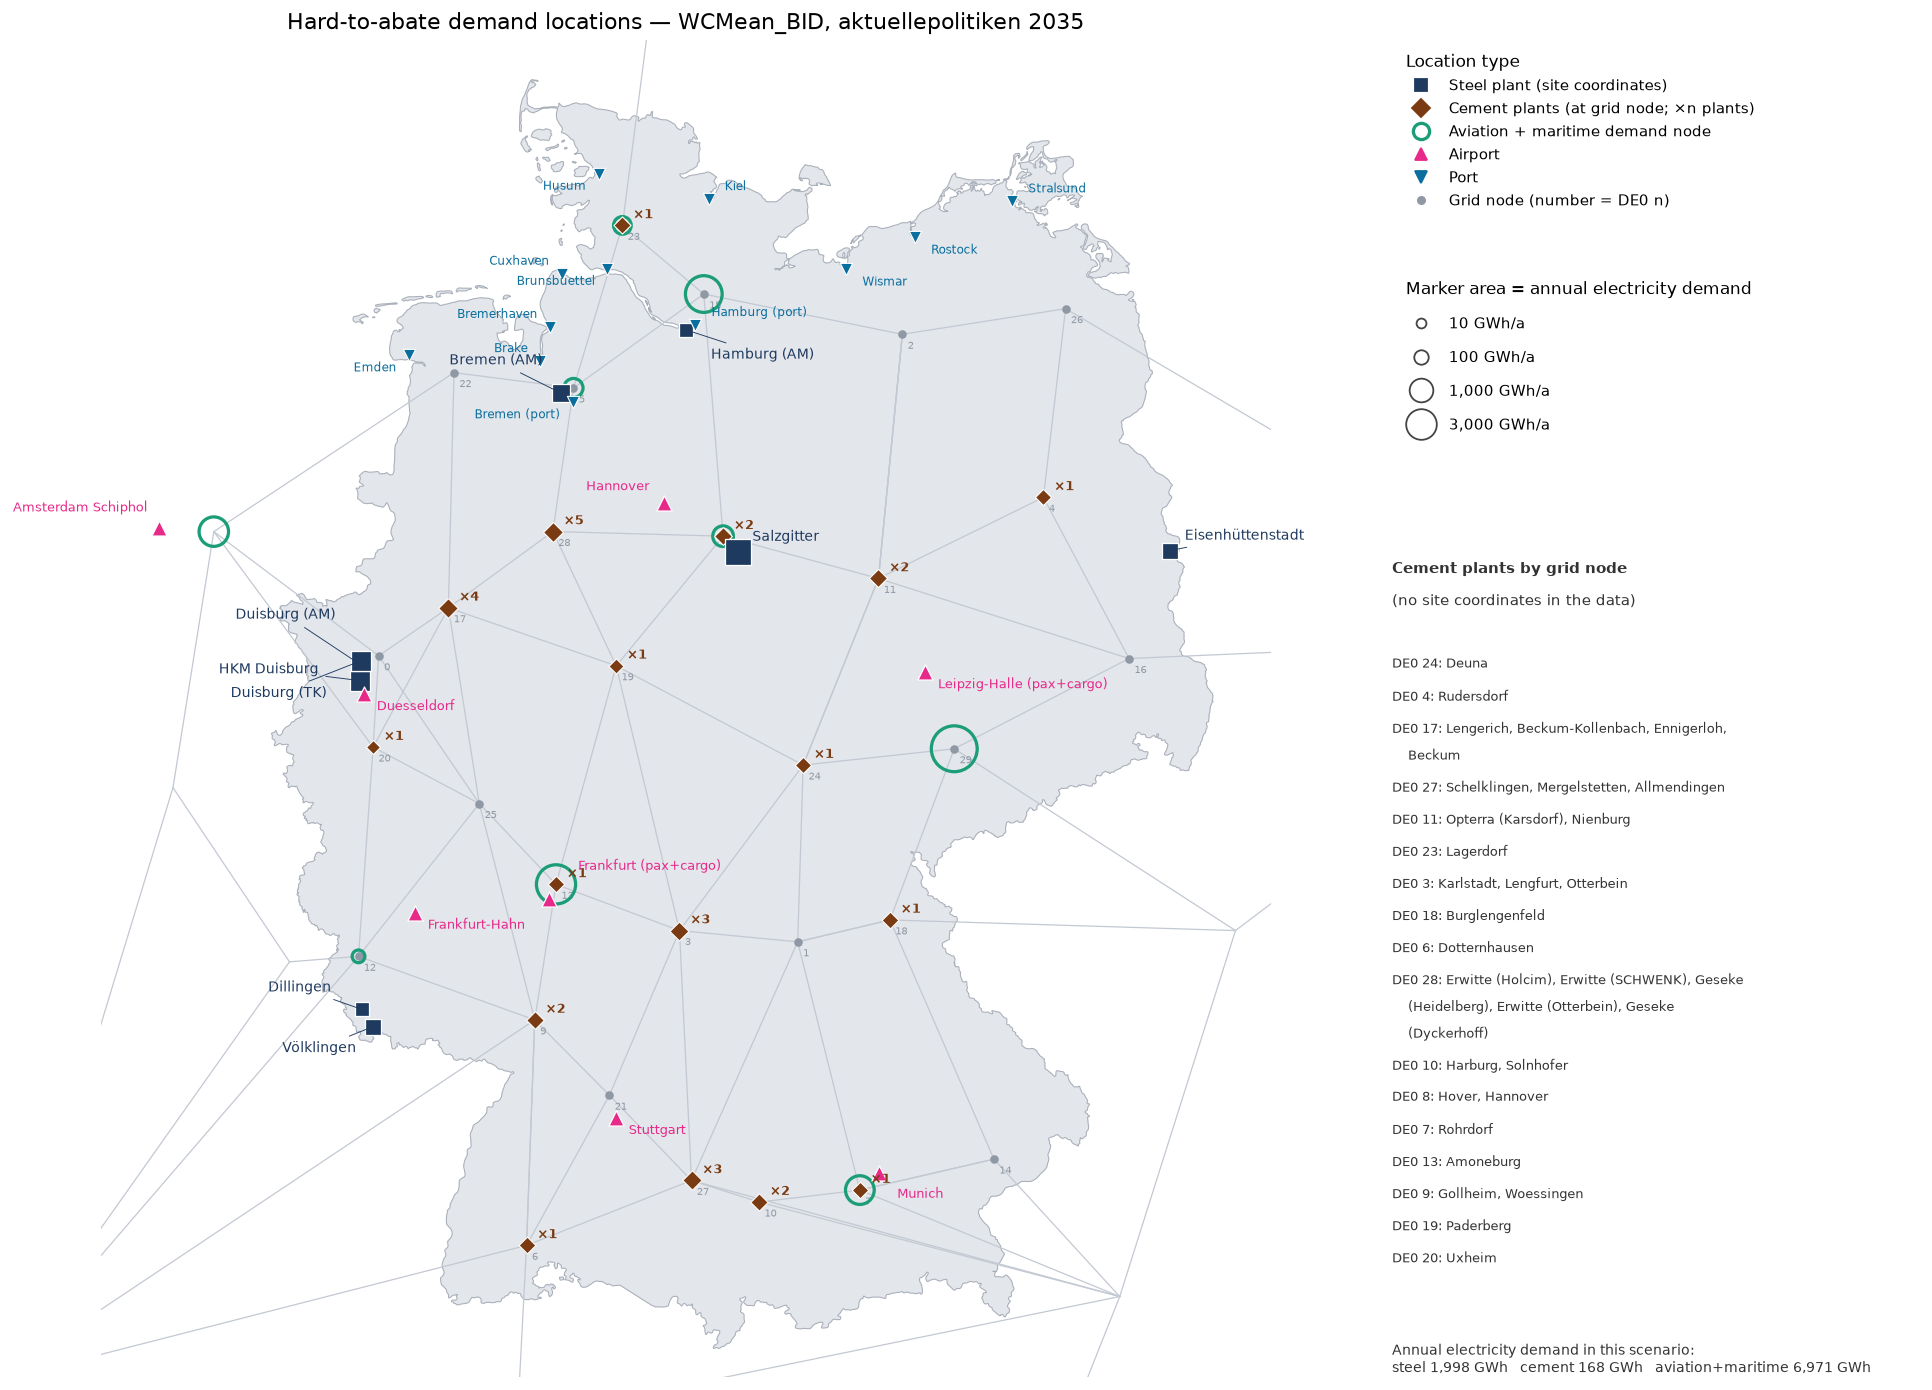

In [2]:
import os
import geopandas as gpd
import pyogrio
from matplotlib.lines import Line2D

MAP_CASE, MAP_FAMILY, MAP_YEAR = "WCMean_BID", "aktuellepolitiken", 2035

arch_dir = aiu.INPUTS_DIR / "archive"
scen_dir = aiu.INPUTS_DIR / MAP_CASE / f"{MAP_FAMILY}_{MAP_YEAR}"
buses_m = pd.read_csv(scen_dir / "buses.csv").set_index("name")
lines_m = pd.read_csv(scen_dir / "lines.csv", index_col=0)
units_m = pd.read_csv(scen_dir / "demand_units.csv", usecols=["name", "technology", "node"]).set_index("name")
dem_m = pd.read_csv(scen_dir / "demand_df.csv", index_col=0)
dem_m.index = pd.to_datetime(dem_m.index)
dem_m = dem_m[dem_m.index.year == MAP_YEAR]
gwh = dem_m.abs().sum() / 1000          # hourly MW -> GWh over the year (warm-up day excluded)

steel_m = pd.read_csv(arch_dir / "plant_nodes/steel_plant_nodes.csv")
steel_m["gwh"] = [gwh.get(f"demand_{p}_DA", 0.0) for p in steel_m["plant_id"]]
cement_m = pd.read_csv(arch_dir / "plant_nodes/cement_plant_nodes.csv")
cement_m["gwh"] = [gwh.get(f"demand_{p}_DA", 0.0) for p in cement_m["plant_id"]]
locs_m = pd.read_csv(arch_dir / "electricity_15min_price_allocated/aviation_maritime_locations_node_mapping.csv")
avmar_m = units_m[units_m["technology"].str.contains("avmar", na=False)].copy()
avmar_m["gwh"] = [gwh.get(n, 0.0) for n in avmar_m.index]

def germany_outline():
    # Detailed outline (union of demandlib's German test-reference regions, ~8k coastline points);
    # falls back to the coarse Natural Earth polygon if demandlib is unavailable.
    try:
        import demandlib
        p = os.path.join(os.path.dirname(demandlib.__file__), "vdi/resources_weather/TRY_polygons.geojson")
        geom = gpd.read_file(p).to_crs(4326).union_all()
    except Exception:
        shp = os.path.join(os.path.dirname(pyogrio.__file__), "tests/fixtures/naturalearth_lowres/naturalearth_lowres.shp")
        geom = gpd.read_file(shp).query("name == 'Germany'").geometry.iloc[0]
    return list(geom.geoms) if hasattr(geom, "geoms") else [geom]

germany_parts = germany_outline()

def size(g):                                # marker area (pt^2) grows with sqrt of annual GWh
    return 14 + 5.0 * np.sqrt(np.maximum(g, 0))

XL, YL = (4.2, 15.6), (47.1, 55.3)
fig = plt.figure(figsize=(15, 11))
gs = fig.add_gridspec(1, 2, width_ratios=[3.0, 1.15], wspace=0.02)
ax = fig.add_subplot(gs[0]); ax_t = fig.add_subplot(gs[1]); ax_t.axis("off")
for part in germany_parts:
    ax.add_patch(plt.Polygon(np.array(part.exterior.coords), fc="#e3e6eb", ec="#aab0ba", lw=0.6, zorder=0))
ax.set_xlim(*XL); ax.set_ylim(*YL); ax.set_aspect(1 / np.cos(np.radians(51))); ax.axis("off")

for _, l in lines_m.iterrows():             # transmission grid as quiet context
    a, b = buses_m.loc[l.bus0], buses_m.loc[l.bus1]
    ax.plot([a.x, b.x], [a.y, b.y], color="#c3c9d2", lw=0.7, zorder=1)
de = buses_m[buses_m.index.str.startswith("DE0")]
ax.scatter(de.x, de.y, s=14, c="#8f98a5", zorder=2)
for n, r in de.iterrows():
    ax.annotate(n.replace("DE0 ", ""), (r.x, r.y), xytext=(3, -8), textcoords="offset points", fontsize=5.5, color="#8f98a5", zorder=2)

C = {"steel": "#1f3a5f", "cement": "#7a3b12", "avmar": "#1b9e77", "air": "#e7298a", "port": "#0a6e9e"}

# aviation / maritime demand booked at grid nodes
for n, r in avmar_m.iterrows():
    p = buses_m.loc[r["node"]]
    ax.scatter(p.x, p.y, s=size(r.gwh) * 2.2, facecolors="none", edgecolors=C["avmar"], lw=1.8, zorder=3)

# cement: no site coordinates exist -> at the grid node, area = summed annual demand of that node's plants
if {"latitude", "longitude"} <= set(cement_m.columns):
    for _, r in cement_m.iterrows():
        ax.scatter(r.longitude, r.latitude, marker="D", s=size(r.gwh) * 1.6, c=C["cement"], ec="white", lw=0.6, zorder=5)
cn = cement_m.groupby("node").agg(gwh=("gwh", "sum"), n=("plant", "count"))
for node, r in (cn.iterrows() if not {"latitude", "longitude"} <= set(cement_m.columns) else []):
    p = buses_m.loc[node]
    ax.scatter(p.x, p.y, marker="D", s=size(r.gwh) * 1.6, c=C["cement"], ec="white", lw=0.6, zorder=5)
    ax.annotate(f"×{int(r.n)}", (p.x, p.y), xytext=(6, 4), textcoords="offset points", fontsize=7, color=C["cement"], weight="bold", zorder=7)

# steel: real coordinates
short = {"P100000120423": "Dillingen", "P100000120426": "Bremen (AM)", "P100000120428": "Duisburg (AM)", "P100000120425": "Eisenhüttenstadt",
         "P100000120427": "Hamburg (AM)", "P100000120422": "HKM Duisburg", "P100000120432": "Völklingen", "P100000120421": "Salzgitter",
         "P100000120424": "Duisburg (TK)"}
off = {"P100000120428": (-70, 26), "P100000120422": (-78, 4), "P100000120424": (-72, -20), "P100000120423": (-52, 10), "P100000120432": (-50, -14),
       "P100000120427": (14, -16), "P100000120426": (-62, 16)}
for _, r in steel_m.iterrows():
    ax.scatter(r.longitude, r.latitude, marker="s", s=size(r.gwh) * 1.3, c=C["steel"], ec="white", lw=0.7, zorder=6)
    dx, dy = off.get(r.plant_id, (8, 6))
    ax.annotate(short[r.plant_id], (r.longitude, r.latitude), xytext=(dx, dy), textcoords="offset points", fontsize=7.5, color=C["steel"],
                arrowprops=dict(arrowstyle="-", color=C["steel"], lw=0.5), zorder=8)

# airports and ports: real coordinates (Palma lies outside the map)
locs_in = locs_m[(locs_m.longitude > XL[0]) & (locs_m.longitude < XL[1]) & (locs_m.latitude > YL[0])].copy()
locs_in["kind"] = np.where(locs_in["category"].str.contains("Aviation"), "air", "port")
air = locs_in[locs_in.kind == "air"].groupby(["latitude", "longitude", "name"]).agg(kinds=("category", lambda s: " + ".join(sorted({"cargo" if "Cargo" in c else "pax" for c in s})))).reset_index()
for _, r in air.iterrows():
    ax.scatter(r.longitude, r.latitude, marker="^", s=70, c=C["air"], ec="white", lw=0.7, zorder=6)
    lab = r["name"].split(" (")[0].replace("am Main", "").strip() + (" (pax+cargo)" if "+" in r.kinds else "")
    dx, dy, ha = {"Hannover": (-8, 7, "right"), "Frankfurt": (16, 16, "left"), "Amsterdam": (-6, 9, "right"), "Munich": (10, -14, "left")}.get(r["name"].split(" ")[0], (7, -9, "left"))
    ax.annotate(lab, (r.longitude, r.latitude), xytext=(dx, dy), textcoords="offset points", fontsize=7, color=C["air"], ha=ha, zorder=8)
ports = locs_in[locs_in.kind == "port"].reset_index(drop=True)
for i, r in ports.iterrows():
    ax.scatter(r.longitude, r.latitude, marker="v", s=46, c=C["port"], ec="white", lw=0.6, zorder=6)
    west = r.longitude < 9.4 and r["name"] != "Hamburg"
    dx = -7 if west else 9
    dy = [5, -9, 5, -9, 5, -9, 5, -9, 5, -9, 5, -9][i % 12]
    ax.annotate({"Hamburg": "Hamburg (port)", "Bremen": "Bremen (port)"}.get(r["name"], r["name"]), (r.longitude, r.latitude), xytext=(dx, dy), textcoords="offset points", fontsize=6.8, color=C["port"],
                ha="right" if west else "left", zorder=8)

handles = [
    Line2D([], [], marker="s", ls="", c=C["steel"], ms=7, label="Steel plant (site coordinates)"),
    Line2D([], [], marker="D", ls="", c=C["cement"], ms=7, label="Cement plants (at grid node; ×n plants)"),
    Line2D([], [], marker="o", ls="", mfc="none", mec=C["avmar"], mew=1.8, ms=9, label="Aviation + maritime demand node"),
    Line2D([], [], marker="^", ls="", c=C["air"], ms=7, label="Airport"),
    Line2D([], [], marker="v", ls="", c=C["port"], ms=7, label="Port"),
    Line2D([], [], marker="o", ls="", c="#8f98a5", ms=4, label="Grid node (number = DE0 n)"),
]
leg1 = ax_t.legend(handles=handles, loc="upper left", bbox_to_anchor=(0, 1.0), frameon=False, fontsize=8.5, title="Location type", title_fontsize=9.5, alignment="left")
ax_t.add_artist(leg1)
gl = [10, 100, 1000, 3000]
ax_t.legend(handles=[Line2D([], [], marker="o", ls="", mfc="none", mec="#444", ms=np.sqrt(size(g)), label=f"{g:,} GWh/a") for g in gl],
            loc="upper left", bbox_to_anchor=(0, 0.83), frameon=False, fontsize=8.5, title="Marker area = annual electricity demand",
            title_fontsize=9.5, labelspacing=1.2, alignment="left")
ax.set_title(f"Hard-to-abate demand locations — {MAP_CASE}, {MAP_FAMILY} {MAP_YEAR}", fontsize=12)

# cement plant names by node (no coordinates available)
lines_txt = ["Cement plants by grid node", "(no site coordinates in the data)", ""]
for node, grp in cement_m.sort_values("node", key=lambda s: s.str.extract(r"(\d+)")[0].astype(int)).groupby("node", sort=False):
    lines_txt.append(f"{node}: " + ", ".join(grp["plant"]))
import textwrap
y = 0.61
for ln in lines_txt:
    wrapped = textwrap.wrap(ln, 54, subsequent_indent="    ") or [""]
    for w in wrapped:
        ax_t.text(0.0, y, w, fontsize=7.2 if ln.startswith("DE0") else 8.5, weight="bold" if ln.startswith("Cement") else "normal",
                  va="top", family="DejaVu Sans", color="#333"); y -= 0.0200
    y -= 0.004
tot = {"steel": steel_m.gwh.sum(), "cement": cement_m.gwh.sum(), "avmar": avmar_m.gwh.sum()}
ax_t.text(0.0, 0.0, f"Annual electricity demand in this scenario:\nsteel {tot['steel']:,.0f} GWh   cement {tot['cement']:,.0f} GWh   aviation+maritime {tot['avmar']:,.0f} GWh",
          fontsize=8, va="bottom", color="#333")
fig.subplots_adjust(left=0.01, right=0.995, top=0.955, bottom=0.02)
plt.show()


In [3]:
top_av = avmar_m.sort_values("gwh", ascending=False).iloc[0]
top_steel = steel_m.sort_values("gwh", ascending=False).iloc[0]
total_gwh = sum(tot.values())
display(Markdown(
    f"**Key finding:** in this scenario the three sectors add {total_gwh:,.0f} GWh/a, very unevenly: "
    f"aviation + maritime {tot['avmar']:,.0f} GWh ({tot['avmar'] / total_gwh:.0%}) booked at {len(avmar_m)} grid nodes, "
    f"the largest being {top_av['node']} with {top_av.gwh:,.0f} GWh; steel {tot['steel']:,.0f} GWh "
    f"({tot['steel'] / total_gwh:.0%}) at {len(steel_m)} plants in {steel_m['node'].nunique()} nodes, the largest "
    f"{top_steel['plant'].replace(' steel plant', '')} with {top_steel.gwh:,.0f} GWh; and cement only "
    f"{tot['cement']:,.0f} GWh ({tot['cement'] / total_gwh:.0%}) spread over {len(cement_m)} plants in "
    f"{cement_m['node'].nunique()} nodes. Where each plant sits is exact for steel, airports and ports, and "
    f"node-level for cement."
))

**Key finding:** in this scenario the three sectors add 9,137 GWh/a, very unevenly: aviation + maritime 6,971 GWh (76%) booked at 9 grid nodes, the largest being DE0 29 with 3,120 GWh; steel 1,998 GWh (22%) at 9 plants in 7 nodes, the largest Salzgitter Flachstahl with 916 GWh; and cement only 168 GWh (2%) spread over 32 plants in 17 nodes. Where each plant sits is exact for steel, airports and ports, and node-level for cement.

# Part A — Price-taker cases

The actors bid at the market cap (day-ahead 3,000 EUR/MWh, aFRR 9,999 EUR/MWh) with FLEXIMOD's pre-computed volumes, so their demand always clears and the price they see is whatever the market clears at. Scenarios: `AktuellePolitiken_RN`, `FokusH2_RN`, `FokusStrom_RN`, `HoheNachfrage_RN`, `NachfrageNiedrig_RN`, `Technologiemix_RN`, `WCMean`, `WCTail`, each with 6 families x 4 years.

In [4]:
TREATMENT = "price-taker"
CASES = aiu.PRICE_TAKER_CASES
RN_LIKE = [c for c in CASES if not c.startswith("WC")]
CASE_COLOR = dict(zip(CASES, ["#0072B2", "#E69F00", "#009E73", "#D55E00", "#CC79A7", "#56B4E9", "#000000", "#999999"]))

## A1. What's actually in `examples/outputs/` right now

Before analysing anything, check that every scenario of this part is present.

In [5]:
archives = aiu.discover_archives()
archives = archives[archives["case"].isin(CASES)].reset_index(drop=True)  # this part only

coverage = (
    archives.assign(n=1)
    .pivot_table(index="case", columns="family", values="n", aggfunc="sum", fill_value=0)
    .reindex(columns=aiu.FAMILIES, fill_value=0)
    .reindex(index=CASES, fill_value=0)
)
coverage["total"] = coverage.sum(axis=1)
coverage.loc["TOTAL"] = coverage.sum(axis=0)

print(f"{len(archives)}/192 scenarios of this part found "
      f"({len(archives) / 192:.0%}).")
print(f"Cases with at least one finished scenario: {sorted(archives['case'].unique())}")
coverage

192/192 scenarios of this part found (100%).
Cases with at least one finished scenario: ['AktuellePolitiken_RN', 'FokusH2_RN', 'FokusStrom_RN', 'HoheNachfrage_RN', 'NachfrageNiedrig_RN', 'Technologiemix_RN', 'WCMean', 'WCTail']


family,aktuellepolitiken,fokusH2,fokusstrom,hohenachfrage,niedrigenachfrage,technologiemix,total
case,,,,,,,
AktuellePolitiken_RN,4,4,4,4,4,4,24
FokusH2_RN,4,4,4,4,4,4,24
FokusStrom_RN,4,4,4,4,4,4,24
HoheNachfrage_RN,4,4,4,4,4,4,24
NachfrageNiedrig_RN,4,4,4,4,4,4,24
Technologiemix_RN,4,4,4,4,4,4,24
WCMean,4,4,4,4,4,4,24
WCTail,4,4,4,4,4,4,24
TOTAL,32,32,32,32,32,32,192


## A2. Overall day-ahead (EOM) and aFRR energy negative price impact

For every finished with-actor scenario, each hourly EOM / aFRR energy negative
clearing price is matched to the same hour in the matching no-actor baseline
(same family + year), and `delta = price_with_actors - price_baseline` is
computed directly (no aggregation across timestamps beforehand).

In [6]:
price_panel = aiu.build_price_panel(archives)
print(f"{len(price_panel):,} matched hourly price rows across "
      f"{price_panel[['case','family','year']].drop_duplicates().shape[0]} scenarios.")
price_panel.head()

3,354,624 matched hourly price rows across 192 scenarios.


,market_id,price_actor,time,price_baseline,case,family,year,is_bid,delta
0,EOM,10.016,2030-01-01 00:00:00,10.016,AktuellePolitiken_RN,aktuellepolitiken,2030,False,0.000
1,EOM,10.016,2030-01-01 01:00:00,0.000,AktuellePolitiken_RN,aktuellepolitiken,2030,False,10.016
2,EOM,10.016,2030-01-01 02:00:00,10.016,AktuellePolitiken_RN,aktuellepolitiken,2030,False,0.000
3,EOM,10.016,2030-01-01 03:00:00,0.000,AktuellePolitiken_RN,aktuellepolitiken,2030,False,10.016
4,EOM,10.016,2030-01-01 04:00:00,0.000,AktuellePolitiken_RN,aktuellepolitiken,2030,False,10.016


In [7]:
summary = (
    price_panel.groupby("market_id")["delta"]
    .agg(mean="mean", median="median", std="std", p05=lambda s: s.quantile(0.05),
         p95=lambda s: s.quantile(0.95), max="max", min="min")
    .round(2)
)
summary.rename(index=MARKET_LABEL)

,mean,median,std,p05,p95,max,min
market_id,,,,,,,
aFRR energy negative,0.75,0.0,12.22,0.00,0.02,560.42,-0.02
EOM,55.27,0.0,278.78,-6.45,228.87,3000.00,-3000.00


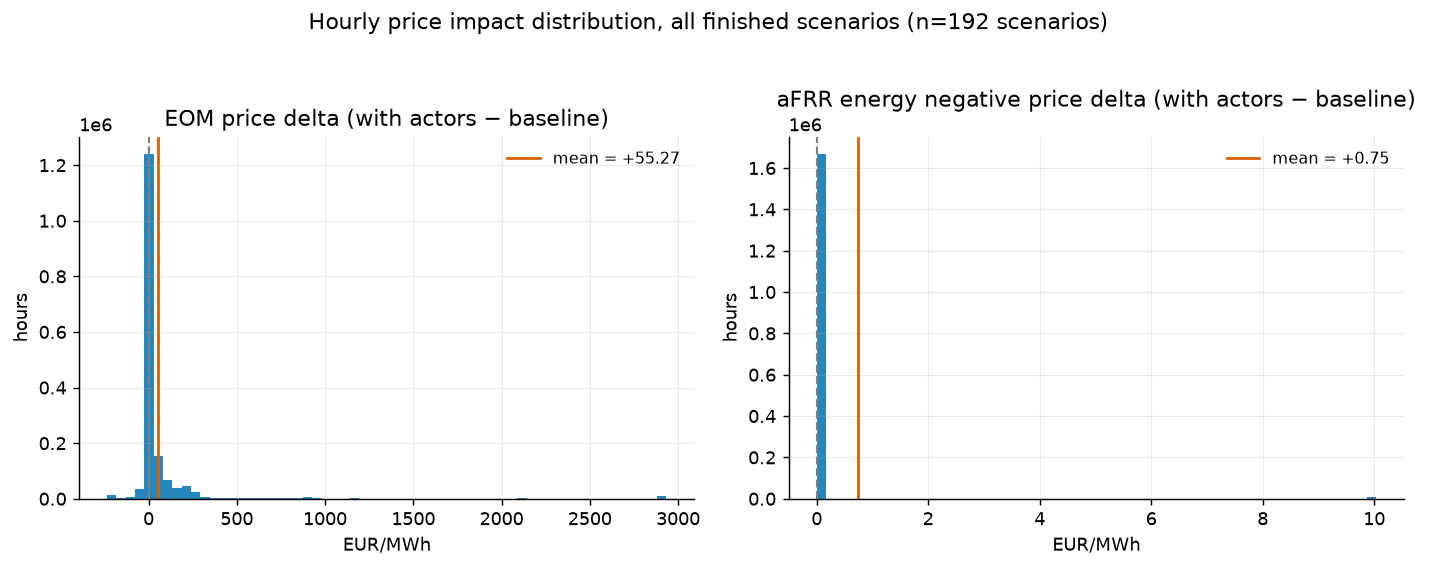

In [8]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4.2), sharey=False)
for ax, market in zip(axes, ["EOM", "CRM_energy_neg"]):
    d = price_panel.loc[price_panel["market_id"] == market, "delta"]
    ax.hist(d.clip(d.quantile(0.005), d.quantile(0.995)), bins=60,
            color=COLOR["actor"], alpha=0.85)
    ax.axvline(0, color=COLOR["baseline"], linewidth=1.2, linestyle="--")
    ax.axvline(d.mean(), color=COLOR["combined"], linewidth=1.5,
                label=f"mean = {d.mean():+.2f}")
    ax.set_title(f"{MARKET_LABEL.get(market, market)} price delta (with actors − baseline)")
    ax.set_xlabel("EUR/MWh" if market == "EOM" else "EUR/MWh")
    ax.set_ylabel("hours")
    ax.legend(frameon=False, fontsize=9)
fig.suptitle("Hourly price impact distribution, all finished scenarios "
             f"(n={price_panel[['case','family','year']].drop_duplicates().shape[0]} scenarios)",
             y=1.03)
fig.tight_layout()
plt.show()

In [9]:
by_year = (
    price_panel.groupby(["market_id", "year"])["delta"]
    .agg(mean="mean", median="median", p95=lambda s: s.quantile(0.95))
    .round(2)
    .unstack("market_id")
)
by_year.rename(columns=MARKET_LABEL, level=1)

mean                       median       \
market_id aFRR energy negative     EOM aFRR energy negative  EOM   
year                                                               
2030                      0.35   16.38                  0.0  0.0   
2035                      0.58   29.47                  0.0  0.0   
2040                      0.53  143.16                  0.0  0.0   
2045                      1.53   32.06                  0.0  0.0   

                           p95          
market_id aFRR energy negative     EOM  
year                                    
2030                      0.02  103.93  
2035                      0.02  233.50  
2040                      0.02  874.21  
2045                      0.02  197.68

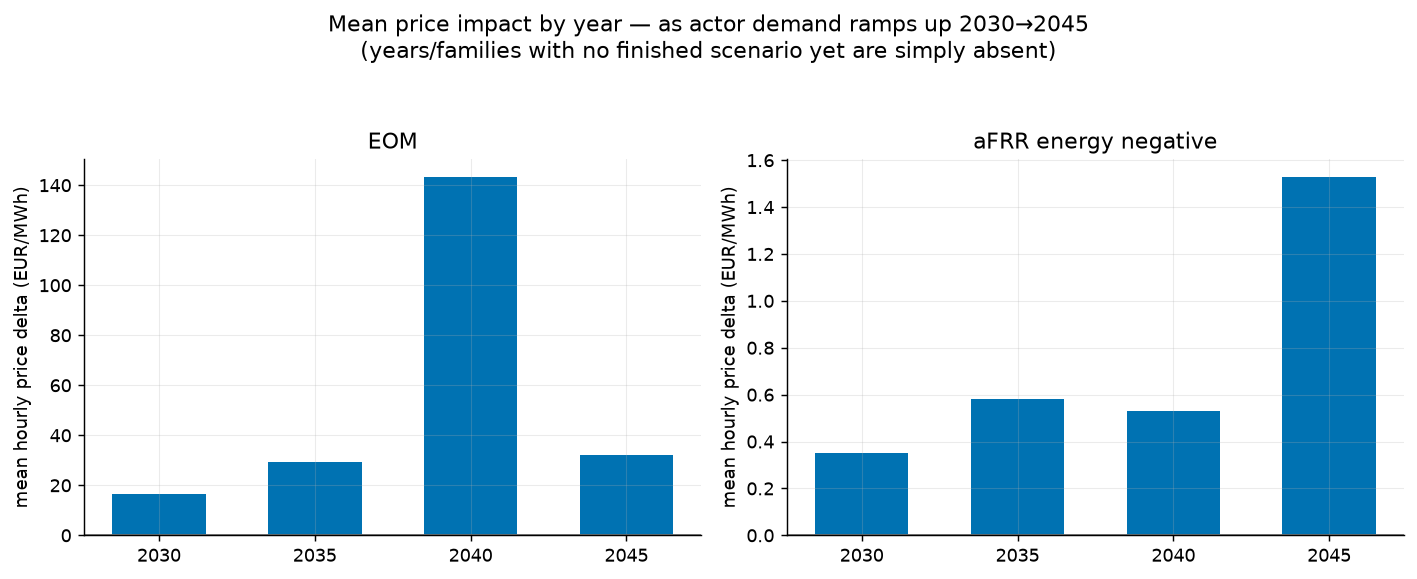

Scenario coverage behind this chart, by year:
year
2030    48
2035    48
2040    48
2045    48
dtype: int64


In [10]:
# EOM and aFRR energy negative deltas are ~1000x apart in magnitude (EUR/MWh vs.
# fractions of a cent) -- one shared axis would make aFRR energy negative invisible,
# so this is two independently-scaled panels rather than one dual-axis chart.
piv = price_panel.groupby(["year", "market_id"])["delta"].mean().unstack("market_id")
fig, axes = plt.subplots(1, 2, figsize=(11, 4.2))
for ax, market in zip(axes, ["EOM", "CRM_energy_neg"]):
    vals = piv.get(market, pd.Series(index=piv.index, dtype=float))
    ax.bar(piv.index.astype(str), vals, color=COLOR["actor"], width=0.6)
    ax.axhline(0, color=COLOR["baseline"], linewidth=1)
    ax.set_ylabel("mean hourly price delta (EUR/MWh)")
    ax.set_title(MARKET_LABEL.get(market, market))
fig.suptitle("Mean price impact by year — as actor demand ramps up 2030→2045\n"
             "(years/families with no finished scenario yet are simply absent)", y=1.05)
fig.tight_layout()
plt.show()

print("Scenario coverage behind this chart, by year:")
print(archives.groupby("year").size().reindex(aiu.YEARS, fill_value=0))

In [11]:
eom_mean = summary.loc["EOM", "mean"] if "EOM" in summary.index else float("nan")
eom_median = summary.loc["EOM", "median"] if "EOM" in summary.index else float("nan")
eom_max = summary.loc["EOM", "max"] if "EOM" in summary.index else float("nan")
eom_min = summary.loc["EOM", "min"] if "EOM" in summary.index else float("nan")
afrr_mean = summary.loc["CRM_energy_neg", "mean"] if "CRM_energy_neg" in summary.index else float("nan")

eom_year_means = by_year[("mean", "EOM")].dropna() if ("mean", "EOM") in by_year.columns else pd.Series(dtype=float)
trend_note = (
    "an upward drift across the years collected so far"
    if len(eom_year_means) >= 2 and eom_year_means.iloc[-1] > eom_year_means.iloc[0]
    else "no clean multi-year trend yet"
)

cap_note = (" — the extremes sit at the 3,000 EUR/MWh price cap/floor"
            if max(abs(eom_min), abs(eom_max)) >= 2900 else "")
skew_note = ("most hours are unaffected, and the mean is pulled by a small number of extreme hours"
             if abs(eom_median) < 0.1 * abs(eom_mean) else "the typical hour is shifted as well")
ratio = abs(eom_mean / afrr_mean) if afrr_mean else float("nan")
ratio_note = (f"about {ratio:.0f}x below the EOM shift" if ratio >= 1 else f"about {1 / ratio:.1f}x above the EOM shift")
display(Markdown(
    f"**Key finding:** across every scenario of this part, the new actors shift the mean EOM price "
    f"by **{eom_mean:+.1f} EUR/MWh**; the *median* shift is **{eom_median:.1f}** — {skew_note} "
    f"(delta ranges from **{eom_min:+.0f}** to **{eom_max:+.0f} EUR/MWh**{cap_note}). The aFRR energy negative "
    f"shift is {'much smaller' if ratio > 5 else 'of similar size'} in absolute terms "
    f"(mean **{afrr_mean:+.3f} EUR/MWh**, {ratio_note}). "
    f"By year, there's {trend_note} (first vs. last year only, not a fitted trend)."
))

**Key finding:** across every scenario of this part, the new actors shift the mean EOM price by **+55.3 EUR/MWh**; the *median* shift is **0.0** — most hours are unaffected, and the mean is pulled by a small number of extreme hours (delta ranges from **-3000** to **+3000 EUR/MWh** — the extremes sit at the 3,000 EUR/MWh price cap/floor). The aFRR energy negative shift is much smaller in absolute terms (mean **+0.750 EUR/MWh**, about 74x below the EOM shift). By year, there's an upward drift across the years collected so far (first vs. last year only, not a fitted trend).

## A3. Per-actor-category contribution

`market_orders.csv` is streamed and filtered (chunked, `usecols`-limited — the
raw file is several GB per scenario) down to just the three actor categories'
own bids, aggregated to one row per (scenario, hour, market, category). This
gives cleared volume per category, which is compared against the *system-wide*
price delta from Section A2 as a proxy for each category's share of the impact
— see the Methodology caveat: this is an attribution over a joint run, not an
ablation.

In [12]:
orders_panel = aiu.build_orders_panel(archives)
print(f"{len(orders_panel):,} (scenario, hour, market, category) rows.")
orders_panel.head().assign(market_id=lambda d: d["market_id"].replace(MARKET_LABEL))

6,371,921 (scenario, hour, market, category) rows.


,start_time,market_id,category,volume,accepted_volume,case,family,year,is_bid
0,2030-01-01,aFRR energy negative,cement,-10455.00000,-10455.00000,AktuellePolitiken_RN,aktuellepolitiken,2030,False
1,2030-01-01,aFRR energy negative,steel,-544.00000,-544.00000,AktuellePolitiken_RN,aktuellepolitiken,2030,False
2,2030-01-01,EOM,aviation_maritime,-71.71235,-71.71235,AktuellePolitiken_RN,aktuellepolitiken,2030,False
3,2030-01-01,EOM,cement,-10468.17270,-10468.17270,AktuellePolitiken_RN,aktuellepolitiken,2030,False
4,2030-01-01,EOM,steel,-3.34928,-3.34928,AktuellePolitiken_RN,aktuellepolitiken,2030,False


In [13]:
vol_summary = (
    orders_panel.groupby(["market_id", "category"])[["volume", "accepted_volume"]]
    .sum()
    .abs()  # demand volumes are signed negative in market_orders.csv
    .rename(columns={"volume": "bid_MWh", "accepted_volume": "cleared_MWh"})
)
vol_summary["cleared_share"] = (vol_summary["cleared_MWh"] / vol_summary["bid_MWh"]).round(4)
vol_summary.round(1).rename(index=MARKET_LABEL, level=0)

bid_MWh   cleared_MWh  \
market_id            category                                        
aFRR energy negative cement             5.755316e+09  5.748961e+09   
                     steel              2.798473e+09  2.795975e+09   
EOM                  aviation_maritime  1.754531e+09  1.752601e+09   
                     cement             1.370349e+10  1.367839e+10   
                     steel              7.904218e+09  7.892603e+09   

                                        cleared_share  
market_id            category                          
aFRR energy negative cement                       1.0  
                     steel                        1.0  
EOM                  aviation_maritime            1.0  
                     cement                       1.0  
                     steel                        1.0

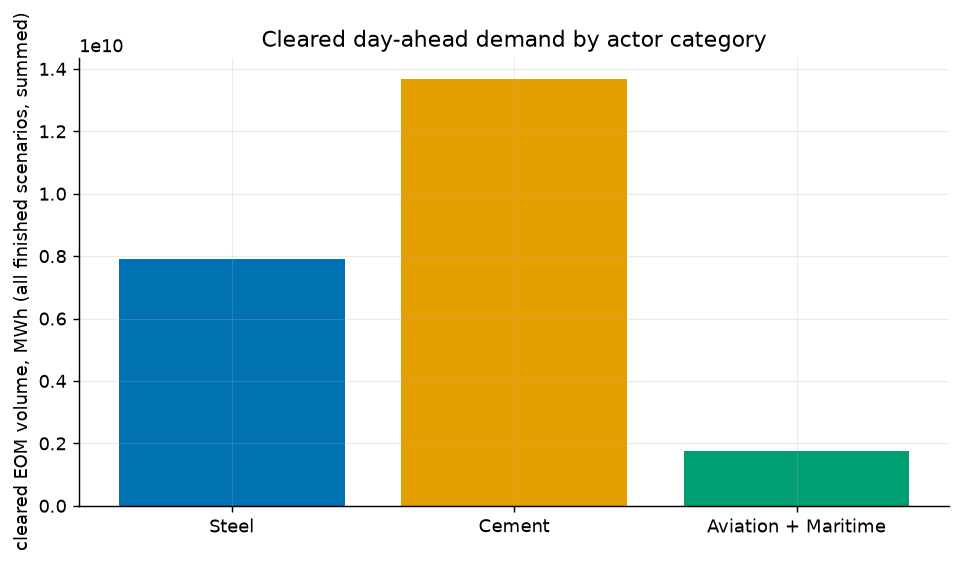

In [14]:
fig, ax = plt.subplots(figsize=(7.5, 4.2))
share = (
    orders_panel[orders_panel["market_id"] == "EOM"]
    .groupby("category")["accepted_volume"].sum().abs()
)
share = share.reindex(CATEGORIES)
ax.bar([CATEGORY_LABEL[c] for c in share.index], share.values,
       color=[COLOR[c] for c in share.index])
ax.set_ylabel("cleared EOM volume, MWh (all finished scenarios, summed)")
ax.set_title("Cleared day-ahead demand by actor category")
fig.tight_layout()
plt.show()

In [15]:
# Hour-by-hour: does the system price delta track total actor demand?
hourly_price = (
    price_panel[price_panel["market_id"] == "EOM"]
    .groupby(["case", "family", "year", "time"])["delta"].mean()
)
hourly_actor_vol = (
    orders_panel[orders_panel["market_id"] == "EOM"]
    .groupby(["case", "family", "year", "start_time", "category"])["accepted_volume"]
    .sum().abs().unstack("category").reindex(columns=CATEGORIES, fill_value=0)
)
hourly_actor_vol.index = hourly_actor_vol.index.set_names("time", level="start_time")

joined = hourly_price.to_frame("price_delta").join(hourly_actor_vol, how="inner")
joined["total_actor_volume"] = joined[CATEGORIES].sum(axis=1)

corr = joined[["price_delta", "total_actor_volume", *CATEGORIES]].corr()["price_delta"].drop("price_delta")
print("Hour-level correlation of EOM price delta with cleared actor volume "
      "(system-wide and per category):")
corr.round(3)

Hour-level correlation of EOM price delta with cleared actor volume (system-wide and per category):


total_actor_volume    0.031
steel                 0.003
cement                0.046
aviation_maritime     0.041
Name: price_delta, dtype: float64

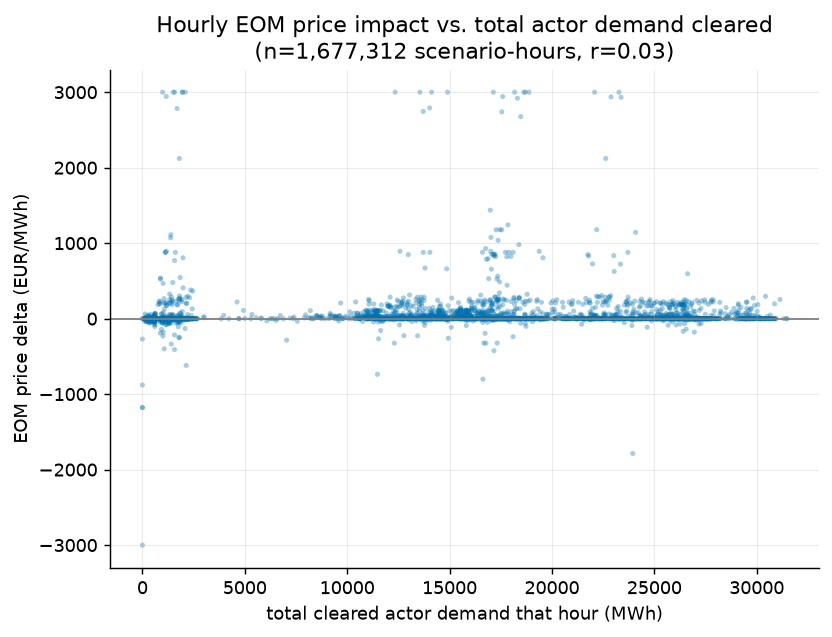

In [16]:
fig, ax = plt.subplots(figsize=(6.5, 5))
sample = joined.sample(min(4000, len(joined)), random_state=0) if len(joined) else joined
ax.scatter(sample["total_actor_volume"], sample["price_delta"],
           s=8, alpha=0.35, color=COLOR["actor"], edgecolors="none")
ax.axhline(0, color=COLOR["baseline"], linewidth=1)
ax.set_xlabel("total cleared actor demand that hour (MWh)")
ax.set_ylabel("EOM price delta (EUR/MWh)")
ax.set_title("Hourly EOM price impact vs. total actor demand cleared\n"
             f"(n={len(joined):,} scenario-hours, r={corr.get('total_actor_volume', float('nan')):.2f})")
fig.tight_layout()
plt.show()

In [17]:
eom_vol = vol_summary.loc["EOM"]
dominant = eom_vol["cleared_MWh"].idxmax()
dominant_twh = eom_vol.loc[dominant, "cleared_MWh"] / 1e6
other_twh = {c: eom_vol.loc[c, "cleared_MWh"] / 1e6 for c in CATEGORIES if c != dominant and c in eom_vol.index}
others_str = ", ".join(f"{v:.2f} TWh {CATEGORY_LABEL[c].lower()}" for c, v in other_twh.items())

n_scenarios = orders_panel[["case", "family", "year"]].drop_duplicates().shape[0]
display(Markdown(
    f"**Key finding:** {CATEGORY_LABEL[dominant]} clears by far the most day-ahead volume, "
    f"summed across all {n_scenarios} finished scenarios "
    f"({dominant_twh:.1f} TWh vs. {others_str} — each figure a multi-scenario total, not a single "
    f"year's consumption), making it the largest single contributor to the aggregate demand added "
    f"system-wide. But hour-level correlation between any category's "
    f"cleared volume and the EOM price delta stays weak "
    f"(r = {corr.get('total_actor_volume', float('nan')):.2f} combined, "
    f"r = {corr.get(dominant, float('nan')):.2f} for {CATEGORY_LABEL[dominant].lower()} alone) — "
    f"consistent with the price swings above coming from a handful of scarcity hours, not from "
    f"the general volume level."
))

**Key finding:** Cement clears by far the most day-ahead volume, summed across all 192 finished scenarios (13678.4 TWh vs. 7892.60 TWh steel, 1752.60 TWh aviation + maritime — each figure a multi-scenario total, not a single year's consumption), making it the largest single contributor to the aggregate demand added system-wide. But hour-level correlation between any category's cleared volume and the EOM price delta stays weak (r = 0.03 combined, r = 0.05 for cement alone) — consistent with the price swings above coming from a handful of scarcity hours, not from the general volume level.

## A4. Served share of the actors' demand (price-taker cases)

In the price-taker cases every actor bids at the market cap (day-ahead 3,000 EUR/MWh, aFRR 9,999 EUR/MWh), so its demand should clear almost fully. The share below (accepted / submitted volume) checks that and shows where it does not hold. It is the background to keep in mind for the price impacts in this part: whatever the actors ask for is, to a good approximation, served.

category,Steel,Cement,Aviation + Maritime
market_id,,,
aFRR energy negative,0.999,0.999,NaN
EOM,0.999,0.998,0.999


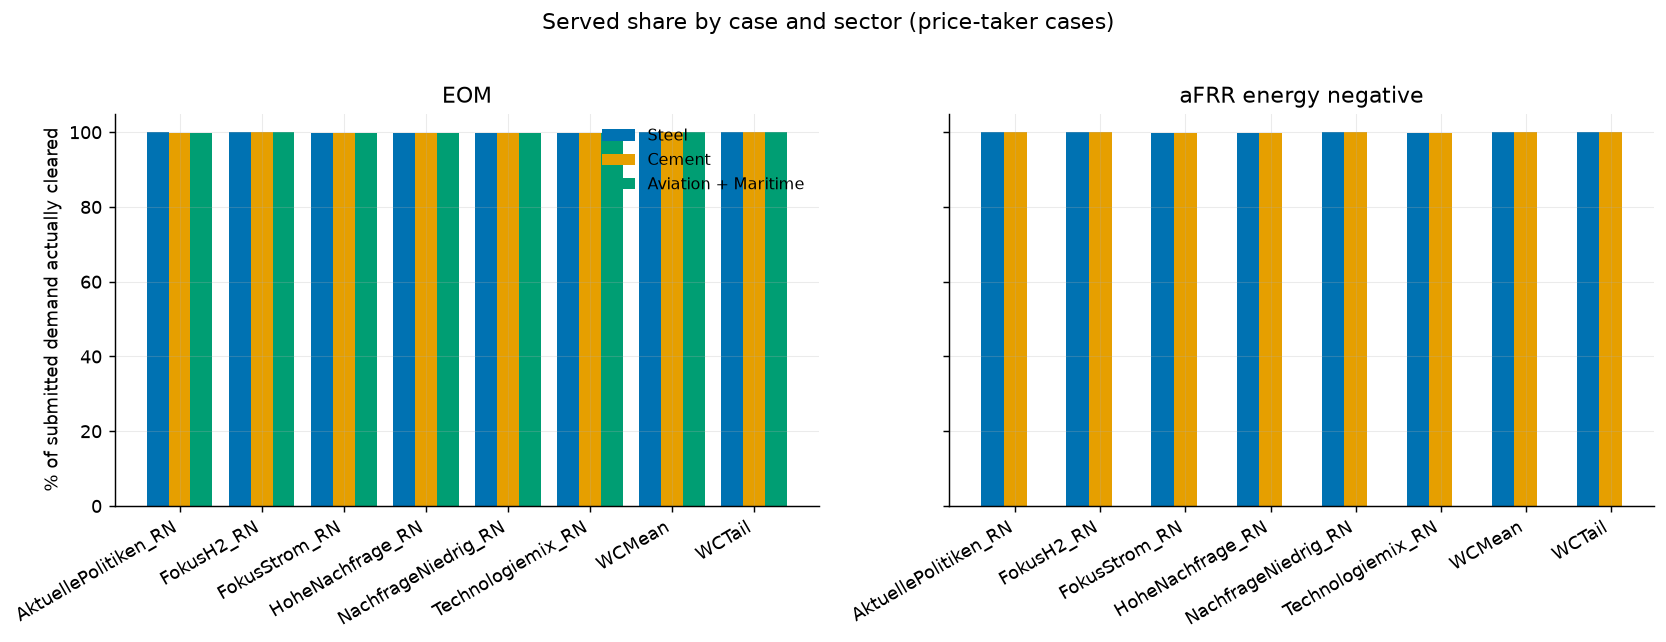

In [18]:
orders_bid = orders_panel[orders_panel["case"].isin(CASES)].copy()
orders_bid[["volume", "accepted_volume"]] = orders_bid[["volume", "accepted_volume"]].abs()

def served(df, by):
    g = df.groupby(by)[["volume", "accepted_volume"]].sum()
    return g["accepted_volume"] / g["volume"]

by_cat = served(orders_bid, ["market_id", "category"]).unstack("category")[CATEGORIES]
display(by_cat.round(3).rename(columns=CATEGORY_LABEL, index=MARKET_LABEL))

fig, axes = plt.subplots(1, 2, figsize=(13, 4.8), sharey=True)
for ax, market in zip(axes, ["EOM", "CRM_energy_neg"]):
    sub = orders_bid[orders_bid["market_id"] == market]
    piv = served(sub, ["case", "category"]).unstack("category").reindex(index=CASES, columns=CATEGORIES)
    x = np.arange(len(CASES))
    w = 0.8 / len(CATEGORIES)
    for i, c in enumerate(CATEGORIES):
        ax.bar(x + (i - 1) * w, piv[c] * 100, width=w, color=COLOR[c], label=CATEGORY_LABEL[c])
    ax.set_xticks(x)
    ax.set_xticklabels(CASES, rotation=30, ha="right")
    ax.set_ylim(0, 105)
    ax.set_title(MARKET_LABEL.get(market, market))
axes[0].set_ylabel("% of submitted demand actually cleared")
axes[0].legend(frameon=False, fontsize=9)
fig.suptitle(f"Served share by case and sector ({TREATMENT} cases)", y=1.02)
fig.tight_layout()
plt.show()

In [19]:
eom = by_cat.loc["EOM"]
display(Markdown(
    f"**Key finding:** in the price-taker cases the actors are served almost fully: on the day-ahead market "
    f"{CATEGORY_LABEL[eom.idxmax()]} clears {eom.max():.1%} of its submitted volume and "
    f"{CATEGORY_LABEL[eom.idxmin()]} {eom.min():.1%}, so their full demand reaches the market in practically every hour."
))

**Key finding:** in the price-taker cases the actors are served almost fully: on the day-ahead market Aviation + Maritime clears 99.9% of its submitted volume and Cement 99.8%, so their full demand reaches the market in practically every hour.

## A5. Quarterly aFRR capacity price by case (aFRR capacity positive / aFRR capacity negative)

A different market from everything above: aFRR capacity positive/aFRR capacity negative
are the daily capacity auctions (6x 4-hour blocks/day, `pay_as_bid`), not the
hourly energy markets Sections A2–A4 analyze. **The new actors don't submit bids
into either capacity market** — `demand_units.csv` leaves
`bidding_CRM_capacity_pos`/`bidding_CRM_capacity_neg` blank for every steel,
cement and AVMAR unit.

That turns out *not* to mean the capacity price is unaffected, though (see the
sanity check below): with-actors capacity prices differ substantially from the
baseline's, even though no actor bid is present in either market. The
likely mechanism is indirect — the new EOM/aFRR-energy demand changes which
powerplants get dispatched and what capacity they have left over to offer into
the capacity auction, which feeds through to the `pay_as_bid` clearing price.
That's a real second-order finding worth noting, not a bug in this notebook —
but it does mean this section is *not* a clean "actors vs. no actors" panel;
it's a descriptive view of the capacity market by case, shown here because it
groups the same way as the rest of the notebook (by case, auto-updating as
more scenarios finish).

Two more unit notes vs. a typical real-world reference: our `market_meta.csv`
`price` column is `EUR/MW` per cleared 4-hour product block (`config.yaml`'s
`price_unit`), not `EUR/MW/week`, and "quarter" here means calendar quarter of
the product's delivery hour, averaged across whatever family/year combinations
have finished for each case (not a single fixed scenario).

In [20]:
capacity_panel = aiu.build_capacity_panel(archives)
print(f"{len(capacity_panel):,} matched (case, hour, market) capacity rows.")

print("\nScenarios behind each case's bars (family x year combos finished):")
print(archives[archives['case'].isin(CASES)].groupby("case").size()
      .reindex(CASES, fill_value=0))

# No actor bid ever appears in these markets -- so any gap here is an indirect
# effect (via dispatch/available capacity), not a direct bidding effect.
gap = (capacity_panel["price_actor"] - capacity_panel["price_baseline"]).abs()
level = capacity_panel[["price_actor", "price_baseline"]].mean().mean()
print(f"\nmean |with-actors − baseline| capacity price gap: {gap.mean():.1f} EUR/MW "
      f"vs. a mean price level of {level:.1f} EUR/MW across both — a "
      f"{gap.mean() / level:.0%} gap despite zero direct actor bids in this market, "
      "i.e. an indirect (dispatch-driven) effect, not noise.")

838,656 matched (case, hour, market) capacity rows.

Scenarios behind each case's bars (family x year combos finished):
case
AktuellePolitiken_RN    24
FokusH2_RN              24
FokusStrom_RN           24
HoheNachfrage_RN        24
NachfrageNiedrig_RN     24
Technologiemix_RN       24
WCMean                  24
WCTail                  24
dtype: int64

mean |with-actors − baseline| capacity price gap: 122.4 EUR/MW vs. a mean price level of 92.1 EUR/MW across both — a 133% gap despite zero direct actor bids in this market, i.e. an indirect (dispatch-driven) effect, not noise.


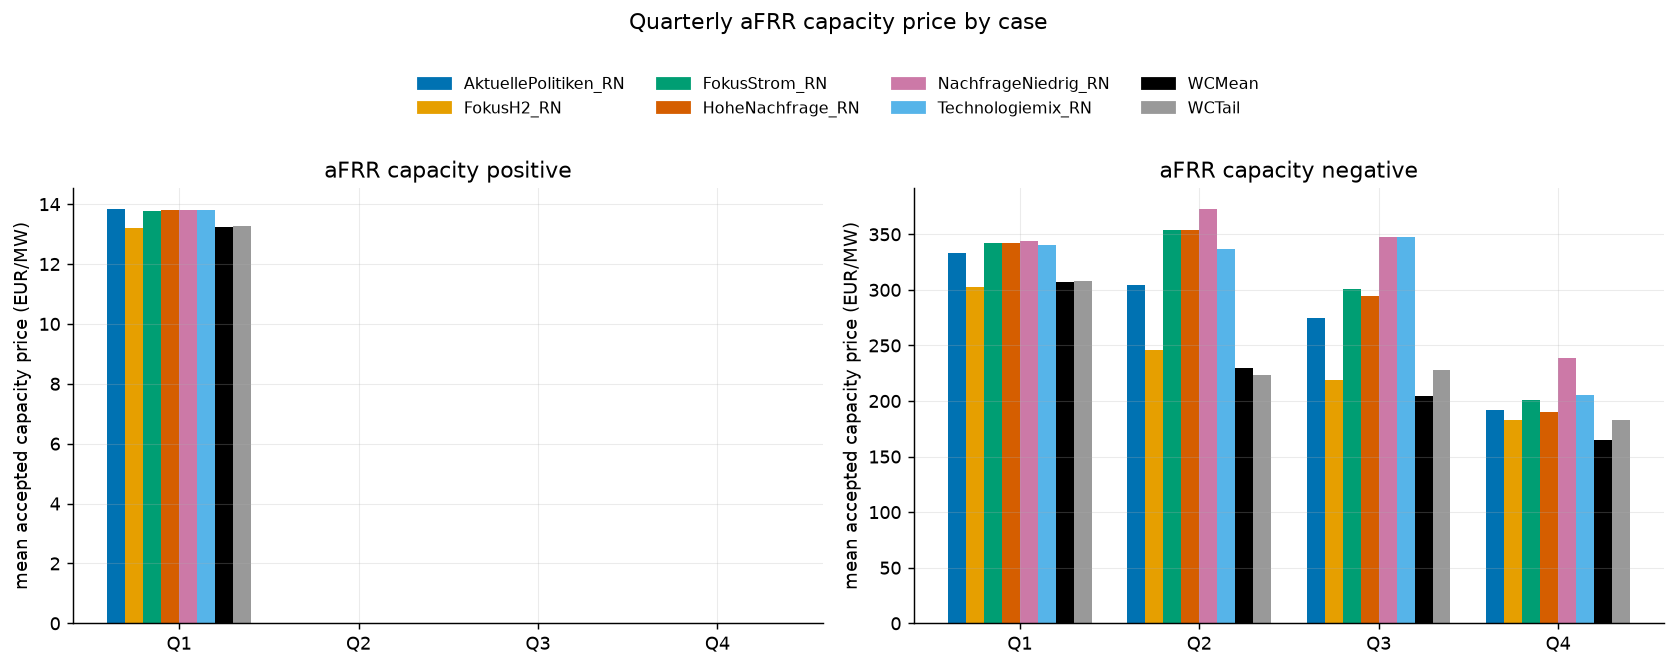

In [21]:
cases_present = [c for c in CASES if c in capacity_panel["case"].unique()]
quarters = [1, 2, 3, 4]
x = np.arange(len(quarters))
n = max(len(cases_present), 1)
width = 0.8 / n

fig, axes = plt.subplots(1, 2, figsize=(13, 4.8))
for ax, market in zip(axes, aiu.CAPACITY_MARKETS):
    sub = capacity_panel[capacity_panel["market_id"] == market]
    piv = sub.groupby(["quarter", "case"])["price_actor"].mean().unstack("case").reindex(quarters)
    for i, case in enumerate(cases_present):
        vals = piv[case] if case in piv.columns else pd.Series(np.nan, index=quarters)
        ax.bar(x + (i - (n - 1) / 2) * width, vals, width=width, color=CASE_COLOR[case])
    ax.set_xticks(x)
    ax.set_xticklabels([f"Q{q}" for q in quarters])
    ax.set_ylabel("mean accepted capacity price (EUR/MW)")
    ax.set_title(MARKET_LABEL.get(market, market))

handles = [plt.Rectangle((0, 0), 1, 1, color=CASE_COLOR[c]) for c in cases_present]
fig.suptitle("Quarterly aFRR capacity price by case", y=1.06)
fig.legend(handles, cases_present, loc="upper center", bbox_to_anchor=(0.5, 0.98),
           ncol=4, frameon=False, fontsize=9)
fig.tight_layout(rect=[0, 0, 1, 0.92])
plt.show()

In [22]:
cap_neg = capacity_panel[capacity_panel["market_id"] == "CRM_capacity_neg"]
cap_pos = capacity_panel[capacity_panel["market_id"] == "CRM_capacity_pos"]
by_case_q = cap_neg.groupby(["case", "quarter"])["price_actor"].mean().unstack("quarter")
q1_mean = by_case_q[1].mean() if 1 in by_case_q.columns else float("nan")
q4_mean = by_case_q[4].mean() if 4 in by_case_q.columns else float("nan")
highest_case = by_case_q.mean(axis=1).idxmax() if not by_case_q.empty else "n/a"
pos_offq_max = cap_pos.loc[cap_pos["quarter"] > 1, "price_actor"].abs().max()

pos_note = (f"clears almost exclusively in Q1 across every case (max price outside Q1 is only {pos_offq_max:.2f} EUR/MW)"
            if pos_offq_max < 1 else f"also clears outside Q1 (prices up to {pos_offq_max:.0f} EUR/MW)")
cap_trend = ("a clear seasonal decline" if q4_mean < 0.85 * q1_mean else
             "a seasonal rise" if q4_mean > 1.15 * q1_mean else "no strong seasonal trend")
display(Markdown(
    f"**Key finding:** aFRR capacity positive {pos_note}. aFRR capacity negative shows {cap_trend}, "
    f"averaging **{q1_mean:.0f} EUR/MW** in Q1 vs. **{q4_mean:.0f} EUR/MW** in Q4 across the "
    f"{len(cases_present)} cases, with **{highest_case}** the highest on average. None of this is driven by "
    f"direct actor bids (see the note above) — it's an indirect, dispatch-driven effect."
))

**Key finding:** aFRR capacity positive clears almost exclusively in Q1 across every case (max price outside Q1 is only 0.00 EUR/MW). aFRR capacity negative shows a clear seasonal decline, averaging **327 EUR/MW** in Q1 vs. **195 EUR/MW** in Q4 across the 8 cases, with **NachfrageNiedrig_RN** the highest on average. None of this is driven by direct actor bids (see the note above) — it's an indirect, dispatch-driven effect.

## A6. Quarterly aFRR energy price by case (aFRR energy positive / aFRR energy negative)

Same layout as Section A5, but for the aFRR *energy* markets instead of
capacity. Unlike the capacity pair, **aFRR energy negative is a market the new
actors actually bid into** (down-regulation / demand-increase — this is the
same market Sections A2–A4 analyze in detail, just re-cut here by case and
quarter instead of pooled). aFRR energy positive, by contrast, has no actor bids
at all (`demand_units.csv` only ever sets `bidding_CRM_energy_neg` for the new
units, never `bidding_CRM_energy_pos`), so it's the background-only half of
this pair, included for the same side-by-side comparison as Section A5.

3,354,624 matched (case, hour, market) aFRR-energy rows.


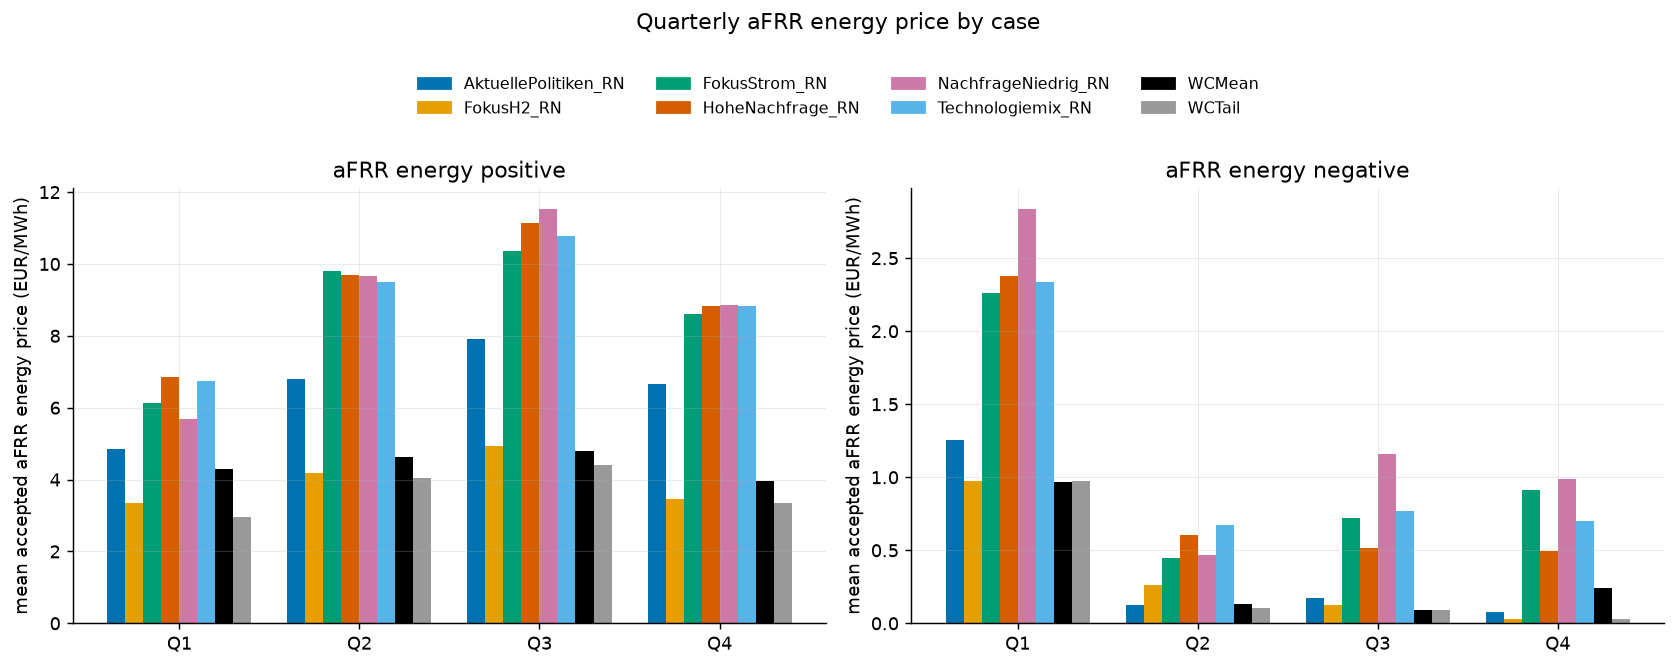

In [23]:
afrr_energy_panel = aiu.build_afrr_energy_panel(archives)
print(f"{len(afrr_energy_panel):,} matched (case, hour, market) aFRR-energy rows.")

cases_present_energy = [c for c in CASES if c in afrr_energy_panel["case"].unique()]
n = max(len(cases_present_energy), 1)
width = 0.8 / n

fig, axes = plt.subplots(1, 2, figsize=(13, 4.8))
for ax, market in zip(axes, aiu.AFRR_ENERGY_MARKETS):
    sub = afrr_energy_panel[afrr_energy_panel["market_id"] == market]
    piv = sub.groupby(["quarter", "case"])["price_actor"].mean().unstack("case").reindex(quarters)
    for i, case in enumerate(cases_present_energy):
        vals = piv[case] if case in piv.columns else pd.Series(np.nan, index=quarters)
        ax.bar(x + (i - (n - 1) / 2) * width, vals, width=width, color=CASE_COLOR[case])
    ax.set_xticks(x)
    ax.set_xticklabels([f"Q{q}" for q in quarters])
    ax.set_ylabel("mean accepted aFRR energy price (EUR/MWh)")
    ax.set_title(MARKET_LABEL.get(market, market))

handles = [plt.Rectangle((0, 0), 1, 1, color=CASE_COLOR[c]) for c in cases_present_energy]
fig.suptitle("Quarterly aFRR energy price by case", y=1.06)
fig.legend(handles, cases_present_energy, loc="upper center", bbox_to_anchor=(0.5, 0.98),
           ncol=4, frameon=False, fontsize=9)
fig.tight_layout(rect=[0, 0, 1, 0.92])
plt.show()

In [24]:
energy_pos = afrr_energy_panel[afrr_energy_panel["market_id"] == "CRM_energy_pos"]
energy_neg = afrr_energy_panel[afrr_energy_panel["market_id"] == "CRM_energy_neg"]
pos_by_case = energy_pos.groupby("case")["price_actor"].mean()
highest_pos_case = pos_by_case.idxmax() if not pos_by_case.empty else "n/a"
neg_level = energy_neg["price_actor"].abs().mean()
rest_mean = pos_by_case.drop(highest_pos_case).mean() if len(pos_by_case) > 1 else float("nan")

gap_pct = (pos_by_case.max() / rest_mean - 1) * 100 if rest_mean else float("nan")
display(Markdown(
    f"**Key finding:** **{highest_pos_case}** has the highest mean aFRR energy positive price "
    f"({pos_by_case.max():.1f} vs. {rest_mean:.1f} EUR/MWh average for the other cases) — a {gap_pct:.0f}% gap, "
    f"so the differences between cases on the up-regulation side are {'modest' if gap_pct < 50 else 'substantial'}. "
    f"aFRR energy negative prices have a mean magnitude of {neg_level:.3f} EUR/MWh across cases, and "
    f"(Section A7, next) the new actors supply most of its volume."
))

**Key finding:** **HoheNachfrage_RN** has the highest mean aFRR energy positive price (9.1 vs. 6.5 EUR/MWh average for the other cases) — a 41% gap, so the differences between cases on the up-regulation side are modest. aFRR energy negative prices have a mean magnitude of 0.746 EUR/MWh across cases, and (Section A7, next) the new actors supply most of its volume.

## A7. Quarterly aFRR energy negative volume: system context and each sector's share

Only the negative side — the new actors never bid into aFRR energy positive (see
Section A6), so a "positive" panel here would be a flat 0% line for all three
categories, every quarter, by construction, and isn't shown.

Left: average system-wide accepted volume in aFRR energy negative per quarter
(every participant — powerplants, storage, exchanges, existing demand, and the
new actors — summed on the demand side of each hour's clearing, which by
market balance equals the supply side; this is *not* the two sides added
together, which would double-count the same cleared MWh). Right: each
category's own accepted volume as a share of that system total, same quarters.
Two panels rather than one dual-axis plot (GW bars vs. % lines is too large a
scale mismatch, and the earlier Section A2 histogram/Section A6 chart already
established this notebook's convention of splitting mismatched scales into
side-by-side panels instead).

One striking thing this surfaces: **steel + cement + aviation/maritime
together already account for the large majority of all accepted
aFRR energy negative volume system-wide** in the scenarios finished so far — this
market looks like a fairly thin one that the new actors now dominate, not a
small addition to a large existing pool. Worth double-checking once more
cases/years are in, since it's currently based on only 2 of 8 cases.

In [25]:
share_panel = aiu.build_energy_neg_share_panel(archives)
print(f"{len(share_panel):,} scenario-hours.")

by_quarter = share_panel.groupby("quarter").agg(
    system_mw=("system_accepted_volume", "mean"),
    system_sum=("system_accepted_volume", "sum"),
    **{c: (c, "sum") for c in CATEGORIES},
).reindex(quarters)
for c in CATEGORIES:
    by_quarter[f"{c}_share_pct"] = by_quarter[c] / by_quarter["system_sum"] * 100
by_quarter[["system_mw"] + [f"{c}_share_pct" for c in CATEGORIES]].round(2)

1,606,014 scenario-hours.


,system_mw,steel_share_pct,cement_share_pct,aviation_maritime_share_pct
quarter,,,,
1,4762.65,32.25,66.44,0.0
2,5485.25,32.26,66.60,0.0
3,6176.30,32.86,66.50,0.0
4,5017.94,32.18,67.11,0.0


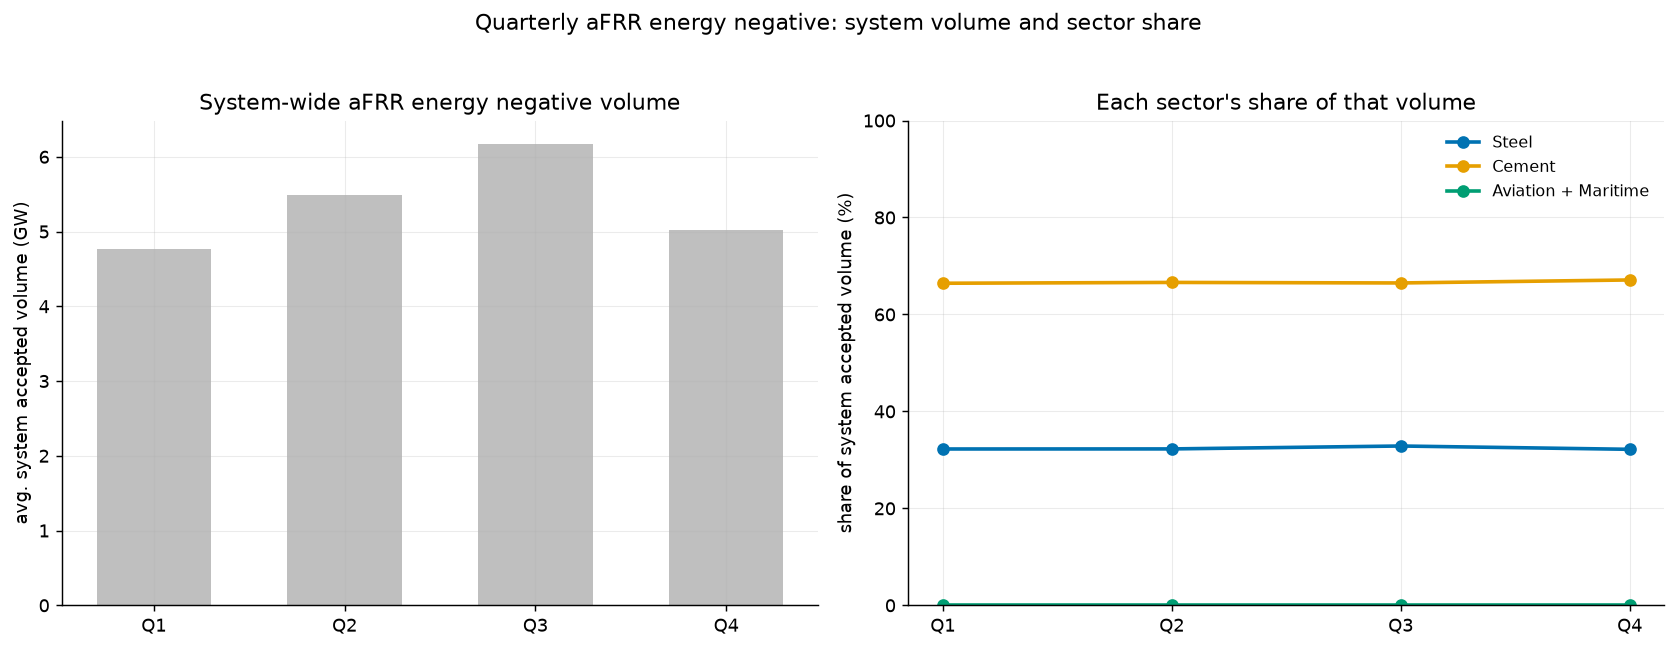

In [26]:
fig, (ax_vol, ax_share) = plt.subplots(1, 2, figsize=(13, 4.8))

ax_vol.bar([f"Q{q}" for q in quarters], by_quarter["system_mw"] / 1000,
           color="#BFBFBF", width=0.6)
ax_vol.set_ylabel("avg. system accepted volume (GW)")
ax_vol.set_title("System-wide aFRR energy negative volume")

for c in CATEGORIES:
    ax_share.plot([f"Q{q}" for q in quarters], by_quarter[f"{c}_share_pct"],
                  marker="o", color=COLOR[c], label=CATEGORY_LABEL[c], linewidth=2)
ax_share.set_ylabel("share of system accepted volume (%)")
ax_share.set_ylim(0, 100)
ax_share.set_title("Each sector's share of that volume")
ax_share.legend(frameon=False, fontsize=9)

fig.suptitle("Quarterly aFRR energy negative: system volume and sector share", y=1.03)
fig.tight_layout()
plt.show()

In [27]:
combined_share = by_quarter[[f"{c}_share_pct" for c in CATEGORIES]].sum(axis=1)
vol_start, vol_end = by_quarter["system_mw"].iloc[0], by_quarter["system_mw"].iloc[-1]
vol_change_pct = (vol_end / vol_start - 1) * 100 if vol_start else float("nan")

thin = combined_share.min() > 50
display(Markdown(
    f"**Key finding:** steel + cement + aviation/maritime together make up "
    f"**{combined_share.min():.1f}-{combined_share.max():.1f}%** of all accepted aFRR energy negative "
    f"volume system-wide across the quarters, while total system volume changes by **{vol_change_pct:+.0f}%** from Q1 to Q4. "
    + ("This market looks structurally thin: the new actors aren't a small addition to it, they're most of it."
       if thin else "The new actors are a minority of this market's volume.")
))

**Key finding:** steel + cement + aviation/maritime together make up **98.7-99.4%** of all accepted aFRR energy negative volume system-wide across the quarters, while total system volume changes by **+5%** from Q1 to Q4. This market looks structurally thin: the new actors aren't a small addition to it, they're most of it.

## A8. Combined view: system volume, actor share, and price by case (aFRR energy negative)

Puts Sections A6 and A7 on one chart, in the reference image's original layout:
gray bars are avg. system accepted volume per quarter (Section A7's left panel),
the %-label on each bar is steel + cement + aviation/maritime's **combined**
share of that volume, and the colored lines are each case's mean accepted
aFRR energy negative price per quarter (Section A6's data) plus a black `Mean` line
across cases — same pairing as the reference chart's per-scenario lines. Only
aFRR energy negative is shown, for the same reason as Section A7: the new actors
never bid into aFRR energy positive, so a second panel would just be a flat 0%.

Note this **is** a dual-axis chart (GW bars against a EUR/MWh price line
scale) — Sections A2, A5 and A6 deliberately split mismatched scales into
side-by-side panels instead, but this specific combined layout was asked for
directly, so it's built as asked here rather than substituted.

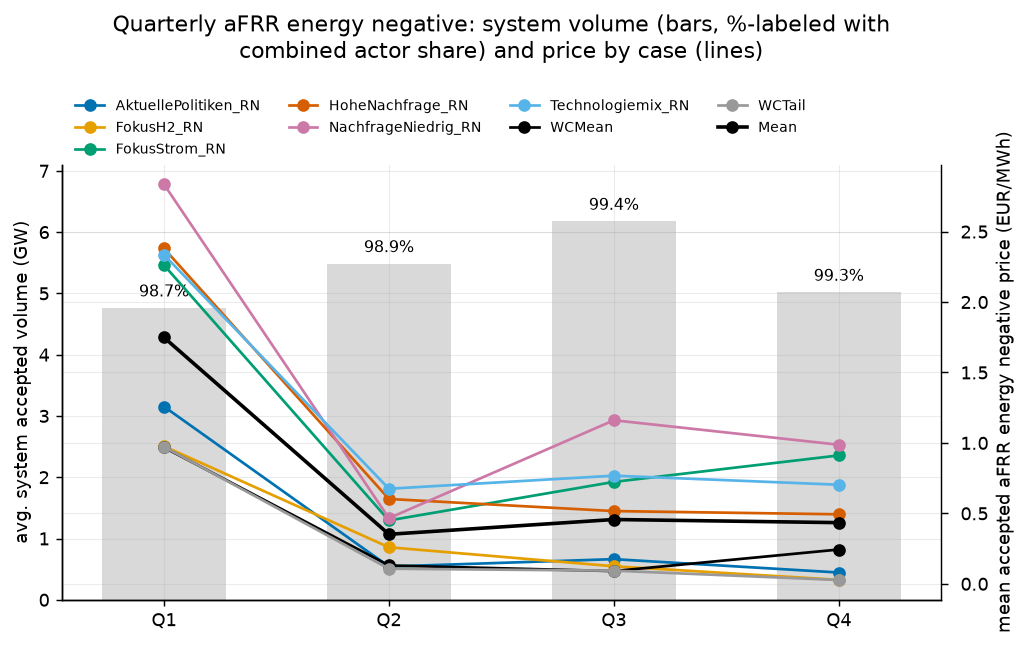

In [28]:
combined = share_panel.groupby("quarter").agg(
    system_mw=("system_accepted_volume", "mean"),
    system_sum=("system_accepted_volume", "sum"),
    **{c: (c, "sum") for c in CATEGORIES},
).reindex(quarters)
combined["actor_share_pct"] = combined[CATEGORIES].sum(axis=1) / combined["system_sum"] * 100

price_by_case = (
    afrr_energy_panel[afrr_energy_panel["market_id"] == "CRM_energy_neg"]
    .groupby(["quarter", "case"])["price_actor"].mean()
    .unstack("case").reindex(quarters)
)
price_by_case["Mean"] = price_by_case[cases_present_energy].mean(axis=1)

fig, ax1 = plt.subplots(figsize=(8, 5.2))
x = np.arange(len(quarters))
bar_vals = combined["system_mw"] / 1000
ax1.bar(x, bar_vals, color="#D9D9D9", width=0.55, zorder=1)
for xi, (val, pct) in enumerate(zip(bar_vals, combined["actor_share_pct"])):
    ax1.text(xi, val + bar_vals.max() * 0.02, f"{pct:.1f}%", ha="center", va="bottom", fontsize=9)
ax1.set_ylabel("avg. system accepted volume (GW)")
ax1.set_xticks(x)
ax1.set_xticklabels([f"Q{q}" for q in quarters])
ax1.set_ylim(0, bar_vals.max() * 1.15)

ax2 = ax1.twinx()
ax2.spines["right"].set_visible(True)
ax2.tick_params(axis="y", direction="out", length=4, pad=7)
for case in cases_present_energy:
    ax2.plot(x, price_by_case[case], marker="o", color=CASE_COLOR[case], linewidth=1.5, label=case)
ax2.plot(x, price_by_case["Mean"], marker="o", color="black", linewidth=2, label="Mean")
ax2.set_ylabel("mean accepted aFRR energy negative price (EUR/MWh)")

ax2.legend(loc="upper left", bbox_to_anchor=(0, 1.18), ncol=4, frameon=False, fontsize=8)
ax1.set_title("Quarterly aFRR energy negative: system volume (bars, %-labeled with\n"
              "combined actor share) and price by case (lines)", y=1.22)
fig.tight_layout()
plt.show()

In [29]:
share_range = f"{combined['actor_share_pct'].min():.1f}-{combined['actor_share_pct'].max():.1f}%"
case_means = price_by_case[cases_present_energy].mean()
price_spread = case_means.max() - case_means.min() if len(case_means) else float("nan")

display(Markdown(
    f"**Key finding:** the combined actor share sits at **{share_range}** of system volume across the quarters, "
    f"while aFRR energy negative prices differ between cases by about {price_spread:.3f} EUR/MWh on average — "
    f"the actors account for {'most' if combined['actor_share_pct'].min() > 50 else 'part'} of the volume in this market; "
    f"see Section A2 for how the day-ahead price responds."
))

**Key finding:** the combined actor share sits at **98.7-99.4%** of system volume across the quarters, while aFRR energy negative prices differ between cases by about 1.063 EUR/MWh on average — the actors account for most of the volume in this market; see Section A2 for how the day-ahead price responds.

## A9. Redispatch volume/cost and renewable curtailment by case

A system-level view rather than an actor-specific one: `market_id == "redispatch"`
in `market_orders.csv` covers every unit (not just steel/cement/aviation), and
renewable curtailment here means wind/solar units whose output was cut downward
via redispatch for grid congestion — identified by cross-referencing each
scenario's own `powerplant_units.csv` (`technology` in `solar`, `onshore wind`,
`offshore wind AC/DC`) against `unit_id` in the redispatch rows.

Same balance check as aFRR energy negative (Section A7): upward and downward
redispatch instructions balance system-wide per hour (every MW dispatched up
somewhere is matched by an equal MW dispatched down elsewhere), so
**redispatch volume and its cost are computed from the upward side only** —
summing both sides would double-count the same congestion-relief action.
Curtailment doesn't need this adjustment; it's inherently one-sided (only the
downward cut matters).

Each case's bars/lines average over whatever family/year scenarios have
finished for it so far (not a single fixed year) — same convention as
Sections A5, A6 and A8.

In [30]:
redispatch_panel = aiu.build_redispatch_panel(archives)
print(f"{len(redispatch_panel):,} scenarios with a redispatch summary.")

case_summary = (
    redispatch_panel.groupby("case")[
        ["redispatch_volume_twh", "avg_redispatch_cost"] + [f"{t}_curtailment_twh" for t in aiu.CURTAILMENT_SOURCES]
    ]
    .mean()
    .reindex(CASES)
    .dropna(how="all")
)
case_summary.round(2)

192 scenarios with a redispatch summary.


,redispatch_volume_twh,avg_redispatch_cost,Wind Offshore_curtailment_twh,Wind Onshore_curtailment_twh,Solar PV_curtailment_twh
case,,,,,
AktuellePolitiken_RN,99.89,5.77,13.20,23.17,36.01
FokusH2_RN,100.26,5.10,13.66,23.80,35.43
FokusStrom_RN,100.60,5.67,13.16,23.62,37.43
HoheNachfrage_RN,101.94,8.49,12.95,23.05,37.62
NachfrageNiedrig_RN,101.73,9.17,12.48,23.07,37.56
Technologiemix_RN,100.78,8.22,12.65,22.57,37.54
WCMean,100.57,5.42,13.97,24.43,36.29
WCTail,100.58,4.37,13.76,24.14,35.78


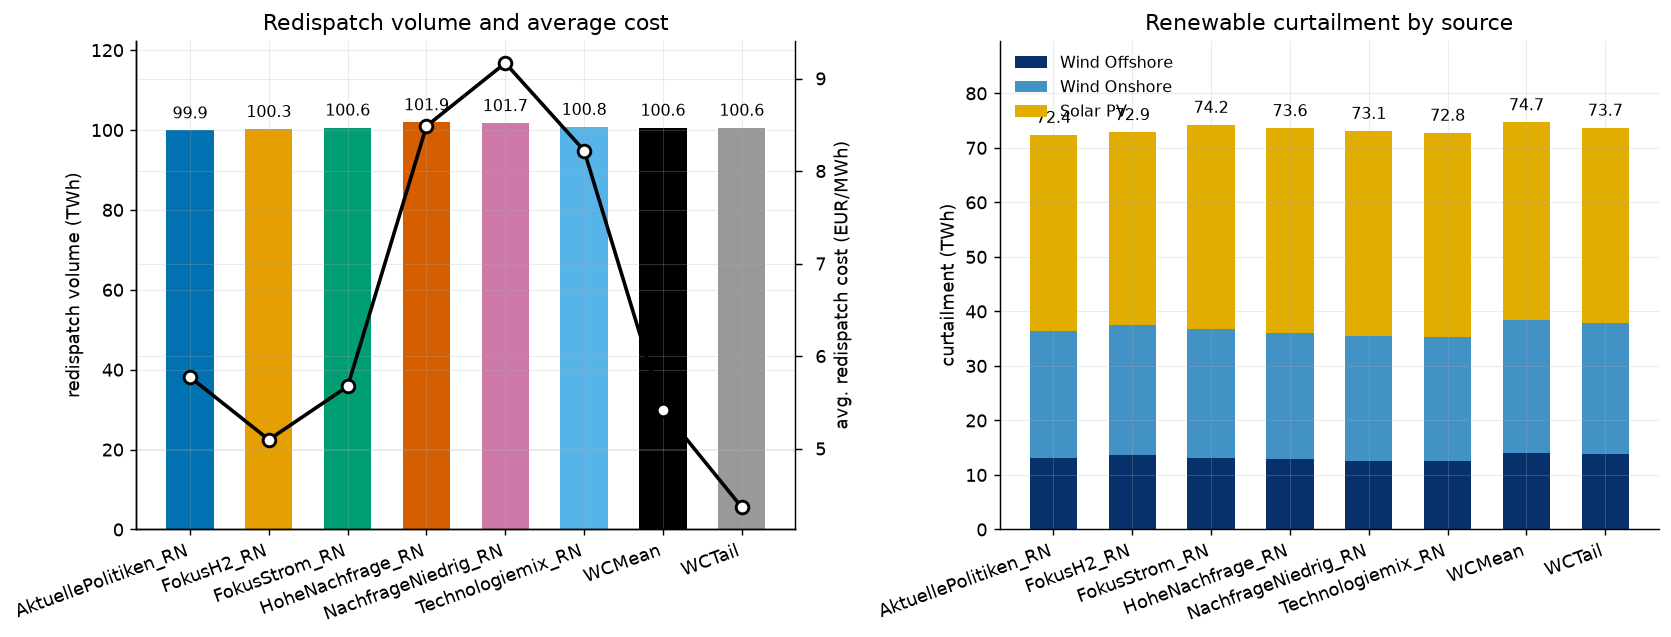

In [31]:
cases_rd = list(case_summary.index)
x = np.arange(len(cases_rd))

fig, (ax_rd, ax_ct) = plt.subplots(1, 2, figsize=(13, 5))

bars = ax_rd.bar(x, case_summary["redispatch_volume_twh"],
                  color=[CASE_COLOR[c] for c in cases_rd], width=0.6)
for xi, val in zip(x, case_summary["redispatch_volume_twh"]):
    ax_rd.text(xi, val + case_summary["redispatch_volume_twh"].max() * 0.02, f"{val:.1f}",
               ha="center", va="bottom", fontsize=9)
ax_rd.set_ylabel("redispatch volume (TWh)")
ax_rd.set_xticks(x)
ax_rd.set_xticklabels(cases_rd, rotation=20, ha="right")
ax_rd.set_ylim(0, case_summary["redispatch_volume_twh"].max() * 1.2)

ax_rd2 = ax_rd.twinx()
ax_rd2.spines["right"].set_visible(True)
ax_rd2.tick_params(axis="y", direction="out", length=4, pad=7)
ax_rd2.plot(x, case_summary["avg_redispatch_cost"], marker="o", color="black", linewidth=2,
            markerfacecolor="white", markeredgecolor="black", markeredgewidth=1.6, markersize=7, zorder=5)
ax_rd2.set_ylabel("avg. redispatch cost (EUR/MWh)")
ax_rd.set_title("Redispatch volume and average cost")

bottom = np.zeros(len(cases_rd))
for src in aiu.CURTAILMENT_SOURCES:
    vals = case_summary[f"{src}_curtailment_twh"].values
    ax_ct.bar(x, vals, bottom=bottom, color=SOURCE_COLOR[src], label=src, width=0.6)
    bottom += vals
for xi, val in zip(x, bottom):
    ax_ct.text(xi, val + bottom.max() * 0.02, f"{val:.1f}", ha="center", va="bottom", fontsize=9)
ax_ct.set_ylabel("curtailment (TWh)")
ax_ct.set_xticks(x)
ax_ct.set_xticklabels(cases_rd, rotation=20, ha="right")
ax_ct.set_ylim(0, bottom.max() * 1.2)
ax_ct.set_title("Renewable curtailment by source")
ax_ct.legend(frameon=False, fontsize=9)

fig.tight_layout()
plt.show()

In [32]:
biggest_source = (
    case_summary[[f"{s}_curtailment_twh" for s in aiu.CURTAILMENT_SOURCES]].sum().idxmax().replace("_curtailment_twh", "")
)
lowest_vol_case = case_summary["redispatch_volume_twh"].idxmin()
highest_cost_case = case_summary["avg_redispatch_cost"].idxmax()
same_case = lowest_vol_case == highest_cost_case

cost_clause = (
    f"it also has the highest average redispatch cost of any case "
    f"({case_summary.loc[highest_cost_case, 'avg_redispatch_cost']:.1f} EUR/MWh)"
    if same_case else
    f"while **{highest_cost_case}** has the highest average redispatch cost "
    f"({case_summary.loc[highest_cost_case, 'avg_redispatch_cost']:.1f} EUR/MWh)"
)
src_tot = case_summary[[f"{s}_curtailment_twh" for s in aiu.CURTAILMENT_SOURCES]].sum()
biggest_share = src_tot[f"{biggest_source}_curtailment_twh"] / src_tot.sum()
n_neg_cost = int((redispatch_panel["avg_redispatch_cost"] < 0).sum())
n_all_cost = len(redispatch_panel)
trace_note = (" (the most negative one traces to storage bids at a fixed -500 EUR/MWh)"
              if TREATMENT == "price-taker" and n_neg_cost else "")
display(Markdown(
    f"**Key finding:** {biggest_source} is the largest curtailed renewable source, "
    f"{biggest_share:.0%} of all curtailment across the cases. "
    f"**{lowest_vol_case}** has the lowest redispatch volume "
    f"({case_summary.loc[lowest_vol_case, 'redispatch_volume_twh']:.0f} TWh) -- {cost_clause}. "
    f"Average cost is a volume-weighted price on the upward side; {n_neg_cost} of {n_all_cost} scenarios have a negative "
    f"average{trace_note}, so read it together with volume rather than as a pure cost ranking."
))

**Key finding:** Solar PV is the largest curtailed renewable source, 50% of all curtailment across the cases. **AktuellePolitiken_RN** has the lowest redispatch volume (100 TWh) -- while **NachfrageNiedrig_RN** has the highest average redispatch cost (9.2 EUR/MWh). Average cost is a volume-weighted price on the upward side; 12 of 192 scenarios have a negative average (the most negative one traces to storage bids at a fixed -500 EUR/MWh), so read it together with volume rather than as a pure cost ranking.

## A10. Cross-case summary: price impact and risk attitude

The headline question this whole notebook is really asking: **how much do
these hard-to-abate sectors move electricity prices, and does that depend on
how conservatively the actors sized their own demand?**

All 8 cases -- 6 risk-neutral (`_RN`) plus the two risk-averse ones (`WCMean`,
`WCTail`) -- are simulated against the *same* 6 families. The difference
isn't how many futures each case is tested against (it's always all 6); it's
*how the actor's demand decision was derived* before that stress test: an
`_RN` case commits to one fixed demand profile per year (identical across all
6 family subfolders, per the scenario design), while `WCMean`/`WCTail` derive
their demand from the mean/tail of the outcome distribution *across* those
same 6 families. So the chart below doesn't impose a "single dot vs. a
spread" distinction by design -- every case gets one point per finished
family, and the **width of that spread is itself the risk-attitude finding**:
a tight cluster means this case's committed demand produces a consistent
price effect regardless of which future materializes; a wide spread means
the realized impact is highly sensitive to that guess.

All 8 cases have all 6 families finished, so every spread below is a full 6-family spread.

Families finished per case (out of 6):
case
AktuellePolitiken_RN    6
FokusH2_RN              6
FokusStrom_RN           6
HoheNachfrage_RN        6
NachfrageNiedrig_RN     6
Technologiemix_RN       6
WCMean                  6
WCTail                  6
Name: family, dtype: int64


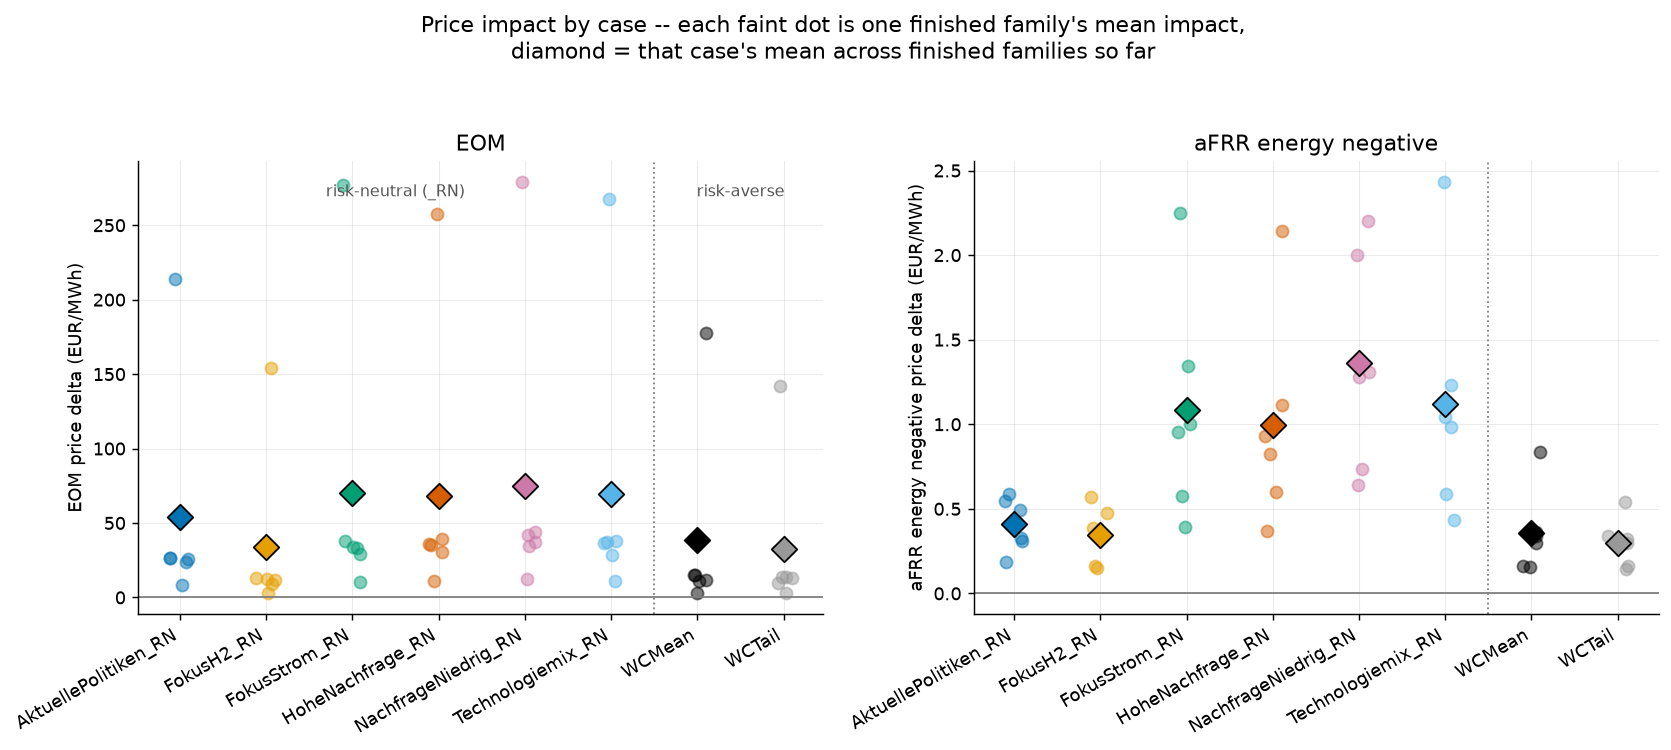

In [33]:
case_family_price = price_panel.groupby(["case", "family", "market_id"])["delta"].mean().reset_index()

case_order = [c for c in CASES if c in case_family_price["case"].unique()]
print("Families finished per case (out of 6):")
print(case_family_price[case_family_price["market_id"] == "EOM"].groupby("case")["family"].nunique()
      .reindex(case_order))

rn_present = [c for c in case_order if c in RN_LIKE]
wc_present = [c for c in case_order if c not in RN_LIKE]
divider_x = len(rn_present) - 0.5  # dynamic: only meaningful once both groups have data

rng = np.random.default_rng(0)
fig, axes = plt.subplots(1, 2, figsize=(13, 5.5))
for ax, market in zip(axes, ["EOM", "CRM_energy_neg"]):
    sub = case_family_price[case_family_price["market_id"] == market]
    for i, c in enumerate(case_order):
        vals = sub.loc[sub["case"] == c, "delta"].values
        if len(vals) == 0:
            continue
        jitter = rng.uniform(-0.12, 0.12, size=len(vals))
        ax.scatter(np.full(len(vals), i) + jitter, vals, color=CASE_COLOR[c], alpha=0.5, s=45, zorder=2)
        ax.scatter([i], [vals.mean()], color=CASE_COLOR[c], marker="D", s=100,
                   edgecolor="black", linewidth=1, zorder=3)
    ax.axhline(0, color=COLOR["baseline"], linewidth=1)
    if rn_present and wc_present:
        ax.axvline(divider_x, color=COLOR["baseline"], linewidth=1, linestyle=":")
    ax.set_xticks(range(len(case_order)))
    ax.set_xticklabels(case_order, rotation=30, ha="right")
    ax.set_ylabel(f"{MARKET_LABEL.get(market, market)} price delta (EUR/MWh)")
    ax.set_title(MARKET_LABEL.get(market, market))
if rn_present and wc_present:
    y0, y1 = axes[0].get_ylim()
    axes[0].text((len(rn_present) - 1) / 2, y1 * 0.92, "risk-neutral (_RN)",
                 ha="center", fontsize=9, color="#555")
    axes[0].text(len(rn_present) + (len(wc_present) - 1) / 2, y1 * 0.92, "risk-averse",
                 ha="center", fontsize=9, color="#555")
fig.suptitle("Price impact by case -- each faint dot is one finished family's mean impact,\n"
             "diamond = that case's mean across finished families so far", y=1.04)
fig.tight_layout()
plt.show()

In [34]:
eom_stats = (
    case_family_price[case_family_price["market_id"] == "EOM"]
    .groupby("case")["delta"].agg(["mean", "std", "count"])
    .reindex(case_order).dropna()
)
widest = eom_stats["std"].idxmax() if eom_stats["std"].notna().any() else None
rn_mean = eom_stats.loc[eom_stats.index.isin(rn_present), "mean"].mean() if rn_present else float("nan")
wc_mean = eom_stats.loc[eom_stats.index.isin(wc_present), "mean"].mean() if wc_present else float("nan")

msg = "**Key finding:** "
if widest is not None:
    msg += (
        f"**{widest}** currently shows the widest spread in EOM impact across its finished "
        f"families (std = {eom_stats.loc[widest, 'std']:.1f} EUR/MWh over "
        f"{int(eom_stats.loc[widest, 'count'])} families) — its committed demand level is highly "
        f"sensitive to which future actually plays out. "
    )
if wc_present and rn_present:
    typical_std = eom_stats["std"].mean()
    gap = rn_mean - wc_mean
    verdict = (
        "a gap smaller than the typical within-case spread, so no clear risk-attitude effect is visible"
        if abs(gap) < typical_std else
        ("risk-averse cases sit clearly lower" if gap > 0 else "risk-averse cases sit clearly higher")
    )
    msg += (
        f"The risk-averse case(s) ({', '.join(wc_present)}) average **{wc_mean:.1f} EUR/MWh** mean "
        f"impact vs. **{rn_mean:.1f} EUR/MWh** for the risk-neutral cases — a difference of "
        f"{gap:+.1f} against a typical within-case spread of {typical_std:.1f} EUR/MWh: {verdict}. "
        f"Run-to-run noise with identical inputs is quantified in Section A12."
    )
else:
    msg += "The risk-neutral-vs-hedged comparison isn't meaningful yet — one side has no finished data."
display(Markdown(msg))

**Key finding:** **FokusStrom_RN** currently shows the widest spread in EOM impact across its finished families (std = 101.8 EUR/MWh over 6 families) — its committed demand level is highly sensitive to which future actually plays out. The risk-averse case(s) (WCMean, WCTail) average **35.7 EUR/MWh** mean impact vs. **61.8 EUR/MWh** for the risk-neutral cases — a difference of +26.1 against a typical within-case spread of 81.6 EUR/MWh: a gap smaller than the typical within-case spread, so no clear risk-attitude effect is visible. Run-to-run noise with identical inputs is quantified in Section A12.

### The same view, year by year

Each row is one year, with the same cases, the same dot-per-family and diamond-per-case encoding, and **its own y-axis in every panel**: on a shared axis the 2040 outlier (about 700 EUR/MWh) flattens every other year, so read values from the ticks and do not compare bar heights across rows by eye. A dot is one family's mean impact in that year (6 dots per case per year).

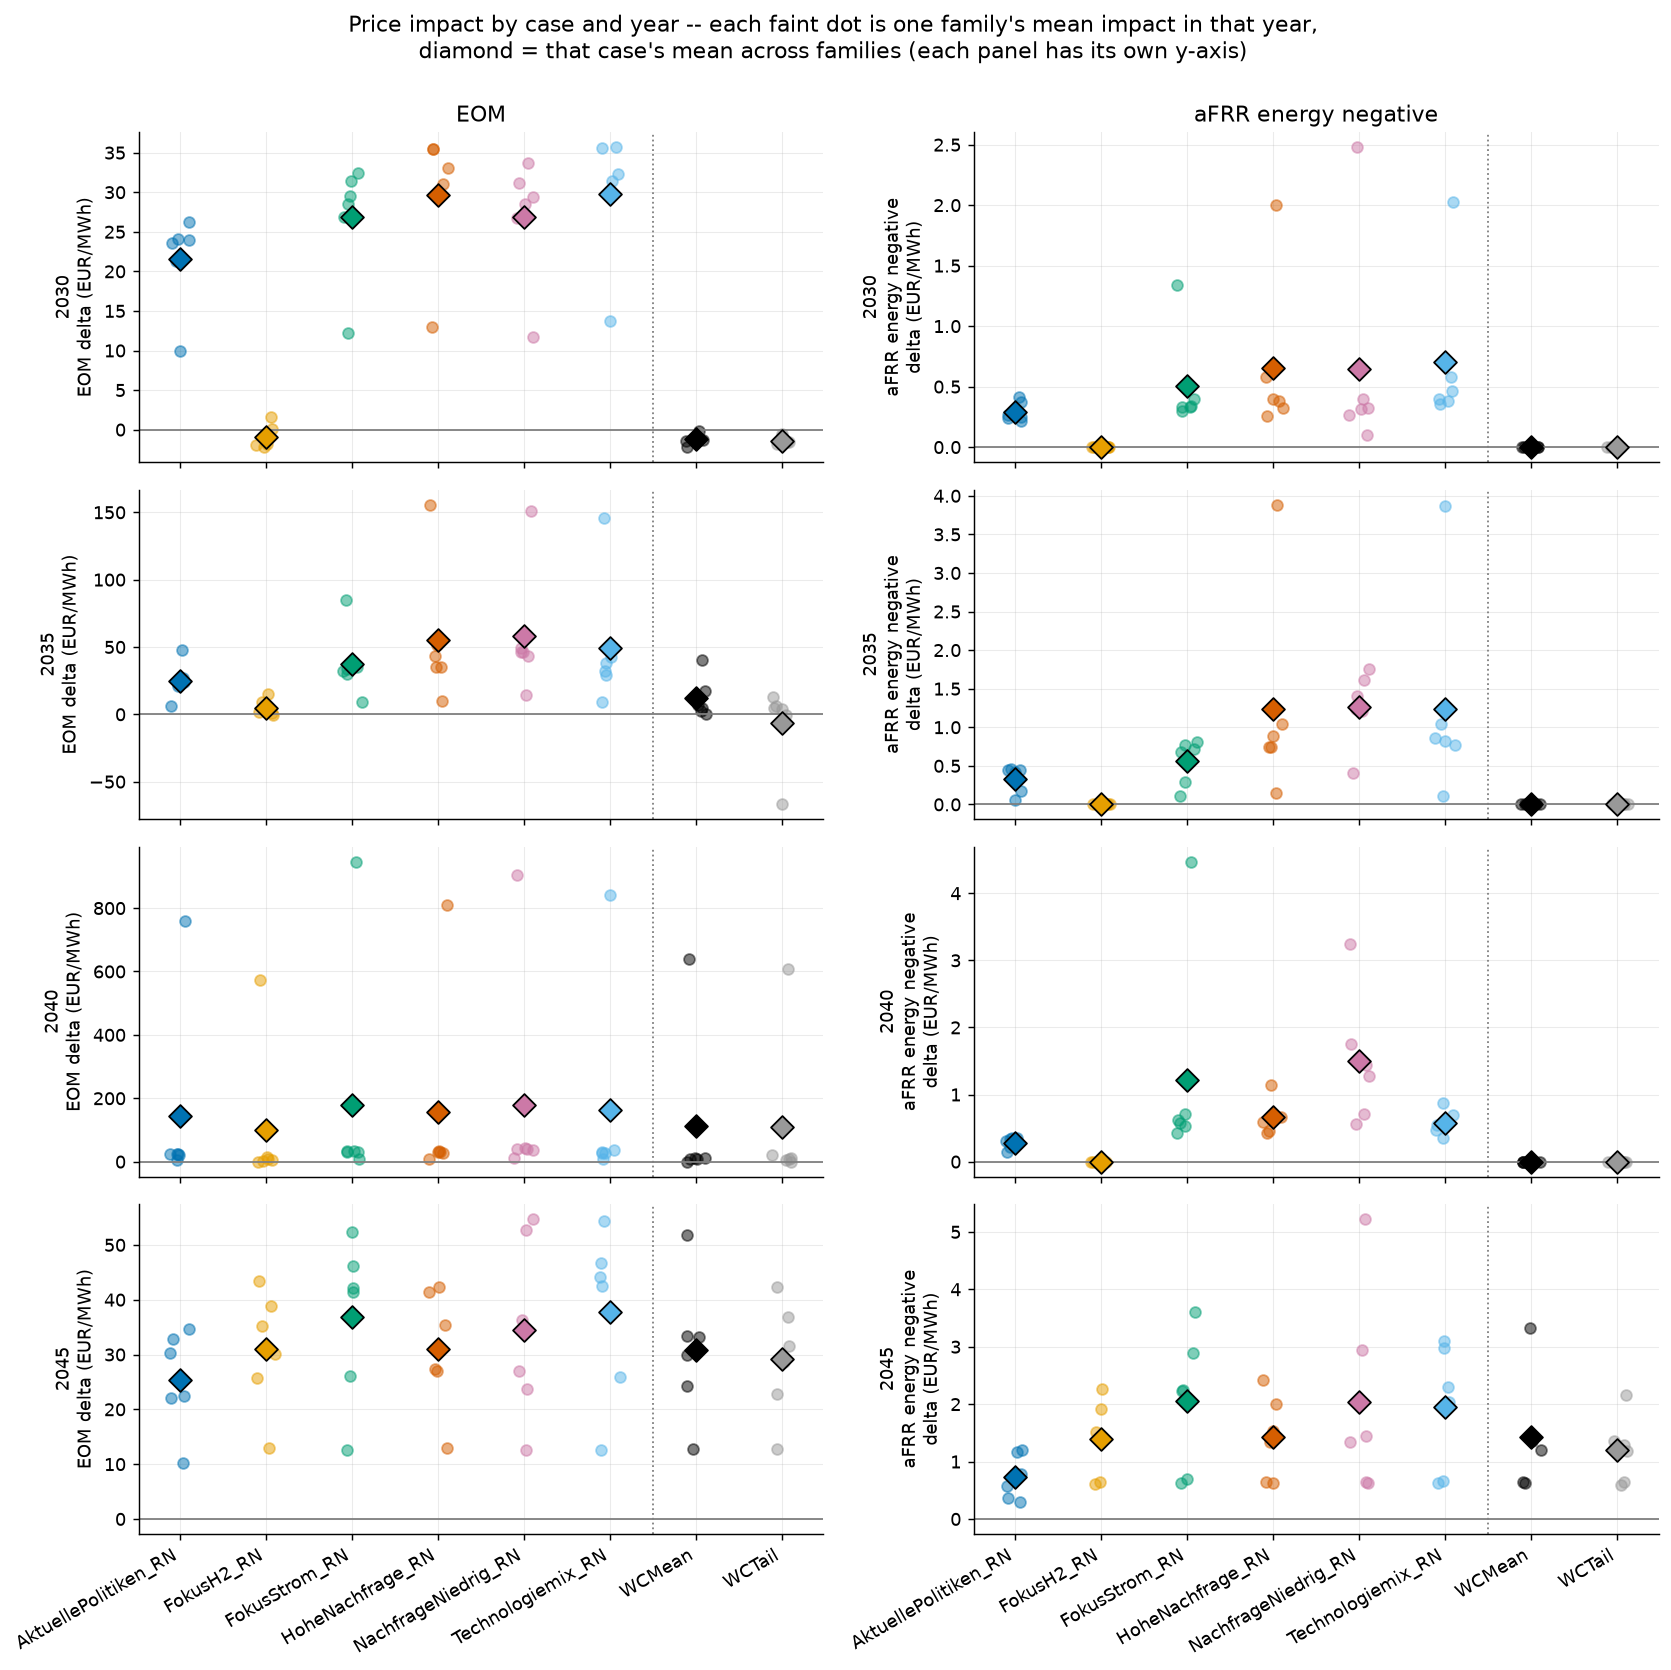

In [35]:
case_family_year = price_panel.groupby(["case", "family", "year", "market_id"])["delta"].mean().reset_index()
years_cf = sorted(case_family_year["year"].unique())
markets_cf = ["EOM", "CRM_energy_neg"]

rng_y = np.random.default_rng(1)
fig, axes = plt.subplots(len(years_cf), 2, figsize=(13, 3.2 * len(years_cf)), sharex=True, sharey=False)
for r, yr in enumerate(years_cf):
    for c_idx, market in enumerate(markets_cf):
        ax = axes[r, c_idx]
        sub = case_family_year[(case_family_year["year"] == yr) & (case_family_year["market_id"] == market)]
        for i, c in enumerate(case_order):
            vals = sub.loc[sub["case"] == c, "delta"].values
            if len(vals) == 0:
                continue
            jitter = rng_y.uniform(-0.12, 0.12, size=len(vals))
            ax.scatter(np.full(len(vals), i) + jitter, vals, color=CASE_COLOR[c], alpha=0.5, s=36, zorder=2)
            ax.scatter([i], [vals.mean()], color=CASE_COLOR[c], marker="D", s=80, edgecolor="black", linewidth=1, zorder=3)
        ax.axhline(0, color=COLOR["baseline"], linewidth=1)
        if rn_present and wc_present:
            ax.axvline(divider_x, color=COLOR["baseline"], linewidth=1, linestyle=":")
        ax.grid(alpha=0.25)
        if c_idx == 0:
            ax.set_ylabel(f"{yr}\nEOM delta (EUR/MWh)")
        else:
            ax.set_ylabel(f"{yr}\naFRR energy negative\ndelta (EUR/MWh)")
        if r == 0:
            ax.set_title(MARKET_LABEL.get(market, market))
for ax in axes[-1]:
    ax.set_xticks(range(len(case_order)))
    ax.set_xticklabels(case_order, rotation=30, ha="right")
fig.suptitle("Price impact by case and year -- each faint dot is one family's mean impact in that year,\n"
             "diamond = that case's mean across families (each panel has its own y-axis)", y=1.0)
fig.tight_layout()
plt.show()


In [36]:
eom_cfy = case_family_year[case_family_year["market_id"] == "EOM"]
eom_fy = eom_cfy.groupby(["family", "year"])["delta"].mean()
year_means = eom_fy.groupby("year").mean()
top_f, top_y = eom_fy.idxmax()
without_top = eom_fy.drop((top_f, top_y))
per_case_top = eom_cfy.groupby(["case", "family", "year"])["delta"].mean().groupby("case").idxmax()
n_top = sum((t[1], t[2]) == (top_f, top_y) for t in per_case_top)

sub_top = price_panel[(price_panel["market_id"] == "EOM") & (price_panel["family"] == top_f) & (price_panel["year"] == top_y)]
base_hours = int((sub_top[sub_top["case"] == sub_top["case"].iloc[0]]["price_baseline"] >= 1000).sum())
actor_hours = sub_top.groupby("case")["price_actor"].apply(lambda s: int((s >= 1000).sum()))
outlier = eom_fy.max() > 3 * max(without_top.max(), 1e-9)

text = (
    "**Key finding:** the all-case mean EOM impact by year is "
    + ", ".join(f"{y}: **{v:+.1f}**" for y, v in year_means.items())
    + f" EUR/MWh. The largest single family-year is **{top_f} {top_y}** (mean impact {eom_fy.max():+.0f} EUR/MWh), "
    f"the largest of its case's family-years in {n_top} of {len(per_case_top)} cases; without it the pooled mean impact over "
    f"all other family-years is {without_top.mean():+.1f} instead of {eom_fy.mean():+.1f} EUR/MWh. "
    f"In that system the no-actor baseline has {base_hours} hours at or above 1,000 EUR/MWh (price cap 3,000) and with the "
    f"actors {actor_hours.min():,}-{actor_hours.max():,} such hours depending on the case "
    f"({actor_hours.min() / 87.6:.0f}-{actor_hours.max() / 87.6:.0f}% of the year)."
)
if outlier:
    text += " That one system pulls the diamonds up, so the dots describe a typical year better than the means."
display(Markdown(text))


**Key finding:** the all-case mean EOM impact by year is 2030: **+16.4**, 2035: **+29.5**, 2040: **+143.2**, 2045: **+32.1** EUR/MWh. The largest single family-year is **fokusH2 2040** (mean impact +761 EUR/MWh), the largest of its case's family-years in 8 of 8 cases; without it the pooled mean impact over all other family-years is +24.6 instead of +55.3 EUR/MWh. In that system the no-actor baseline has 124 hours at or above 1,000 EUR/MWh (price cap 3,000) and with the actors 1,286-3,125 such hours depending on the case (15-36% of the year). That one system pulls the diamonds up, so the dots describe a typical year better than the means.

## A11. Grid maps at one timestep: congestion, redispatch, and the result

Three views of the **same hour** for every case of this part (same family and year, so the only
difference between panels is the case): line loading **before** redispatch, the redispatch
itself (net change per node, blue = upward, red = downward), and line loading **after**.

How the three are obtained, and what to keep in mind:
- **Before:** `grid_line_loading.csv` is written from the linear power flow of the market
  dispatch *before* the redispatch optimisation, so it is read as-is (loading = |flow| / `s_nom`).
- **Redispatch:** accepted `redispatch` orders summed per node (`node` column). Upward and
  downward volumes balance system-wide per hour, so the per-node *net* is what moves flows.
- **After:** the output does not store post-redispatch flows, so they are reconstructed as
  pre-redispatch flow + PTDF x net nodal redispatch (DC power-transfer matrix of the 94 lines,
  all 380 kV AC). The cell below validates this: over every congested hour of every case the
  worst line must come back to 100% loading, and it does not with the opposite sign.
- **Resolution:** the grid has 30 German nodes (44 buses incl. neighbours), not the
  hundreds of nodes of a detailed model, so bubbles and plants sit at node level and a
  node's bubble aggregates all units there. Plants are drawn at their node, not their site.
  The Germany outline is a coarse Natural Earth polygon.
- The hour is chosen automatically as the one congested in the most cases with the largest
  combined overload; set `TS` below to look at another hour (for example a windy hour, to
  see the usual north-down / south-up pattern instead).

In [37]:
import os
import geopandas as gpd
import pyogrio
from matplotlib.lines import Line2D

FAMILY, YEAR = "aktuellepolitiken", 2035
TS = None  # e.g. pd.Timestamp("2035-01-28 20:00"); None = auto-select

arch_g = archives[(archives["family"] == FAMILY) & (archives["year"] == YEAR)].set_index("case")
cases_g = [c for c in CASES if c in arch_g.index]

buses_g, lines_g = aiu.load_grid(cases_g[0], FAMILY, YEAR)
max_load = pd.DataFrame({
    c: (aiu.load_line_flows(c, FAMILY, YEAR, arch_g.loc[c, "path"]).abs()
        / lines_g["s_nom"].reindex(aiu.load_line_flows(c, FAMILY, YEAR, arch_g.loc[c, "path"]).columns).to_numpy()).max(axis=1)
    for c in cases_g
})
if TS is None:
    n_cong = (max_load > 1).sum(axis=1)
    overload = (max_load.clip(lower=1) - 1).sum(axis=1)
    TS = (pd.DataFrame({"n": n_cong, "o": overload}).sort_values(["n", "o"], ascending=False).index[0])
TS = pd.Timestamp(TS)
print(f"{FAMILY} {YEAR}, hour {TS}: congested in {(max_load.loc[TS] > 1).sum()} of {len(cases_g)} cases")

snaps = {c: aiu.grid_snapshot(c, FAMILY, YEAR, arch_g.loc[c, "path"], TS) for c in cases_g}

# validation of the post-redispatch reconstruction over all congested hours (one case)
c0 = cases_g[0]
fl = aiu.load_line_flows(c0, FAMILY, YEAR, arch_g.loc[c0, "path"])
rd0 = aiu.load_redispatch_nodal(c0, FAMILY, YEAR, arch_g.loc[c0, "path"])
b0, l0 = aiu.load_grid(c0, FAMILY, YEAR)
P0 = aiu.build_ptdf(b0, l0)
net0 = rd0.pivot_table(index="start_time", columns="node", values="net", aggfunc="sum").reindex(columns=b0["name"]).fillna(0)
ri = l0.index.get_indexer(fl.columns); cap0 = l0["s_nom"].reindex(fl.columns).to_numpy()
hrs = max_load.index[max_load[c0] > 1]
worst_after = [np.abs((fl.loc[t].to_numpy() + (P0 @ (net0.loc[t].to_numpy() if t in net0.index else np.zeros(len(b0))))[ri]) / cap0).max() for t in hrs]
worst_wrong = [np.abs((fl.loc[t].to_numpy() - (P0 @ (net0.loc[t].to_numpy() if t in net0.index else np.zeros(len(b0))))[ri]) / cap0).max() for t in hrs]
print(f"Validation on {c0}, {len(hrs)} congested hours: worst line after redispatch -> median {np.median(worst_after):.3f}, "
      f"max {np.max(worst_after):.3f}  (opposite sign: median {np.median(worst_wrong):.2f})")

aktuellepolitiken 2035, hour 2035-06-15 06:00:00: congested in 8 of 8 cases
Validation on AktuellePolitiken_RN, 364 congested hours: worst line after redispatch -> median 1.000, max 1.000  (opposite sign: median 1.23)


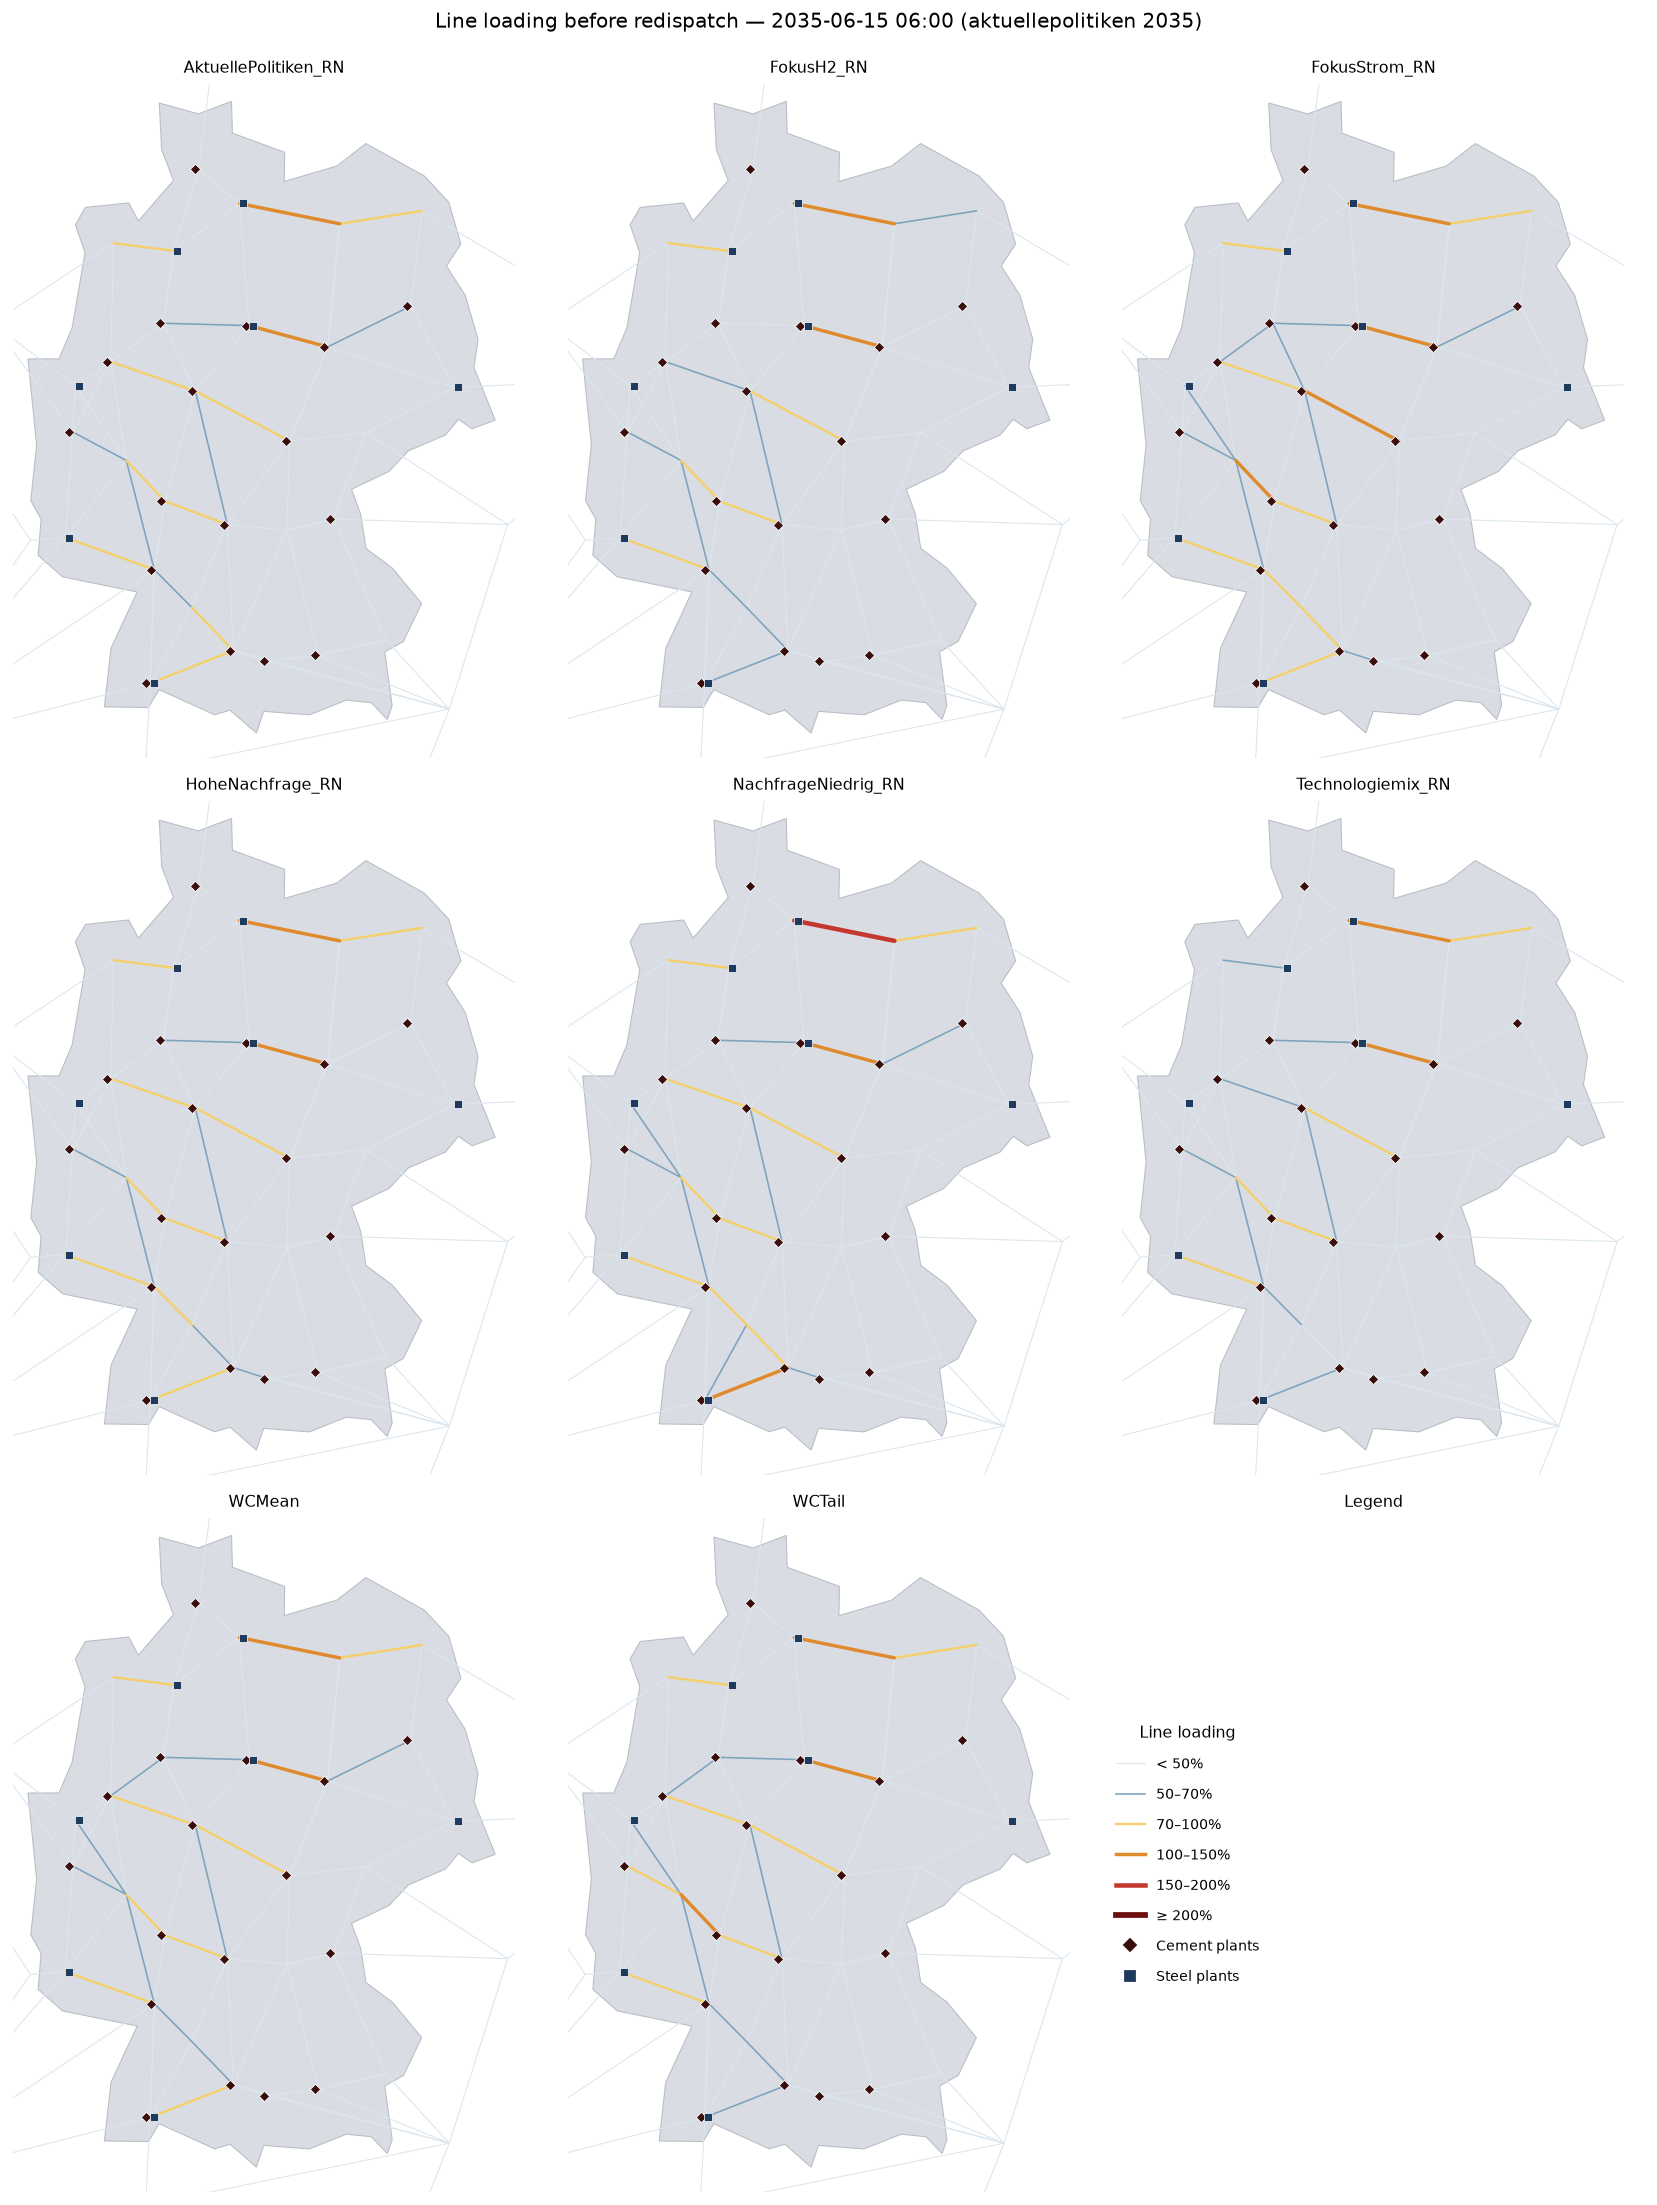

In [38]:
shp = os.path.join(os.path.dirname(pyogrio.__file__), "tests/fixtures/naturalearth_lowres/naturalearth_lowres.shp")
germany = gpd.read_file(shp).query("name == 'Germany'").geometry.iloc[0]

LOAD_BINS = [0.5, 0.7, 1.005, 1.5, 2.0]            # 1.005: float noise at exactly 100% stays in "70-100%"
LOAD_LABELS = ["< 50%", "50–70%", "70–100%", "100–150%", "150–200%", "≥ 200%"]
LOAD_COLORS = ["#dbe6ee", "#7fa3bd", "#f4cf6a", "#e08a2e", "#c4382f", "#6b0f10"]
LOAD_WIDTHS = [0.6, 0.9, 1.3, 1.9, 2.5, 3.2]
XLIM, YLIM = (5.7, 15.4), (47.0, 55.2)
UP_COLOR, DOWN_COLOR = "#2f77b5", "#d6604d"

def base_map(ax, title):
    ax.add_patch(plt.Polygon(np.array(germany.exterior.coords), fc="#d9dde3", ec="#b9bec6", lw=0.6, zorder=0))
    ax.set_xlim(*XLIM); ax.set_ylim(*YLIM); ax.set_aspect(1 / np.cos(np.radians(51)))
    ax.axis("off"); ax.set_title(title, fontsize=9)

def draw_plants(ax, s):
    pos = s["buses"].set_index("name")[["x", "y"]]
    for tech, marker, color, dx in [("cement", "D", "#3a0d0d", -0.07), ("steel", "s", "#1f3a5f", 0.07)]:
        for node in s["plants"][tech]:
            ax.scatter(pos.loc[node, "x"] + dx, pos.loc[node, "y"], marker=marker, s=16, c=color,
                       ec="white", lw=0.4, zorder=6)

def draw_loading(ax, s, key):
    pos = s["buses"].set_index("name")[["x", "y"]]
    cls = np.digitize(s[key], LOAD_BINS)
    for i in np.argsort(cls):                       # heavily loaded lines drawn last, on top
        ln = s["lines"].iloc[i]; a, b = pos.loc[ln.bus0], pos.loc[ln.bus1]
        ax.plot([a.x, b.x], [a.y, b.y], color=LOAD_COLORS[cls[i]], lw=LOAD_WIDTHS[cls[i]],
                solid_capstyle="round", zorder=2 + cls[i])
    draw_plants(ax, s)

vmax_net = max(np.abs(s["net"]).max() for s in snaps.values())
def bubble_area(v):
    return 40 + (abs(v) / vmax_net) * 700

def draw_redispatch(ax, s):
    pos = s["buses"].set_index("name")[["x", "y"]]
    for node, v in s["net"].items():
        if abs(v) >= 1:
            ax.scatter(pos.loc[node, "x"], pos.loc[node, "y"], s=bubble_area(v),
                       c=UP_COLOR if v > 0 else DOWN_COLOR, alpha=0.85, ec="white", lw=0.4, zorder=4)
    draw_plants(ax, s)

plant_handles = [Line2D([], [], marker="D", ls="", c="#3a0d0d", ms=5, label="Cement plants"),
                 Line2D([], [], marker="s", ls="", c="#1f3a5f", ms=5, label="Steel plants")]
load_handles = [Line2D([], [], color=c, lw=w, label=l) for c, w, l in zip(LOAD_COLORS, LOAD_WIDTHS, LOAD_LABELS)] + plant_handles
size_steps = [g for g in (0.5, 1, 2, 4) if g * 1000 <= vmax_net * 1.05]
rd_handles = ([Line2D([], [], marker="o", ls="", c=UP_COLOR, ms=8, label="Upward redispatch"),
               Line2D([], [], marker="o", ls="", c=DOWN_COLOR, ms=8, label="Downward redispatch")] + plant_handles +
              [Line2D([], [], marker="o", ls="", mfc="none", mec="#444", ms=np.sqrt(bubble_area(g * 1000)), label=f"{g:g} GW")
               for g in size_steps])

def grid_figure(draw, handles, legend_title, suptitle, note=None):
    fig, axes = plt.subplots(3, 3, figsize=(13, 17))
    for ax, c in zip(axes.flat, cases_g):
        base_map(ax, c); draw(ax, snaps[c])
    for ax in list(axes.flat)[len(cases_g):]:
        ax.axis("off")
    leg = axes.flat[len(cases_g)]
    leg.set_title("Legend", fontsize=9)
    leg.legend(handles=handles, title=legend_title, loc="center left", frameon=False, fontsize=8,
               title_fontsize=9, labelspacing=1.1)
    if note:
        leg.text(0.02, 0.02, note, transform=leg.transAxes, fontsize=7.5, va="bottom")
    fig.suptitle(suptitle, y=0.995, fontsize=11); fig.tight_layout()
    plt.show()

ts_label = f"{TS:%Y-%m-%d %H:%M} ({FAMILY} {YEAR})"
grid_figure(lambda ax, s: draw_loading(ax, s, "pre"), load_handles, "Line loading",
            f"Line loading before redispatch — {ts_label}")

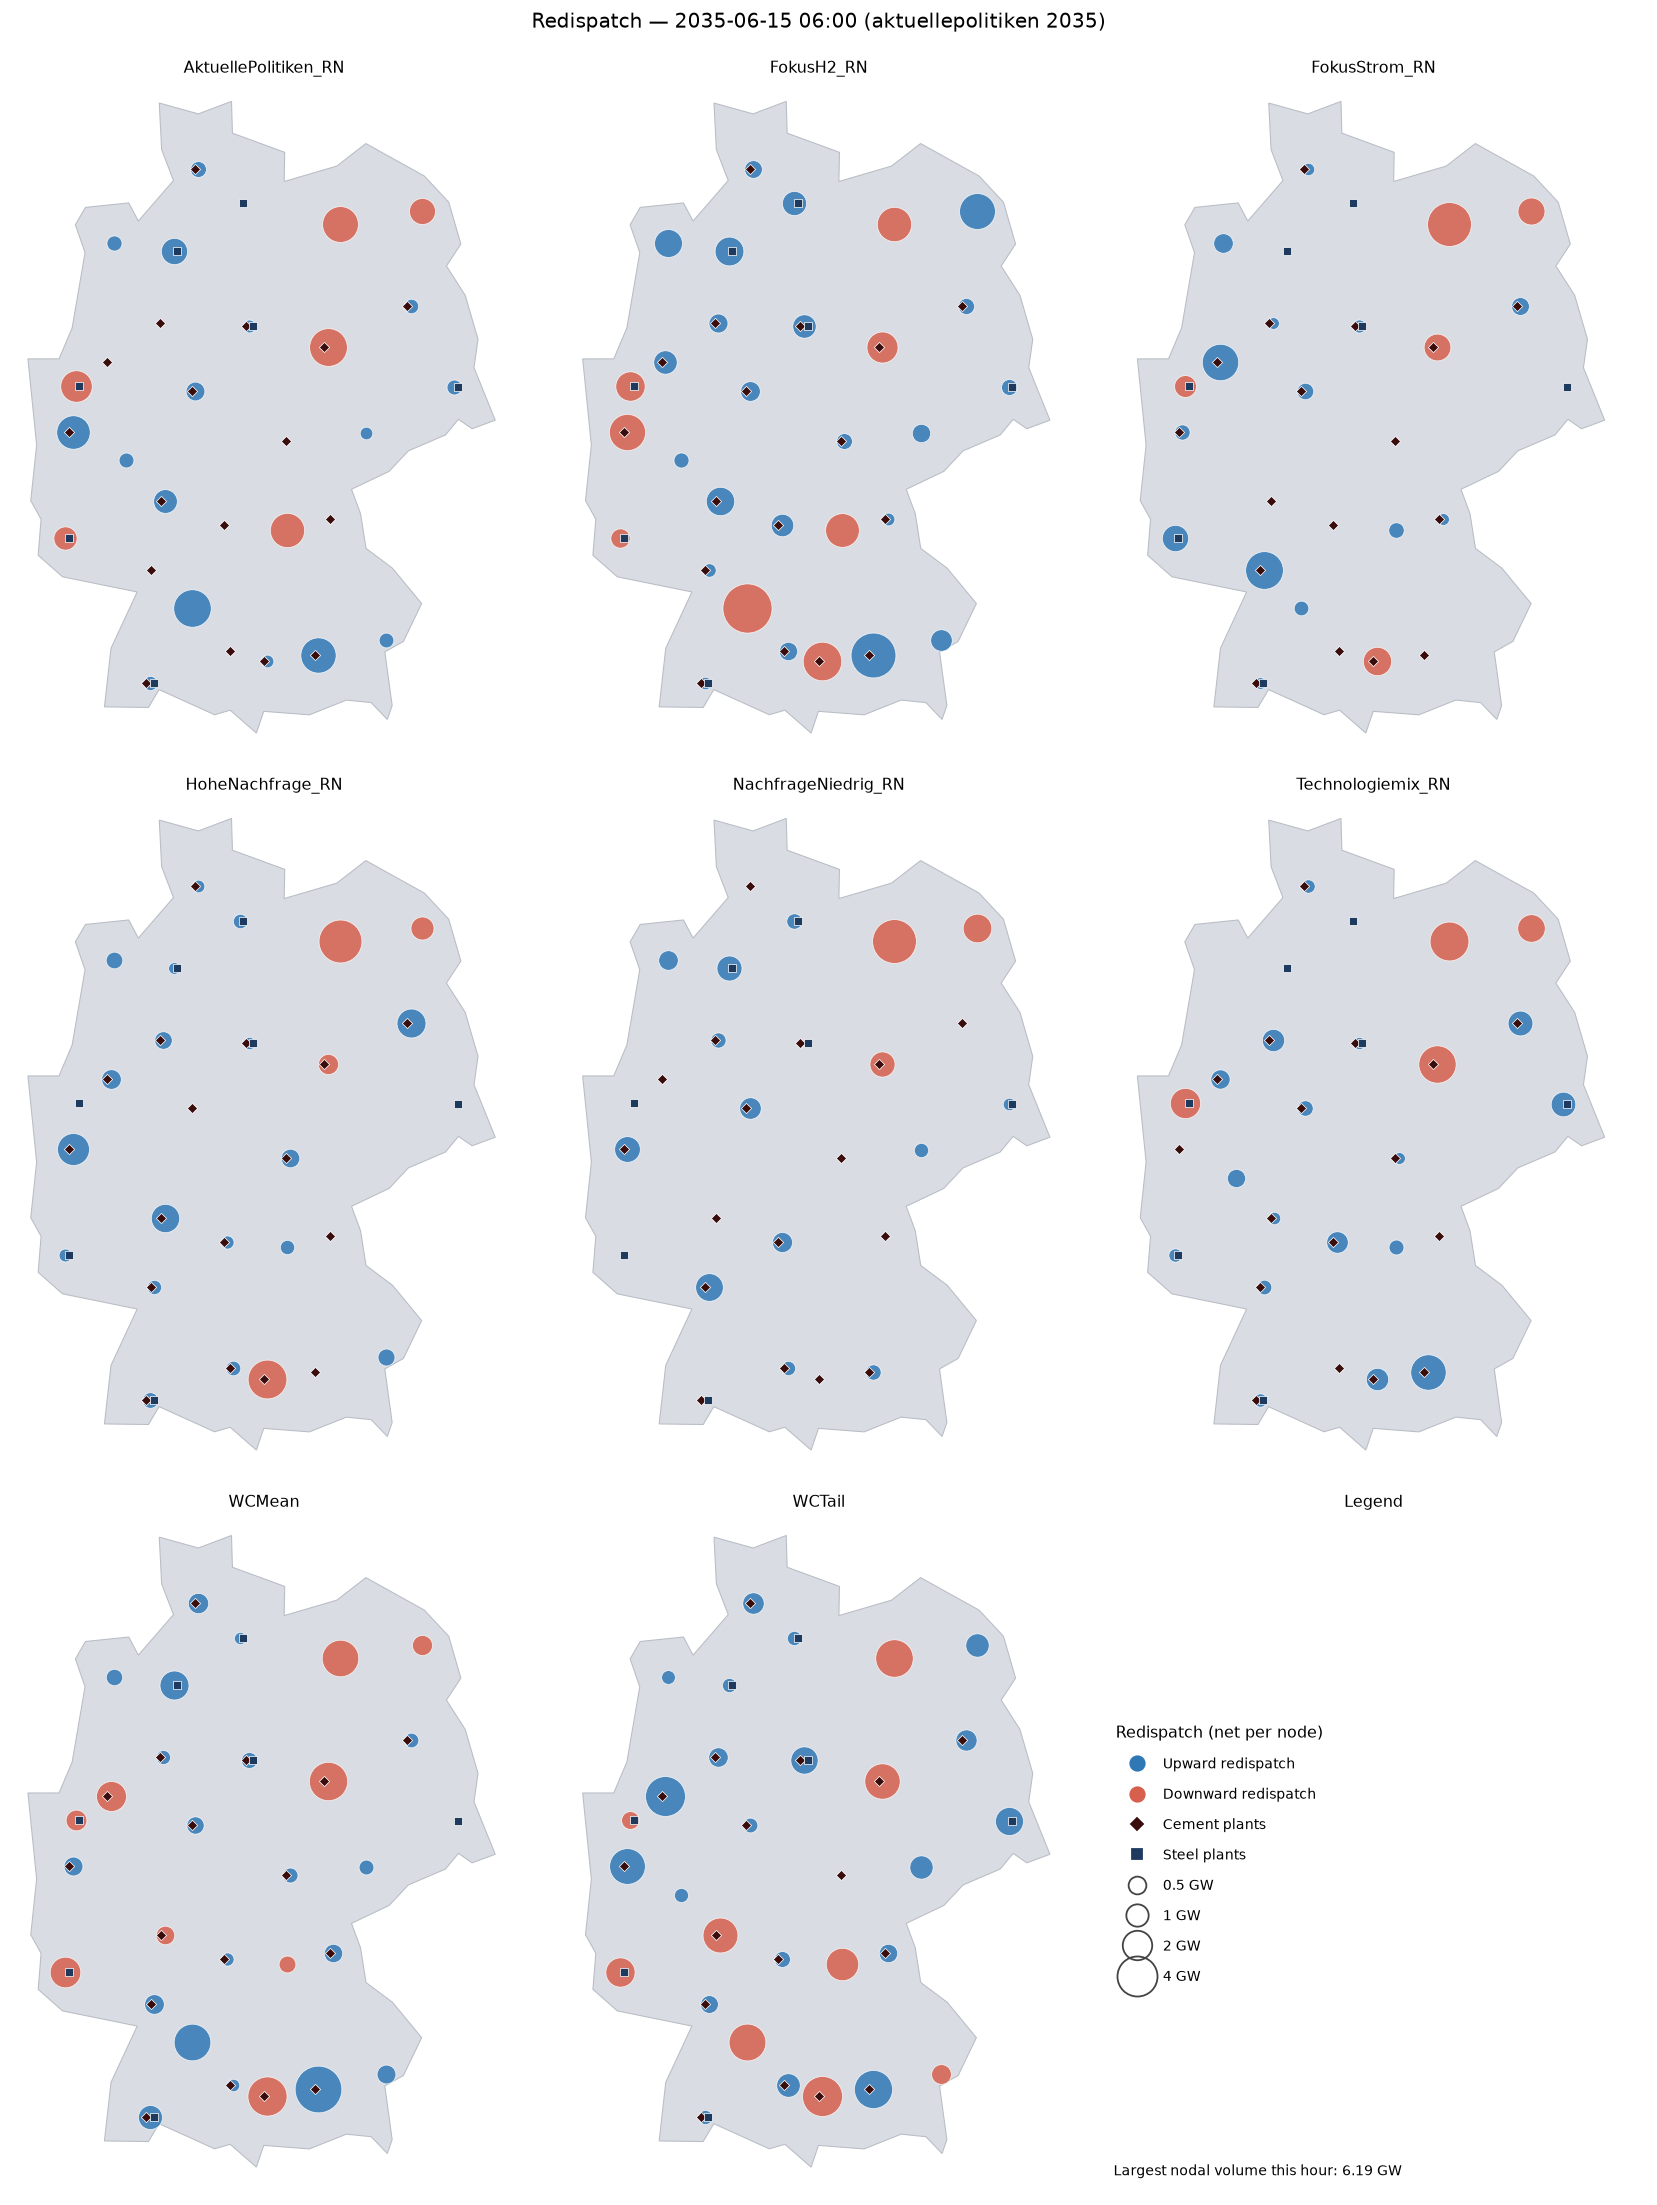

In [39]:
grid_figure(draw_redispatch, rd_handles, "Redispatch (net per node)",
            f"Redispatch — {ts_label}", note=f"Largest nodal volume this hour: {vmax_net / 1000:.2f} GW")

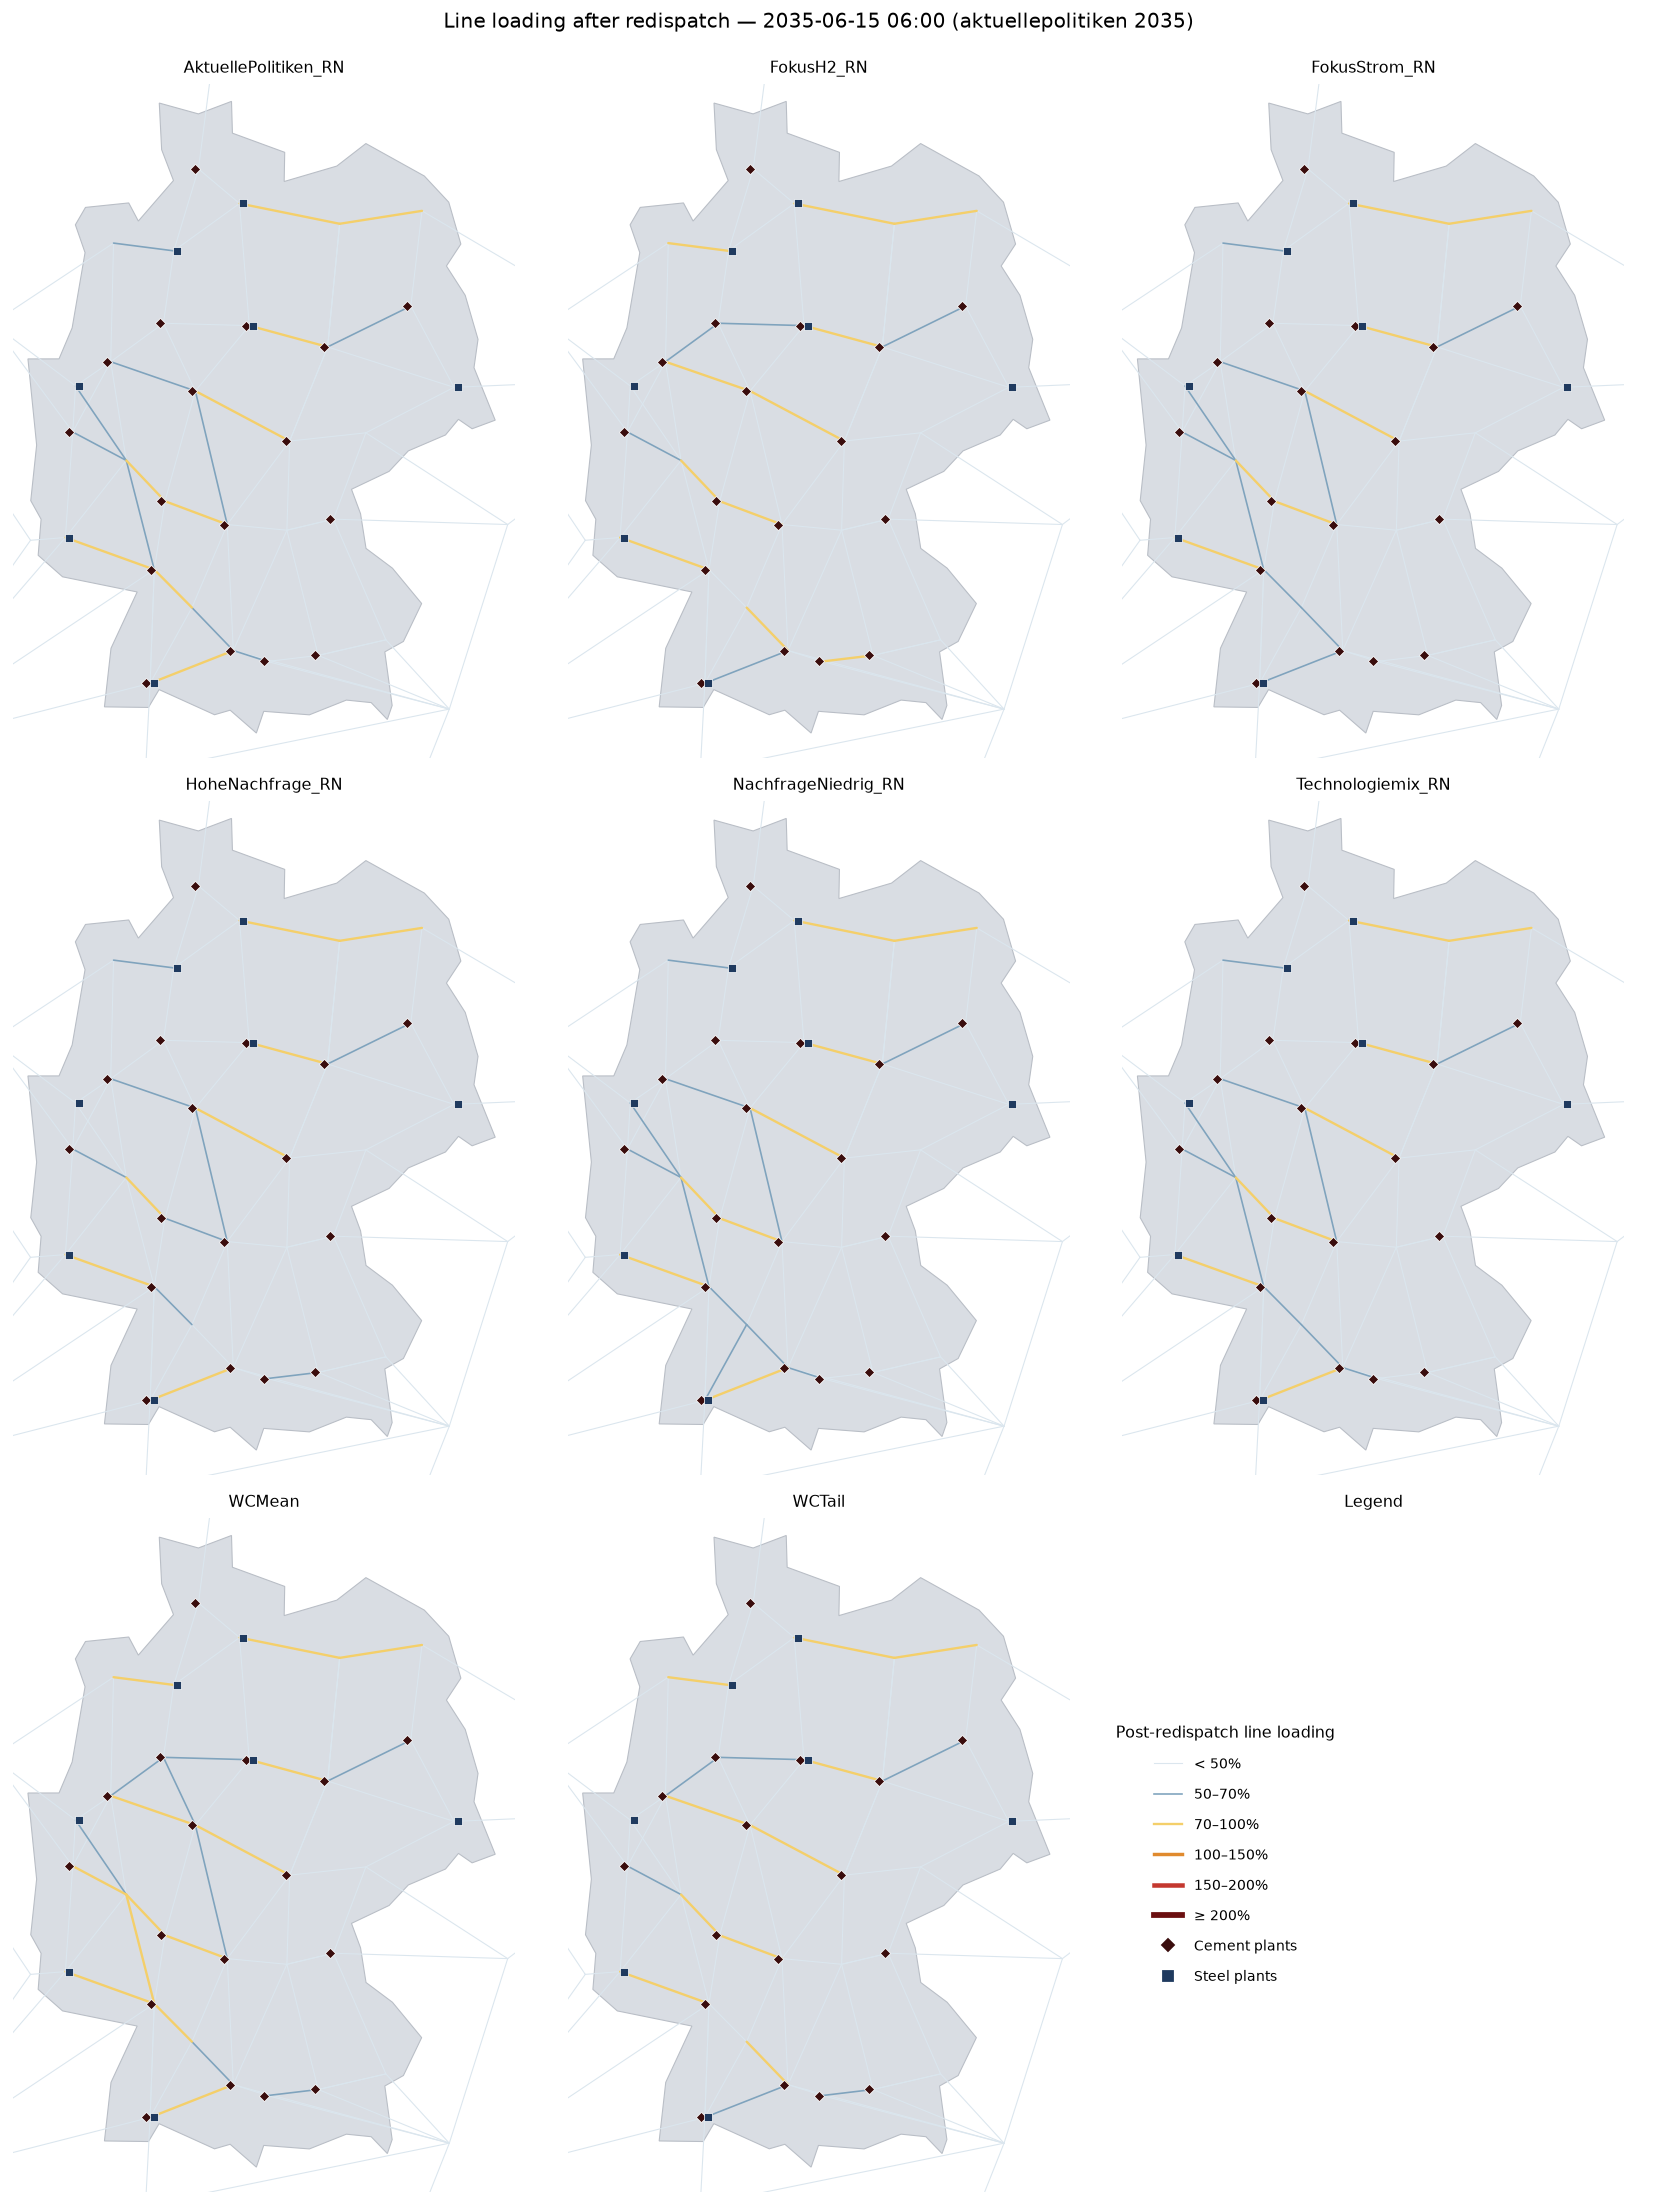

In [40]:
grid_figure(lambda ax, s: draw_loading(ax, s, "post"), load_handles, "Post-redispatch line loading",
            f"Line loading after redispatch — {ts_label}")

In [41]:
summary_g = pd.DataFrame({
    c: {
        "lines >100% before": int((s["pre"] > 1.005).sum()),
        "worst line before (%)": round(s["pre"].max() * 100),
        "lines >100% after": int((s["post"] > 1.005).sum()),
        "worst line after (%)": round(s["post"].max() * 100),
        "upward redispatch (GW)": round(s["net"].clip(lower=0).sum() / 1000, 1),
        "nodes up / down": f"{int((s['net'] > 1).sum())} / {int((s['net'] < -1).sum())}",
    } for c, s in snaps.items()
}).T
display(summary_g)

worst = summary_g["worst line before (%)"].astype(float).idxmax()
biggest = summary_g["upward redispatch (GW)"].astype(float).idxmax()
plant_net = [s["net"][n] for s in snaps.values() for n in set(s["plants"]["cement"]) | set(s["plants"]["steel"])]
n_pl, n_up_pl, n_dn_pl = len(plant_net), sum(v > 1 for v in plant_net), sum(v < -1 for v in plant_net)
wm, wt = CASES[-2], CASES[-1]
twins = (wm in snaps and wt in snaps and np.allclose(snaps[wm]["pre"], snaps[wt]["pre"]))
n_over = int((summary_g["lines >100% before"] > 0).sum())
n_over_after = int((summary_g["lines >100% after"] > 0).sum())
display(Markdown(
    f"**Key finding:** at {TS:%Y-%m-%d %H:%M} {n_over} of {len(snaps)} cases have overloaded lines before redispatch "
    f"(worst: **{worst}**, {summary_g.loc[worst, 'worst line before (%)']:.0f}% loading) and {n_over_after} have any after "
    f"(reconstructed worst line {summary_g['worst line after (%)'].astype(float).max():.0f}%). "
    f"The redispatch volume needed to get there is largest in **{biggest}** "
    f"({summary_g.loc[biggest, 'upward redispatch (GW)']} GW up). "
    + (f"`{wm}` and `{wt}` are identical for this family/year because their inputs "
       "are identical here, so they are not two independent cases at this hour. " if twins else "")
    + f"At nodes that host steel or cement plants (counted per case), redispatch was upward in {n_up_pl} of "
    f"{n_pl} cases-nodes, downward in {n_dn_pl}, and negligible in {n_pl - n_up_pl - n_dn_pl}."
))

,lines >100% before,worst line before (%),lines >100% after,worst line after (%),upward redispatch (GW),nodes up / down
AktuellePolitiken_RN,2,144,0,100,14.4,16 / 6
FokusH2_RN,2,124,0,100,23.5,22 / 8
FokusStrom_RN,4,149,0,100,10.8,14 / 5
HoheNachfrage_RN,2,137,0,100,10.2,18 / 4
NachfrageNiedrig_RN,3,152,0,100,8.1,12 / 3
Technologiemix_RN,2,133,0,100,11.0,17 / 4
WCMean,2,138,0,100,17.5,19 / 9
WCTail,3,134,0,100,22.4,20 / 9


**Key finding:** at 2035-06-15 06:00 8 of 8 cases have overloaded lines before redispatch (worst: **NachfrageNiedrig_RN**, 152% loading) and 0 have any after (reconstructed worst line 100%). The redispatch volume needed to get there is largest in **FokusH2_RN** (23.5 GW up). At nodes that host steel or cement plants (counted per case), redispatch was upward in 110 of 176 cases-nodes, downward in 27, and negligible in 39.

## A12. Run-to-run reproducibility: do identical inputs give identical results?

The two risk-averse cases get byte-identical input files for several family-years, so their simulations should give
identical results there. Wherever that holds, any difference between the two runs is **run-to-run noise** (solver ties,
or code or inputs that changed between the times the runs were made), not an effect of the case. The table shows how large
that noise is for the day-ahead price; it sets the size of case differences that can be trusted in this part.

In [42]:
import hashlib

def _md5(p):
    return hashlib.md5(open(p, "rb").read()).hexdigest()

INPUT_FILES = ["demand_df.csv", "demand_units.csv", "forecasts_df.csv", "powerplant_units.csv",
               "storage_units.csv", "availability_df.csv"]
c1, c2 = CASES[-2], CASES[-1]
arch_r = archives.set_index(["case", "family", "year"])
rows_r = []
for fam in aiu.FAMILIES:
    for yr in aiu.YEARS:
        d1, d2 = aiu.INPUTS_DIR / c1 / f"{fam}_{yr}", aiu.INPUTS_DIR / c2 / f"{fam}_{yr}"
        if not all(_md5(d1 / f) == _md5(d2 / f) for f in INPUT_FILES):
            continue
        pr = []
        for c in (c1, c2):
            a = aiu.load_actor_price(c, fam, yr, arch_r.loc[(c, fam, yr), "path"])
            pr.append(a[a.market_id == "EOM"].set_index("time")["price"])
        diff = (pr[0] - pr[1]).abs()
        rows_r.append({"family": fam, "year": yr, "mean EOM price run 1": pr[0].mean(),
                       "mean EOM price run 2": pr[1].mean(), "difference of means": pr[0].mean() - pr[1].mean(),
                       "hours differing (>0.01)": int((diff > 0.01).sum()), "largest hourly difference": diff.max()})
repro = pd.DataFrame(rows_r)
repro.round(2)

,family,year,mean EOM price run 1,mean EOM price run 2,difference of means,hours differing (>0.01),largest hourly difference
0,aktuellepolitiken,2030,10.67,10.74,-0.07,671,32.85
1,aktuellepolitiken,2035,7.01,6.20,0.80,784,32.57
2,aktuellepolitiken,2040,17.64,17.25,0.40,899,42.26
3,aktuellepolitiken,2045,31.00,30.99,0.01,198,53.21
4,fokusH2,2045,45.77,44.47,1.30,1869,663.23
5,fokusstrom,2045,56.33,60.08,-3.74,1865,243.38
6,hohenachfrage,2045,74.11,64.64,9.47,1571,839.81
7,niedrigenachfrage,2045,44.36,42.76,1.60,2698,225.91
8,technologiemix,2045,54.90,53.05,1.85,2421,253.78


In [43]:
if repro.empty:
    display(Markdown("No family-year has byte-identical inputs for the two risk-averse cases, so reproducibility cannot be measured this way."))
else:
    n_pairs = len(repro)
    n_diff = int((repro["hours differing (>0.01)"] > 0).sum())
    display(Markdown(
        f"**Key finding:** {n_pairs} family-years have byte-identical inputs for `{c1}` and `{c2}`; in {n_diff} of them the "
        f"two runs nonetheless give different day-ahead prices (up to {repro['hours differing (>0.01)'].max():,} hours differ, the "
        f"largest hourly difference is {repro['largest hourly difference'].max():.0f} EUR/MWh, and the yearly mean price differs by up to "
        f"{repro['difference of means'].abs().max():.1f} EUR/MWh, median {repro['difference of means'].abs().median():.1f}). "
        f"Differences between cases that are smaller than this cannot be attributed to the case."
    ))

**Key finding:** 9 family-years have byte-identical inputs for `WCMean` and `WCTail`; in 9 of them the two runs nonetheless give different day-ahead prices (up to 2,698 hours differ, the largest hourly difference is 840 EUR/MWh, and the yearly mean price differs by up to 9.5 EUR/MWh, median 1.3). Differences between cases that are smaller than this cannot be attributed to the case.

# Part B — Price-setter (`_BID`) cases

The steel and cement plants bid FLEXIMOD's own volume and price (`demand_energy_bid_price`), so they are curtailed whenever the clearing price exceeds that price; aviation + maritime are unchanged price-takers. Scenarios: the same eight cases with the `_BID` suffix, 6 families x 4 years each.

In [44]:
TREATMENT = "price-setter (_BID)"
CASES = aiu.BID_CASES
RN_LIKE = [c for c in CASES if not c.startswith("WC")]
CASE_COLOR = dict(zip(CASES, ["#0072B2", "#E69F00", "#009E73", "#D55E00", "#CC79A7", "#56B4E9", "#000000", "#999999"]))

## B1. What's actually in `examples/outputs/` right now

Before analysing anything, check that every scenario of this part is present.

In [45]:
archives = aiu.discover_archives()
archives = archives[archives["case"].isin(CASES)].reset_index(drop=True)  # this part only

coverage = (
    archives.assign(n=1)
    .pivot_table(index="case", columns="family", values="n", aggfunc="sum", fill_value=0)
    .reindex(columns=aiu.FAMILIES, fill_value=0)
    .reindex(index=CASES, fill_value=0)
)
coverage["total"] = coverage.sum(axis=1)
coverage.loc["TOTAL"] = coverage.sum(axis=0)

print(f"{len(archives)}/192 scenarios of this part found "
      f"({len(archives) / 192:.0%}).")
print(f"Cases with at least one finished scenario: {sorted(archives['case'].unique())}")
coverage

192/192 scenarios of this part found (100%).
Cases with at least one finished scenario: ['AktuellePolitiken_RN_BID', 'FokusH2_RN_BID', 'FokusStrom_RN_BID', 'HoheNachfrage_RN_BID', 'NachfrageNiedrig_RN_BID', 'Technologiemix_RN_BID', 'WCMean_BID', 'WCTail_BID']


family,aktuellepolitiken,fokusH2,fokusstrom,hohenachfrage,niedrigenachfrage,technologiemix,total
case,,,,,,,
AktuellePolitiken_RN_BID,4,4,4,4,4,4,24
FokusH2_RN_BID,4,4,4,4,4,4,24
FokusStrom_RN_BID,4,4,4,4,4,4,24
HoheNachfrage_RN_BID,4,4,4,4,4,4,24
NachfrageNiedrig_RN_BID,4,4,4,4,4,4,24
Technologiemix_RN_BID,4,4,4,4,4,4,24
WCMean_BID,4,4,4,4,4,4,24
WCTail_BID,4,4,4,4,4,4,24
TOTAL,32,32,32,32,32,32,192


## B2. Overall day-ahead (EOM) and aFRR energy negative price impact

For every finished with-actor scenario, each hourly EOM / aFRR energy negative
clearing price is matched to the same hour in the matching no-actor baseline
(same family + year), and `delta = price_with_actors - price_baseline` is
computed directly (no aggregation across timestamps beforehand).

In [46]:
price_panel = aiu.build_price_panel(archives)
print(f"{len(price_panel):,} matched hourly price rows across "
      f"{price_panel[['case','family','year']].drop_duplicates().shape[0]} scenarios.")
price_panel.head()

3,371,424 matched hourly price rows across 192 scenarios.


,market_id,price_actor,time,price_baseline,case,family,year,is_bid,delta
0,EOM,10.016,2030-01-01 00:00:00,10.016,AktuellePolitiken_RN_BID,aktuellepolitiken,2030,True,0.000
1,EOM,10.016,2030-01-01 01:00:00,0.000,AktuellePolitiken_RN_BID,aktuellepolitiken,2030,True,10.016
2,EOM,10.016,2030-01-01 02:00:00,10.016,AktuellePolitiken_RN_BID,aktuellepolitiken,2030,True,0.000
3,EOM,0.000,2030-01-01 03:00:00,0.000,AktuellePolitiken_RN_BID,aktuellepolitiken,2030,True,0.000
4,EOM,0.000,2030-01-01 04:00:00,0.000,AktuellePolitiken_RN_BID,aktuellepolitiken,2030,True,0.000


In [47]:
summary = (
    price_panel.groupby("market_id")["delta"]
    .agg(mean="mean", median="median", std="std", p05=lambda s: s.quantile(0.05),
         p95=lambda s: s.quantile(0.95), max="max", min="min")
    .round(2)
)
summary.rename(index=MARKET_LABEL)

,mean,median,std,p05,p95,max,min
market_id,,,,,,,
aFRR energy negative,0.94,0.0,13.38,0.00,0.02,560.93,-0.02
EOM,35.74,0.0,258.78,-18.18,175.59,3000.00,-3000.00


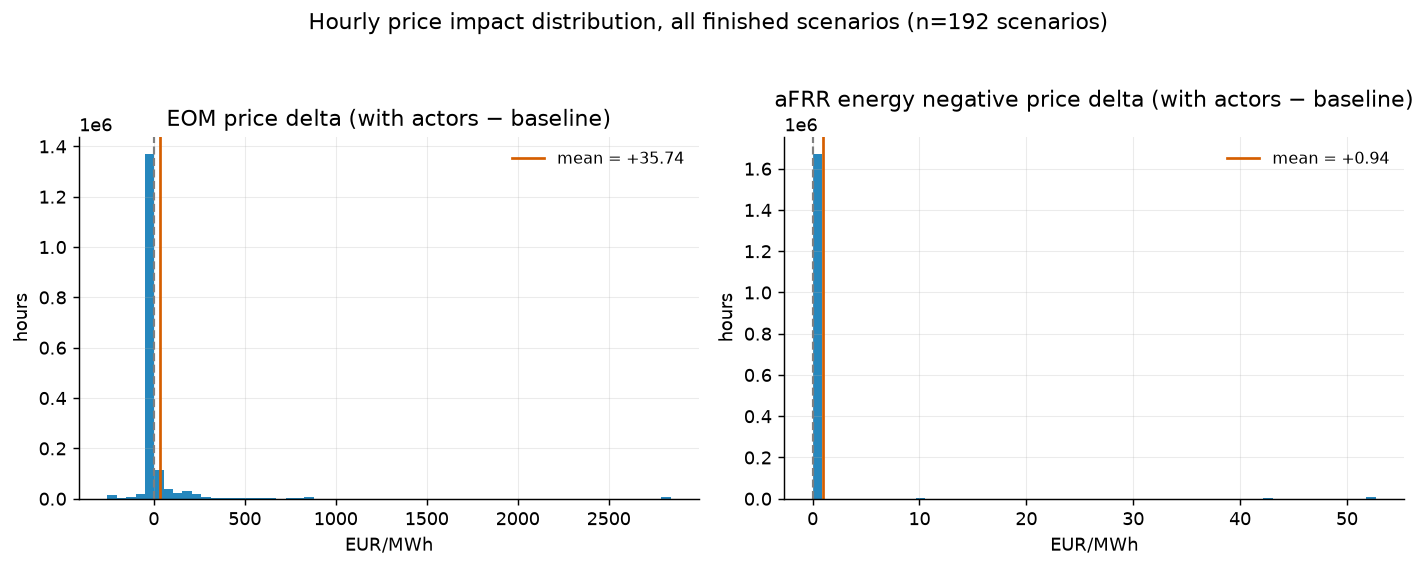

In [48]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4.2), sharey=False)
for ax, market in zip(axes, ["EOM", "CRM_energy_neg"]):
    d = price_panel.loc[price_panel["market_id"] == market, "delta"]
    ax.hist(d.clip(d.quantile(0.005), d.quantile(0.995)), bins=60,
            color=COLOR["actor"], alpha=0.85)
    ax.axvline(0, color=COLOR["baseline"], linewidth=1.2, linestyle="--")
    ax.axvline(d.mean(), color=COLOR["combined"], linewidth=1.5,
                label=f"mean = {d.mean():+.2f}")
    ax.set_title(f"{MARKET_LABEL.get(market, market)} price delta (with actors − baseline)")
    ax.set_xlabel("EUR/MWh" if market == "EOM" else "EUR/MWh")
    ax.set_ylabel("hours")
    ax.legend(frameon=False, fontsize=9)
fig.suptitle("Hourly price impact distribution, all finished scenarios "
             f"(n={price_panel[['case','family','year']].drop_duplicates().shape[0]} scenarios)",
             y=1.03)
fig.tight_layout()
plt.show()

In [49]:
by_year = (
    price_panel.groupby(["market_id", "year"])["delta"]
    .agg(mean="mean", median="median", p95=lambda s: s.quantile(0.95))
    .round(2)
    .unstack("market_id")
)
by_year.rename(columns=MARKET_LABEL, level=1)

mean                       median       \
market_id aFRR energy negative     EOM aFRR energy negative  EOM   
year                                                               
2030                      0.74    0.11                  0.0  0.0   
2035                      0.99    9.08                  0.0  0.0   
2040                      0.68  119.82                  0.0  0.0   
2045                      1.37   12.25                  0.0  0.0   

                           p95          
market_id aFRR energy negative     EOM  
year                                    
2030                      0.02   20.98  
2035                      0.02  184.24  
2040                      0.02  808.28  
2045                      0.02  147.66

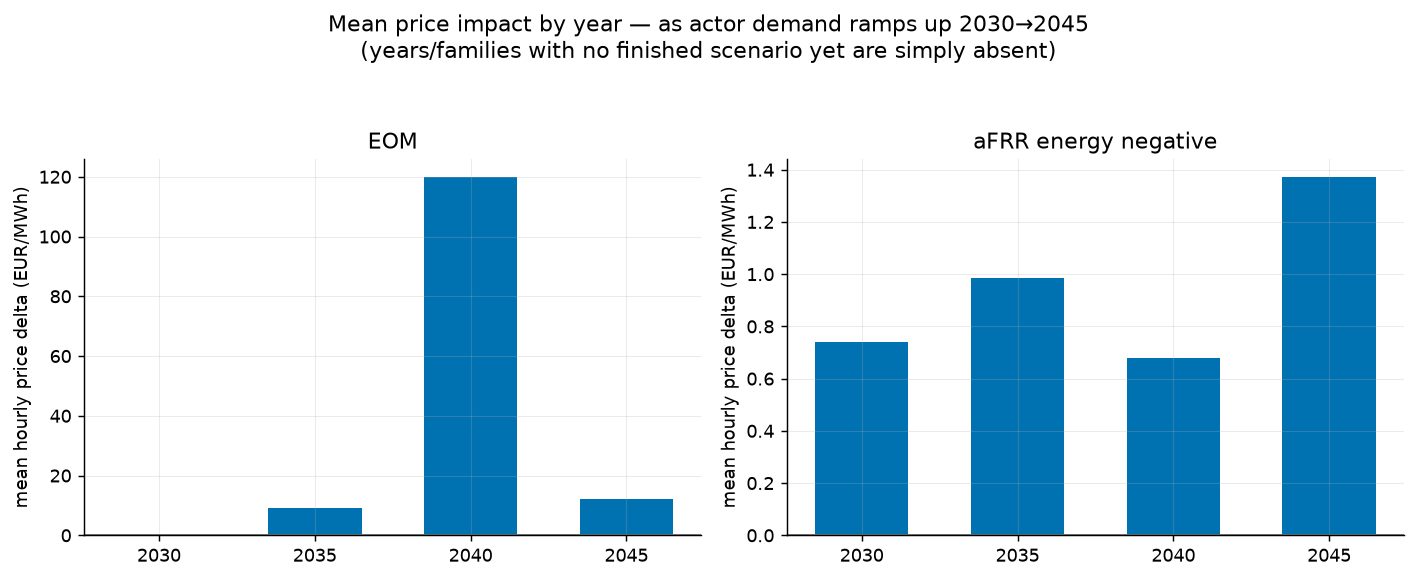

Scenario coverage behind this chart, by year:
year
2030    48
2035    48
2040    48
2045    48
dtype: int64


In [50]:
# EOM and aFRR energy negative deltas are ~1000x apart in magnitude (EUR/MWh vs.
# fractions of a cent) -- one shared axis would make aFRR energy negative invisible,
# so this is two independently-scaled panels rather than one dual-axis chart.
piv = price_panel.groupby(["year", "market_id"])["delta"].mean().unstack("market_id")
fig, axes = plt.subplots(1, 2, figsize=(11, 4.2))
for ax, market in zip(axes, ["EOM", "CRM_energy_neg"]):
    vals = piv.get(market, pd.Series(index=piv.index, dtype=float))
    ax.bar(piv.index.astype(str), vals, color=COLOR["actor"], width=0.6)
    ax.axhline(0, color=COLOR["baseline"], linewidth=1)
    ax.set_ylabel("mean hourly price delta (EUR/MWh)")
    ax.set_title(MARKET_LABEL.get(market, market))
fig.suptitle("Mean price impact by year — as actor demand ramps up 2030→2045\n"
             "(years/families with no finished scenario yet are simply absent)", y=1.05)
fig.tight_layout()
plt.show()

print("Scenario coverage behind this chart, by year:")
print(archives.groupby("year").size().reindex(aiu.YEARS, fill_value=0))

In [51]:
eom_mean = summary.loc["EOM", "mean"] if "EOM" in summary.index else float("nan")
eom_median = summary.loc["EOM", "median"] if "EOM" in summary.index else float("nan")
eom_max = summary.loc["EOM", "max"] if "EOM" in summary.index else float("nan")
eom_min = summary.loc["EOM", "min"] if "EOM" in summary.index else float("nan")
afrr_mean = summary.loc["CRM_energy_neg", "mean"] if "CRM_energy_neg" in summary.index else float("nan")

eom_year_means = by_year[("mean", "EOM")].dropna() if ("mean", "EOM") in by_year.columns else pd.Series(dtype=float)
trend_note = (
    "an upward drift across the years collected so far"
    if len(eom_year_means) >= 2 and eom_year_means.iloc[-1] > eom_year_means.iloc[0]
    else "no clean multi-year trend yet"
)

cap_note = (" — the extremes sit at the 3,000 EUR/MWh price cap/floor"
            if max(abs(eom_min), abs(eom_max)) >= 2900 else "")
skew_note = ("most hours are unaffected, and the mean is pulled by a small number of extreme hours"
             if abs(eom_median) < 0.1 * abs(eom_mean) else "the typical hour is shifted as well")
ratio = abs(eom_mean / afrr_mean) if afrr_mean else float("nan")
ratio_note = (f"about {ratio:.0f}x below the EOM shift" if ratio >= 1 else f"about {1 / ratio:.1f}x above the EOM shift")
display(Markdown(
    f"**Key finding:** across every scenario of this part, the new actors shift the mean EOM price "
    f"by **{eom_mean:+.1f} EUR/MWh**; the *median* shift is **{eom_median:.1f}** — {skew_note} "
    f"(delta ranges from **{eom_min:+.0f}** to **{eom_max:+.0f} EUR/MWh**{cap_note}). The aFRR energy negative "
    f"shift is {'much smaller' if ratio > 5 else 'of similar size'} in absolute terms "
    f"(mean **{afrr_mean:+.3f} EUR/MWh**, {ratio_note}). "
    f"By year, there's {trend_note} (first vs. last year only, not a fitted trend)."
))

**Key finding:** across every scenario of this part, the new actors shift the mean EOM price by **+35.7 EUR/MWh**; the *median* shift is **0.0** — most hours are unaffected, and the mean is pulled by a small number of extreme hours (delta ranges from **-3000** to **+3000 EUR/MWh** — the extremes sit at the 3,000 EUR/MWh price cap/floor). The aFRR energy negative shift is much smaller in absolute terms (mean **+0.940 EUR/MWh**, about 38x below the EOM shift). By year, there's an upward drift across the years collected so far (first vs. last year only, not a fitted trend).

## B3. Per-actor-category contribution

`market_orders.csv` is streamed and filtered (chunked, `usecols`-limited — the
raw file is several GB per scenario) down to just the three actor categories'
own bids, aggregated to one row per (scenario, hour, market, category). This
gives cleared volume per category, which is compared against the *system-wide*
price delta from Section B2 as a proxy for each category's share of the impact
— see the Methodology caveat: this is an attribution over a joint run, not an
ablation.

In [52]:
orders_panel = aiu.build_orders_panel(archives)
print(f"{len(orders_panel):,} (scenario, hour, market, category) rows.")
orders_panel.head().assign(market_id=lambda d: d["market_id"].replace(MARKET_LABEL))

6,371,983 (scenario, hour, market, category) rows.


,start_time,market_id,category,volume,accepted_volume,case,family,year,is_bid
0,2030-01-01,aFRR energy negative,cement,-10455.00000,-1.045500e+04,AktuellePolitiken_RN_BID,aktuellepolitiken,2030,True
1,2030-01-01,aFRR energy negative,steel,-544.00000,-5.440000e+02,AktuellePolitiken_RN_BID,aktuellepolitiken,2030,True
2,2030-01-01,EOM,aviation_maritime,-71.71235,-7.171235e+01,AktuellePolitiken_RN_BID,aktuellepolitiken,2030,True
3,2030-01-01,EOM,cement,-10468.17270,-1.046817e+04,AktuellePolitiken_RN_BID,aktuellepolitiken,2030,True
4,2030-01-01,EOM,steel,-3.34928,-6.124900e-12,AktuellePolitiken_RN_BID,aktuellepolitiken,2030,True


In [53]:
vol_summary = (
    orders_panel.groupby(["market_id", "category"])[["volume", "accepted_volume"]]
    .sum()
    .abs()  # demand volumes are signed negative in market_orders.csv
    .rename(columns={"volume": "bid_MWh", "accepted_volume": "cleared_MWh"})
)
vol_summary["cleared_share"] = (vol_summary["cleared_MWh"] / vol_summary["bid_MWh"]).round(4)
vol_summary.round(1).rename(index=MARKET_LABEL, level=0)

bid_MWh   cleared_MWh  \
market_id            category                                        
aFRR energy negative cement             5.755738e+09  5.741905e+09   
                     steel              2.799364e+09  2.788762e+09   
EOM                  aviation_maritime  1.765715e+09  1.764030e+09   
                     cement             1.370367e+10  9.299892e+09   
                     steel              7.907110e+09  5.474774e+09   

                                        cleared_share  
market_id            category                          
aFRR energy negative cement                       1.0  
                     steel                        1.0  
EOM                  aviation_maritime            1.0  
                     cement                       0.7  
                     steel                        0.7

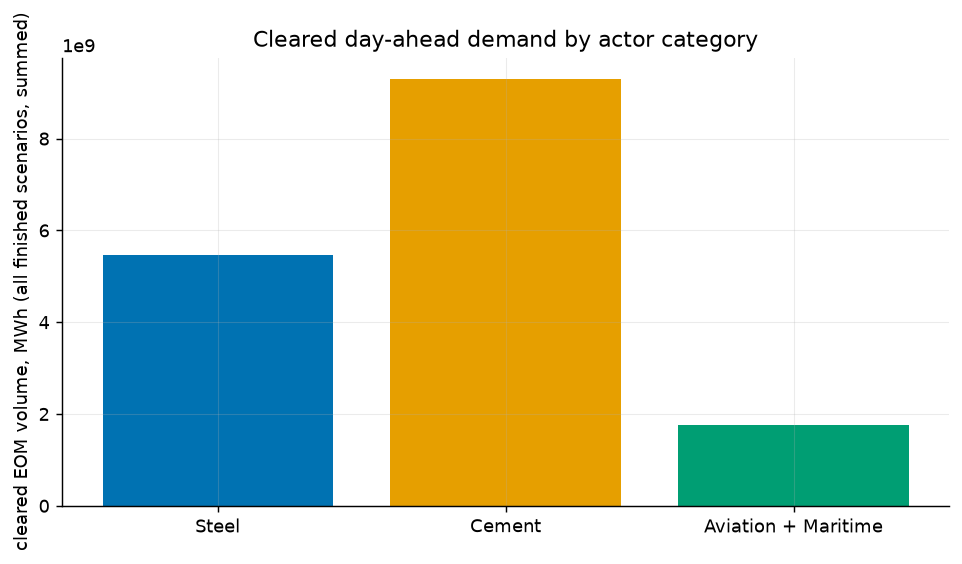

In [54]:
fig, ax = plt.subplots(figsize=(7.5, 4.2))
share = (
    orders_panel[orders_panel["market_id"] == "EOM"]
    .groupby("category")["accepted_volume"].sum().abs()
)
share = share.reindex(CATEGORIES)
ax.bar([CATEGORY_LABEL[c] for c in share.index], share.values,
       color=[COLOR[c] for c in share.index])
ax.set_ylabel("cleared EOM volume, MWh (all finished scenarios, summed)")
ax.set_title("Cleared day-ahead demand by actor category")
fig.tight_layout()
plt.show()

In [55]:
# Hour-by-hour: does the system price delta track total actor demand?
hourly_price = (
    price_panel[price_panel["market_id"] == "EOM"]
    .groupby(["case", "family", "year", "time"])["delta"].mean()
)
hourly_actor_vol = (
    orders_panel[orders_panel["market_id"] == "EOM"]
    .groupby(["case", "family", "year", "start_time", "category"])["accepted_volume"]
    .sum().abs().unstack("category").reindex(columns=CATEGORIES, fill_value=0)
)
hourly_actor_vol.index = hourly_actor_vol.index.set_names("time", level="start_time")

joined = hourly_price.to_frame("price_delta").join(hourly_actor_vol, how="inner")
joined["total_actor_volume"] = joined[CATEGORIES].sum(axis=1)

corr = joined[["price_delta", "total_actor_volume", *CATEGORIES]].corr()["price_delta"].drop("price_delta")
print("Hour-level correlation of EOM price delta with cleared actor volume "
      "(system-wide and per category):")
corr.round(3)

Hour-level correlation of EOM price delta with cleared actor volume (system-wide and per category):


total_actor_volume   -0.010
steel                -0.034
cement                0.003
aviation_maritime     0.048
Name: price_delta, dtype: float64

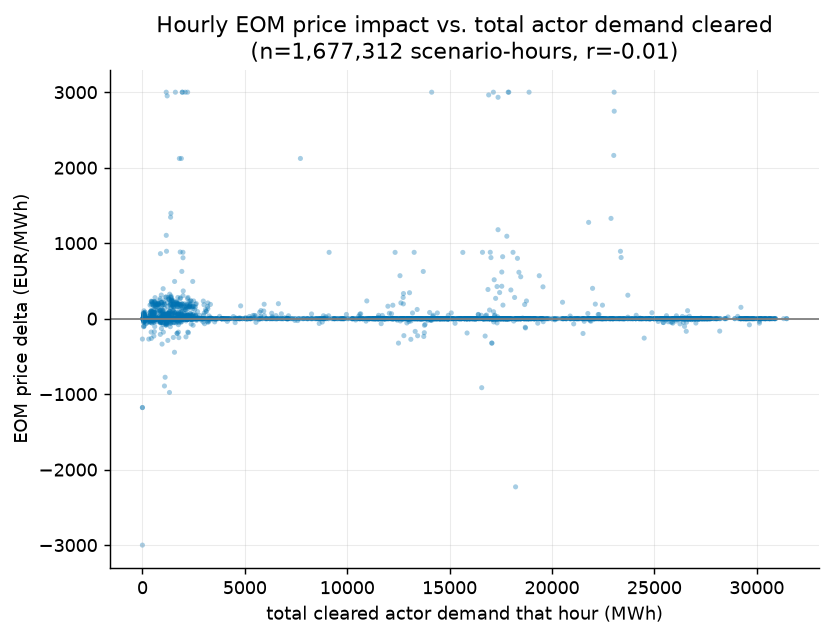

In [56]:
fig, ax = plt.subplots(figsize=(6.5, 5))
sample = joined.sample(min(4000, len(joined)), random_state=0) if len(joined) else joined
ax.scatter(sample["total_actor_volume"], sample["price_delta"],
           s=8, alpha=0.35, color=COLOR["actor"], edgecolors="none")
ax.axhline(0, color=COLOR["baseline"], linewidth=1)
ax.set_xlabel("total cleared actor demand that hour (MWh)")
ax.set_ylabel("EOM price delta (EUR/MWh)")
ax.set_title("Hourly EOM price impact vs. total actor demand cleared\n"
             f"(n={len(joined):,} scenario-hours, r={corr.get('total_actor_volume', float('nan')):.2f})")
fig.tight_layout()
plt.show()

In [57]:
eom_vol = vol_summary.loc["EOM"]
dominant = eom_vol["cleared_MWh"].idxmax()
dominant_twh = eom_vol.loc[dominant, "cleared_MWh"] / 1e6
other_twh = {c: eom_vol.loc[c, "cleared_MWh"] / 1e6 for c in CATEGORIES if c != dominant and c in eom_vol.index}
others_str = ", ".join(f"{v:.2f} TWh {CATEGORY_LABEL[c].lower()}" for c, v in other_twh.items())

n_scenarios = orders_panel[["case", "family", "year"]].drop_duplicates().shape[0]
display(Markdown(
    f"**Key finding:** {CATEGORY_LABEL[dominant]} clears by far the most day-ahead volume, "
    f"summed across all {n_scenarios} finished scenarios "
    f"({dominant_twh:.1f} TWh vs. {others_str} — each figure a multi-scenario total, not a single "
    f"year's consumption), making it the largest single contributor to the aggregate demand added "
    f"system-wide. But hour-level correlation between any category's "
    f"cleared volume and the EOM price delta stays weak "
    f"(r = {corr.get('total_actor_volume', float('nan')):.2f} combined, "
    f"r = {corr.get(dominant, float('nan')):.2f} for {CATEGORY_LABEL[dominant].lower()} alone) — "
    f"consistent with the price swings above coming from a handful of scarcity hours, not from "
    f"the general volume level."
))

**Key finding:** Cement clears by far the most day-ahead volume, summed across all 192 finished scenarios (9299.9 TWh vs. 5474.77 TWh steel, 1764.03 TWh aviation + maritime — each figure a multi-scenario total, not a single year's consumption), making it the largest single contributor to the aggregate demand added system-wide. But hour-level correlation between any category's cleared volume and the EOM price delta stays weak (r = -0.01 combined, r = 0.00 for cement alone) — consistent with the price swings above coming from a handful of scarcity hours, not from the general volume level.

## B4. Served share of the actors' demand (price-setter `_BID` cases)

In the `_BID` cases the steel and cement plants bid their own assumed day-ahead / aFRR price, so they are curtailed whenever the simulated clearing price exceeds it. Aviation + maritime stay price-takers in these cases. The share below (accepted / submitted volume) is the curtailment effect itself: a curtailed plant mechanically has less price impact than its full demand would have, which matters when reading the price results in this part.

category,Steel,Cement,Aviation + Maritime
market_id,,,
aFRR energy negative,0.996,0.998,NaN
EOM,0.692,0.679,0.999


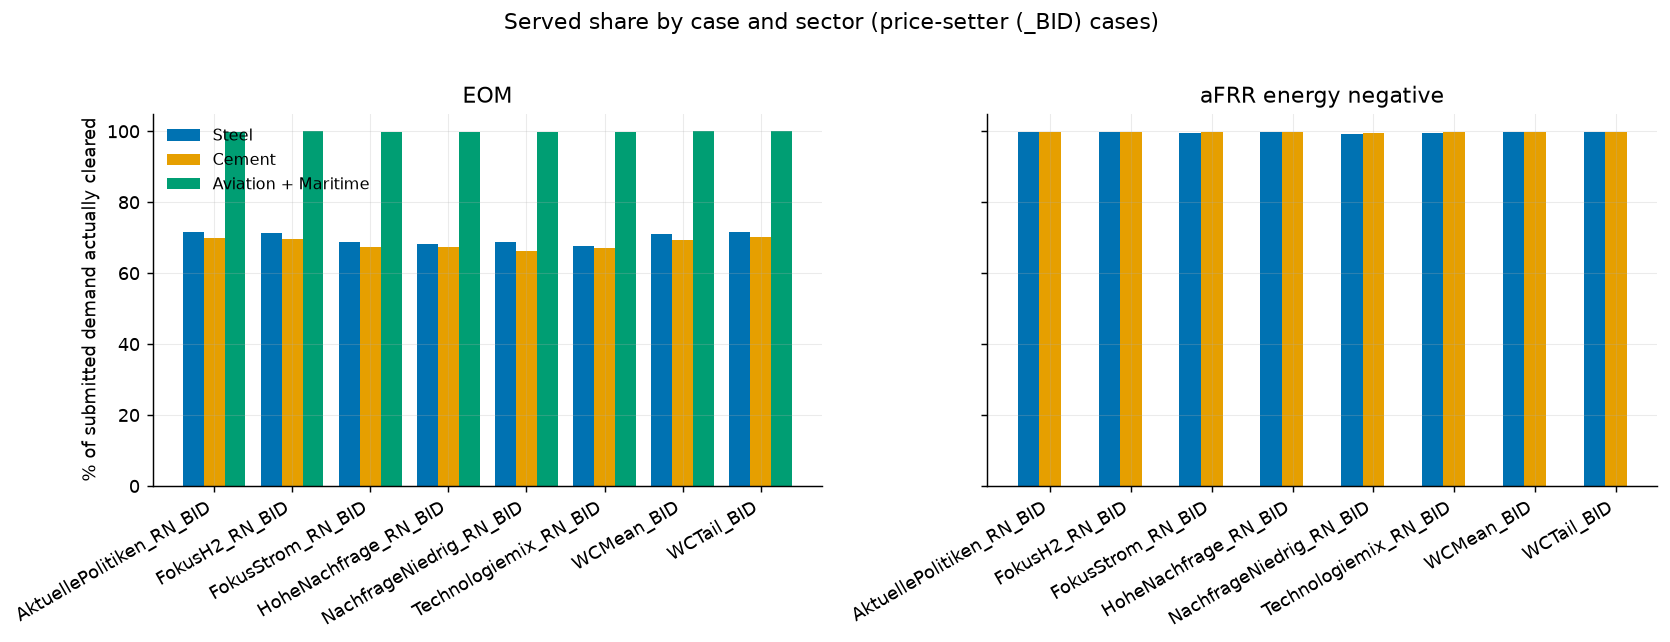

In [58]:
orders_bid = orders_panel[orders_panel["case"].isin(CASES)].copy()
orders_bid[["volume", "accepted_volume"]] = orders_bid[["volume", "accepted_volume"]].abs()

def served(df, by):
    g = df.groupby(by)[["volume", "accepted_volume"]].sum()
    return g["accepted_volume"] / g["volume"]

by_cat = served(orders_bid, ["market_id", "category"]).unstack("category")[CATEGORIES]
display(by_cat.round(3).rename(columns=CATEGORY_LABEL, index=MARKET_LABEL))

fig, axes = plt.subplots(1, 2, figsize=(13, 4.8), sharey=True)
for ax, market in zip(axes, ["EOM", "CRM_energy_neg"]):
    sub = orders_bid[orders_bid["market_id"] == market]
    piv = served(sub, ["case", "category"]).unstack("category").reindex(index=CASES, columns=CATEGORIES)
    x = np.arange(len(CASES))
    w = 0.8 / len(CATEGORIES)
    for i, c in enumerate(CATEGORIES):
        ax.bar(x + (i - 1) * w, piv[c] * 100, width=w, color=COLOR[c], label=CATEGORY_LABEL[c])
    ax.set_xticks(x)
    ax.set_xticklabels(CASES, rotation=30, ha="right")
    ax.set_ylim(0, 105)
    ax.set_title(MARKET_LABEL.get(market, market))
axes[0].set_ylabel("% of submitted demand actually cleared")
axes[0].legend(frameon=False, fontsize=9)
fig.suptitle(f"Served share by case and sector ({TREATMENT} cases)", y=1.02)
fig.tight_layout()
plt.show()

In [59]:
eom = by_cat.loc["EOM"]
lowest = eom.idxmin()
display(Markdown(
    f"**Key finding:** in the `_BID` cases the steel and cement plants are not price-takers: on the day-ahead market "
    f"{CATEGORY_LABEL[eom.idxmax()]} clears {eom.max():.0%} of its submitted volume and "
    f"{CATEGORY_LABEL[lowest]} only {eom.min():.0%}, so up to {1 - eom.min():.0%} of that sector's demand is curtailed by its "
    f"own price assumption."
))

**Key finding:** in the `_BID` cases the steel and cement plants are not price-takers: on the day-ahead market Aviation + Maritime clears 100% of its submitted volume and Cement only 68%, so up to 32% of that sector's demand is curtailed by its own price assumption.

## B5. Quarterly aFRR capacity price by case (aFRR capacity positive / aFRR capacity negative)

A different market from everything above: aFRR capacity positive/aFRR capacity negative
are the daily capacity auctions (6x 4-hour blocks/day, `pay_as_bid`), not the
hourly energy markets Sections B2–B4 analyze. **The new actors don't submit bids
into either capacity market** — `demand_units.csv` leaves
`bidding_CRM_capacity_pos`/`bidding_CRM_capacity_neg` blank for every steel,
cement and AVMAR unit.

That turns out *not* to mean the capacity price is unaffected, though (see the
sanity check below): with-actors capacity prices differ substantially from the
baseline's, even though no actor bid is present in either market. The
likely mechanism is indirect — the new EOM/aFRR-energy demand changes which
powerplants get dispatched and what capacity they have left over to offer into
the capacity auction, which feeds through to the `pay_as_bid` clearing price.
That's a real second-order finding worth noting, not a bug in this notebook —
but it does mean this section is *not* a clean "actors vs. no actors" panel;
it's a descriptive view of the capacity market by case, shown here because it
groups the same way as the rest of the notebook (by case, auto-updating as
more scenarios finish).

Two more unit notes vs. a typical real-world reference: our `market_meta.csv`
`price` column is `EUR/MW` per cleared 4-hour product block (`config.yaml`'s
`price_unit`), not `EUR/MW/week`, and "quarter" here means calendar quarter of
the product's delivery hour, averaged across whatever family/year combinations
have finished for each case (not a single fixed scenario).

In [60]:
capacity_panel = aiu.build_capacity_panel(archives)
print(f"{len(capacity_panel):,} matched (case, hour, market) capacity rows.")

print("\nScenarios behind each case's bars (family x year combos finished):")
print(archives[archives['case'].isin(CASES)].groupby("case").size()
      .reindex(CASES, fill_value=0))

# No actor bid ever appears in these markets -- so any gap here is an indirect
# effect (via dispatch/available capacity), not a direct bidding effect.
gap = (capacity_panel["price_actor"] - capacity_panel["price_baseline"]).abs()
level = capacity_panel[["price_actor", "price_baseline"]].mean().mean()
print(f"\nmean |with-actors − baseline| capacity price gap: {gap.mean():.1f} EUR/MW "
      f"vs. a mean price level of {level:.1f} EUR/MW across both — a "
      f"{gap.mean() / level:.0%} gap despite zero direct actor bids in this market, "
      "i.e. an indirect (dispatch-driven) effect, not noise.")

842,868 matched (case, hour, market) capacity rows.

Scenarios behind each case's bars (family x year combos finished):
case
AktuellePolitiken_RN_BID    24
FokusH2_RN_BID              24
FokusStrom_RN_BID           24
HoheNachfrage_RN_BID        24
NachfrageNiedrig_RN_BID     24
Technologiemix_RN_BID       24
WCMean_BID                  24
WCTail_BID                  24
dtype: int64

mean |with-actors − baseline| capacity price gap: 131.1 EUR/MW vs. a mean price level of 94.9 EUR/MW across both — a 138% gap despite zero direct actor bids in this market, i.e. an indirect (dispatch-driven) effect, not noise.


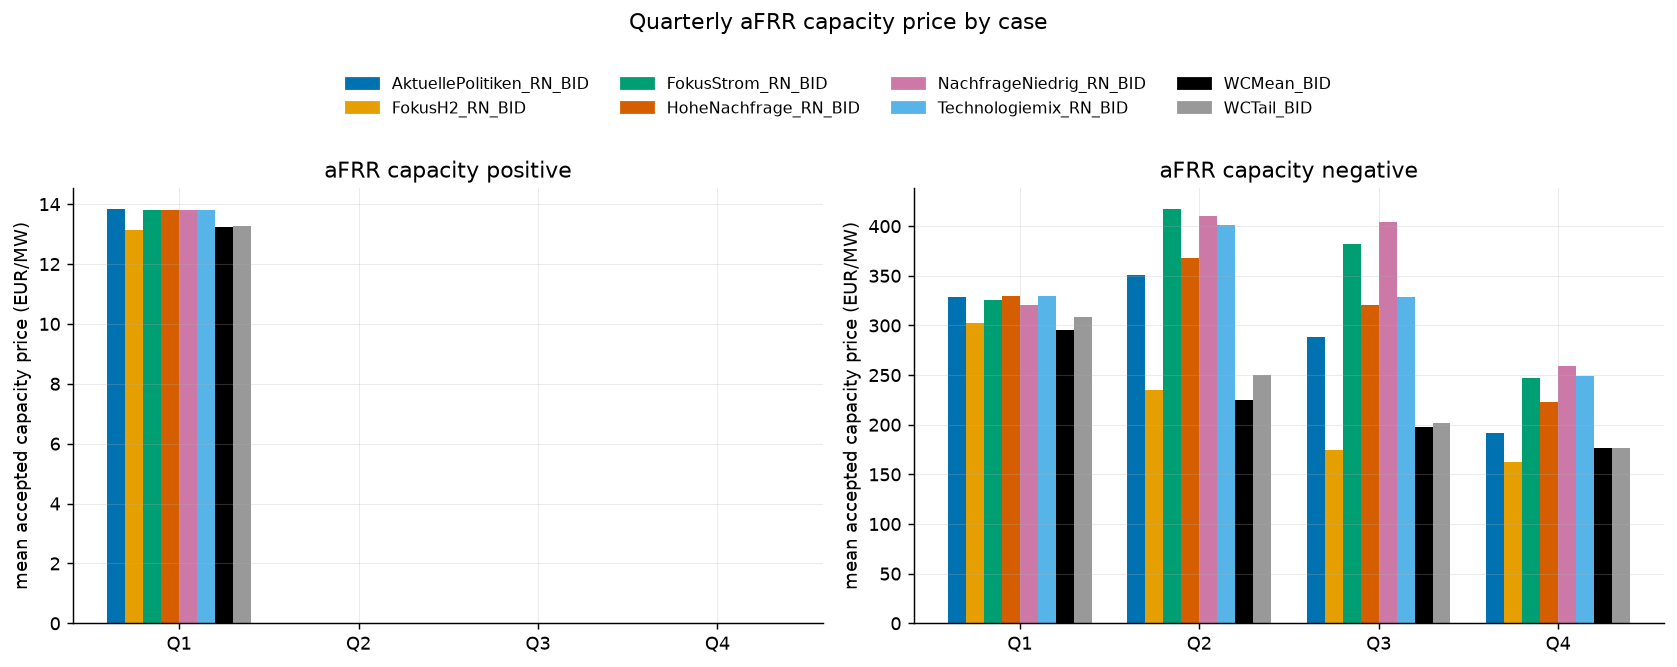

In [61]:
cases_present = [c for c in CASES if c in capacity_panel["case"].unique()]
quarters = [1, 2, 3, 4]
x = np.arange(len(quarters))
n = max(len(cases_present), 1)
width = 0.8 / n

fig, axes = plt.subplots(1, 2, figsize=(13, 4.8))
for ax, market in zip(axes, aiu.CAPACITY_MARKETS):
    sub = capacity_panel[capacity_panel["market_id"] == market]
    piv = sub.groupby(["quarter", "case"])["price_actor"].mean().unstack("case").reindex(quarters)
    for i, case in enumerate(cases_present):
        vals = piv[case] if case in piv.columns else pd.Series(np.nan, index=quarters)
        ax.bar(x + (i - (n - 1) / 2) * width, vals, width=width, color=CASE_COLOR[case])
    ax.set_xticks(x)
    ax.set_xticklabels([f"Q{q}" for q in quarters])
    ax.set_ylabel("mean accepted capacity price (EUR/MW)")
    ax.set_title(MARKET_LABEL.get(market, market))

handles = [plt.Rectangle((0, 0), 1, 1, color=CASE_COLOR[c]) for c in cases_present]
fig.suptitle("Quarterly aFRR capacity price by case", y=1.06)
fig.legend(handles, cases_present, loc="upper center", bbox_to_anchor=(0.5, 0.98),
           ncol=4, frameon=False, fontsize=9)
fig.tight_layout(rect=[0, 0, 1, 0.92])
plt.show()

In [62]:
cap_neg = capacity_panel[capacity_panel["market_id"] == "CRM_capacity_neg"]
cap_pos = capacity_panel[capacity_panel["market_id"] == "CRM_capacity_pos"]
by_case_q = cap_neg.groupby(["case", "quarter"])["price_actor"].mean().unstack("quarter")
q1_mean = by_case_q[1].mean() if 1 in by_case_q.columns else float("nan")
q4_mean = by_case_q[4].mean() if 4 in by_case_q.columns else float("nan")
highest_case = by_case_q.mean(axis=1).idxmax() if not by_case_q.empty else "n/a"
pos_offq_max = cap_pos.loc[cap_pos["quarter"] > 1, "price_actor"].abs().max()

pos_note = (f"clears almost exclusively in Q1 across every case (max price outside Q1 is only {pos_offq_max:.2f} EUR/MW)"
            if pos_offq_max < 1 else f"also clears outside Q1 (prices up to {pos_offq_max:.0f} EUR/MW)")
cap_trend = ("a clear seasonal decline" if q4_mean < 0.85 * q1_mean else
             "a seasonal rise" if q4_mean > 1.15 * q1_mean else "no strong seasonal trend")
display(Markdown(
    f"**Key finding:** aFRR capacity positive {pos_note}. aFRR capacity negative shows {cap_trend}, "
    f"averaging **{q1_mean:.0f} EUR/MW** in Q1 vs. **{q4_mean:.0f} EUR/MW** in Q4 across the "
    f"{len(cases_present)} cases, with **{highest_case}** the highest on average. None of this is driven by "
    f"direct actor bids (see the note above) — it's an indirect, dispatch-driven effect."
))

**Key finding:** aFRR capacity positive clears almost exclusively in Q1 across every case (max price outside Q1 is only 0.00 EUR/MW). aFRR capacity negative shows a clear seasonal decline, averaging **317 EUR/MW** in Q1 vs. **211 EUR/MW** in Q4 across the 8 cases, with **NachfrageNiedrig_RN_BID** the highest on average. None of this is driven by direct actor bids (see the note above) — it's an indirect, dispatch-driven effect.

## B6. Quarterly aFRR energy price by case (aFRR energy positive / aFRR energy negative)

Same layout as Section B5, but for the aFRR *energy* markets instead of
capacity. Unlike the capacity pair, **aFRR energy negative is a market the new
actors actually bid into** (down-regulation / demand-increase — this is the
same market Sections B2–B4 analyze in detail, just re-cut here by case and
quarter instead of pooled). aFRR energy positive, by contrast, has no actor bids
at all (`demand_units.csv` only ever sets `bidding_CRM_energy_neg` for the new
units, never `bidding_CRM_energy_pos`), so it's the background-only half of
this pair, included for the same side-by-side comparison as Section B5.

3,371,424 matched (case, hour, market) aFRR-energy rows.


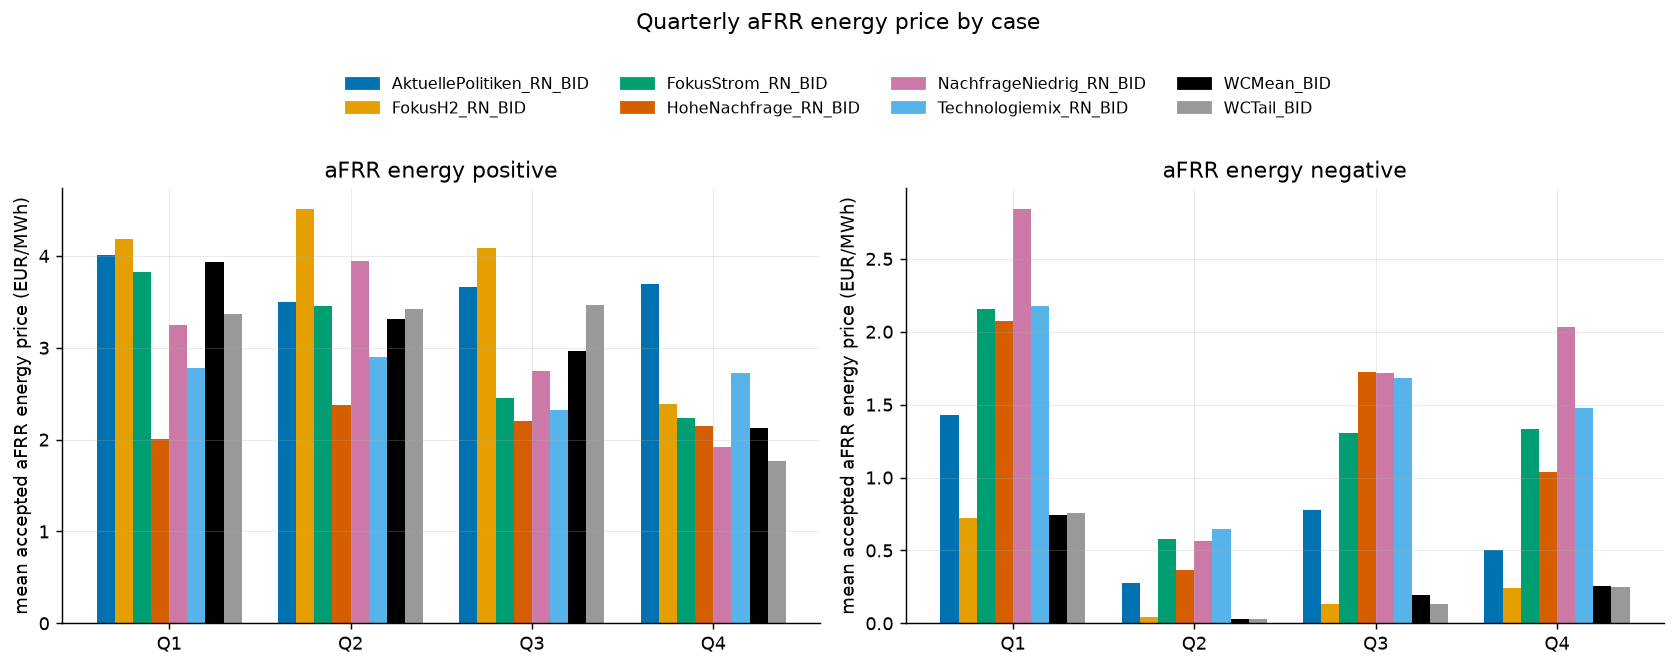

In [63]:
afrr_energy_panel = aiu.build_afrr_energy_panel(archives)
print(f"{len(afrr_energy_panel):,} matched (case, hour, market) aFRR-energy rows.")

cases_present_energy = [c for c in CASES if c in afrr_energy_panel["case"].unique()]
n = max(len(cases_present_energy), 1)
width = 0.8 / n

fig, axes = plt.subplots(1, 2, figsize=(13, 4.8))
for ax, market in zip(axes, aiu.AFRR_ENERGY_MARKETS):
    sub = afrr_energy_panel[afrr_energy_panel["market_id"] == market]
    piv = sub.groupby(["quarter", "case"])["price_actor"].mean().unstack("case").reindex(quarters)
    for i, case in enumerate(cases_present_energy):
        vals = piv[case] if case in piv.columns else pd.Series(np.nan, index=quarters)
        ax.bar(x + (i - (n - 1) / 2) * width, vals, width=width, color=CASE_COLOR[case])
    ax.set_xticks(x)
    ax.set_xticklabels([f"Q{q}" for q in quarters])
    ax.set_ylabel("mean accepted aFRR energy price (EUR/MWh)")
    ax.set_title(MARKET_LABEL.get(market, market))

handles = [plt.Rectangle((0, 0), 1, 1, color=CASE_COLOR[c]) for c in cases_present_energy]
fig.suptitle("Quarterly aFRR energy price by case", y=1.06)
fig.legend(handles, cases_present_energy, loc="upper center", bbox_to_anchor=(0.5, 0.98),
           ncol=4, frameon=False, fontsize=9)
fig.tight_layout(rect=[0, 0, 1, 0.92])
plt.show()

In [64]:
energy_pos = afrr_energy_panel[afrr_energy_panel["market_id"] == "CRM_energy_pos"]
energy_neg = afrr_energy_panel[afrr_energy_panel["market_id"] == "CRM_energy_neg"]
pos_by_case = energy_pos.groupby("case")["price_actor"].mean()
highest_pos_case = pos_by_case.idxmax() if not pos_by_case.empty else "n/a"
neg_level = energy_neg["price_actor"].abs().mean()
rest_mean = pos_by_case.drop(highest_pos_case).mean() if len(pos_by_case) > 1 else float("nan")

gap_pct = (pos_by_case.max() / rest_mean - 1) * 100 if rest_mean else float("nan")
display(Markdown(
    f"**Key finding:** **{highest_pos_case}** has the highest mean aFRR energy positive price "
    f"({pos_by_case.max():.1f} vs. {rest_mean:.1f} EUR/MWh average for the other cases) — a {gap_pct:.0f}% gap, "
    f"so the differences between cases on the up-regulation side are {'modest' if gap_pct < 50 else 'substantial'}. "
    f"aFRR energy negative prices have a mean magnitude of {neg_level:.3f} EUR/MWh across cases, and "
    f"(Section B7, next) the new actors supply most of its volume."
))

**Key finding:** **FokusH2_RN_BID** has the highest mean aFRR energy positive price (3.8 vs. 2.9 EUR/MWh average for the other cases) — a 29% gap, so the differences between cases on the up-regulation side are modest. aFRR energy negative prices have a mean magnitude of 0.942 EUR/MWh across cases, and (Section B7, next) the new actors supply most of its volume.

## B7. Quarterly aFRR energy negative volume: system context and each sector's share

Only the negative side — the new actors never bid into aFRR energy positive (see
Section B6), so a "positive" panel here would be a flat 0% line for all three
categories, every quarter, by construction, and isn't shown.

Left: average system-wide accepted volume in aFRR energy negative per quarter
(every participant — powerplants, storage, exchanges, existing demand, and the
new actors — summed on the demand side of each hour's clearing, which by
market balance equals the supply side; this is *not* the two sides added
together, which would double-count the same cleared MWh). Right: each
category's own accepted volume as a share of that system total, same quarters.
Two panels rather than one dual-axis plot (GW bars vs. % lines is too large a
scale mismatch, and the earlier Section B2 histogram/Section B6 chart already
established this notebook's convention of splitting mismatched scales into
side-by-side panels instead).

One striking thing this surfaces: **steel + cement + aviation/maritime
together already account for the large majority of all accepted
aFRR energy negative volume system-wide** in the scenarios finished so far — this
market looks like a fairly thin one that the new actors now dominate, not a
small addition to a large existing pool. Worth double-checking once more
cases/years are in, since it's currently based on only 2 of 8 cases.

In [65]:
share_panel = aiu.build_energy_neg_share_panel(archives)
print(f"{len(share_panel):,} scenario-hours.")

by_quarter = share_panel.groupby("quarter").agg(
    system_mw=("system_accepted_volume", "mean"),
    system_sum=("system_accepted_volume", "sum"),
    **{c: (c, "sum") for c in CATEGORIES},
).reindex(quarters)
for c in CATEGORIES:
    by_quarter[f"{c}_share_pct"] = by_quarter[c] / by_quarter["system_sum"] * 100
by_quarter[["system_mw"] + [f"{c}_share_pct" for c in CATEGORIES]].round(2)

1,605,995 scenario-hours.


,system_mw,steel_share_pct,cement_share_pct,aviation_maritime_share_pct
quarter,,,,
1,4756.65,32.22,66.45,0.0
2,5477.23,32.24,66.62,0.0
3,6161.89,32.82,66.53,0.0
4,5010.56,32.16,67.17,0.0


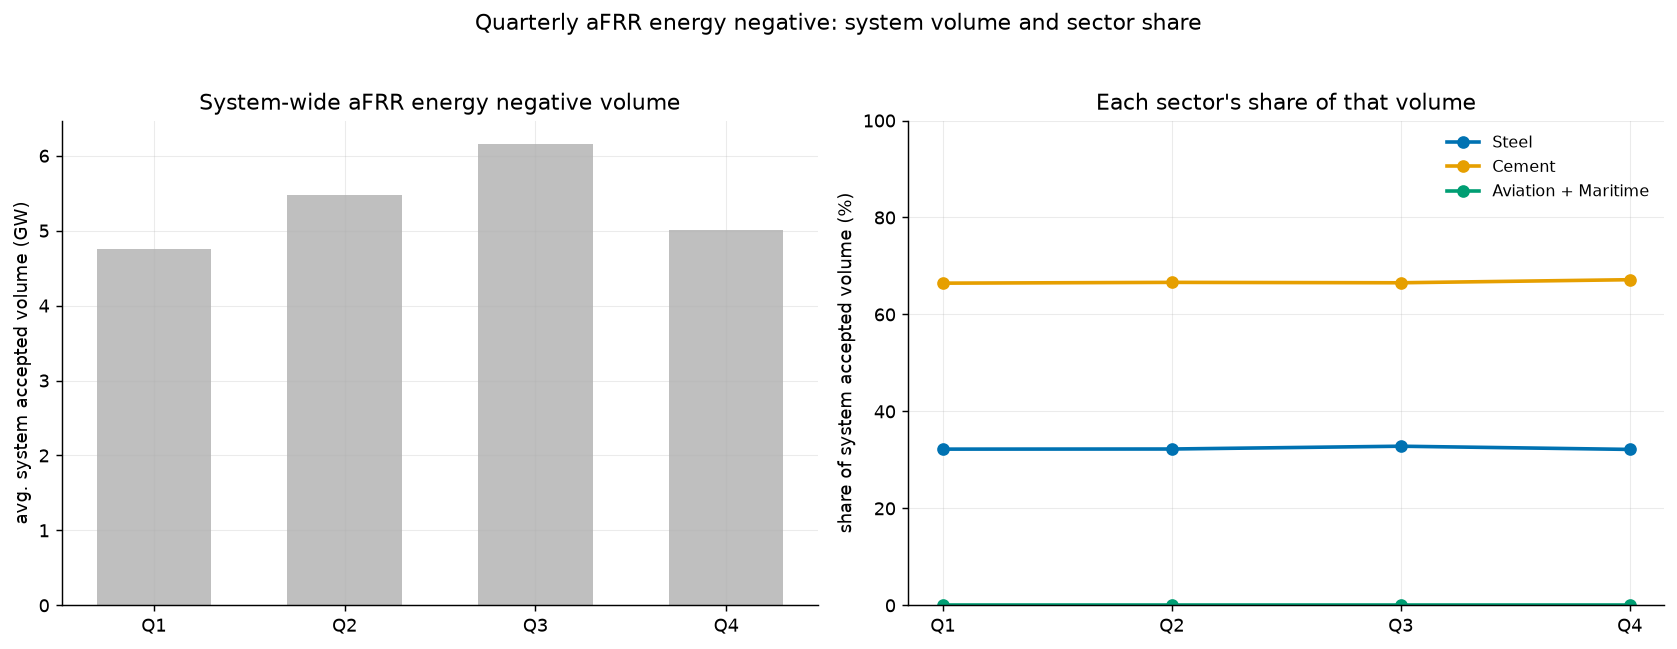

In [66]:
fig, (ax_vol, ax_share) = plt.subplots(1, 2, figsize=(13, 4.8))

ax_vol.bar([f"Q{q}" for q in quarters], by_quarter["system_mw"] / 1000,
           color="#BFBFBF", width=0.6)
ax_vol.set_ylabel("avg. system accepted volume (GW)")
ax_vol.set_title("System-wide aFRR energy negative volume")

for c in CATEGORIES:
    ax_share.plot([f"Q{q}" for q in quarters], by_quarter[f"{c}_share_pct"],
                  marker="o", color=COLOR[c], label=CATEGORY_LABEL[c], linewidth=2)
ax_share.set_ylabel("share of system accepted volume (%)")
ax_share.set_ylim(0, 100)
ax_share.set_title("Each sector's share of that volume")
ax_share.legend(frameon=False, fontsize=9)

fig.suptitle("Quarterly aFRR energy negative: system volume and sector share", y=1.03)
fig.tight_layout()
plt.show()

In [67]:
combined_share = by_quarter[[f"{c}_share_pct" for c in CATEGORIES]].sum(axis=1)
vol_start, vol_end = by_quarter["system_mw"].iloc[0], by_quarter["system_mw"].iloc[-1]
vol_change_pct = (vol_end / vol_start - 1) * 100 if vol_start else float("nan")

thin = combined_share.min() > 50
display(Markdown(
    f"**Key finding:** steel + cement + aviation/maritime together make up "
    f"**{combined_share.min():.1f}-{combined_share.max():.1f}%** of all accepted aFRR energy negative "
    f"volume system-wide across the quarters, while total system volume changes by **{vol_change_pct:+.0f}%** from Q1 to Q4. "
    + ("This market looks structurally thin: the new actors aren't a small addition to it, they're most of it."
       if thin else "The new actors are a minority of this market's volume.")
))

**Key finding:** steel + cement + aviation/maritime together make up **98.7-99.4%** of all accepted aFRR energy negative volume system-wide across the quarters, while total system volume changes by **+5%** from Q1 to Q4. This market looks structurally thin: the new actors aren't a small addition to it, they're most of it.

## B8. Combined view: system volume, actor share, and price by case (aFRR energy negative)

Puts Sections B6 and B7 on one chart, in the reference image's original layout:
gray bars are avg. system accepted volume per quarter (Section B7's left panel),
the %-label on each bar is steel + cement + aviation/maritime's **combined**
share of that volume, and the colored lines are each case's mean accepted
aFRR energy negative price per quarter (Section B6's data) plus a black `Mean` line
across cases — same pairing as the reference chart's per-scenario lines. Only
aFRR energy negative is shown, for the same reason as Section B7: the new actors
never bid into aFRR energy positive, so a second panel would just be a flat 0%.

Note this **is** a dual-axis chart (GW bars against a EUR/MWh price line
scale) — Sections B2, B5 and B6 deliberately split mismatched scales into
side-by-side panels instead, but this specific combined layout was asked for
directly, so it's built as asked here rather than substituted.

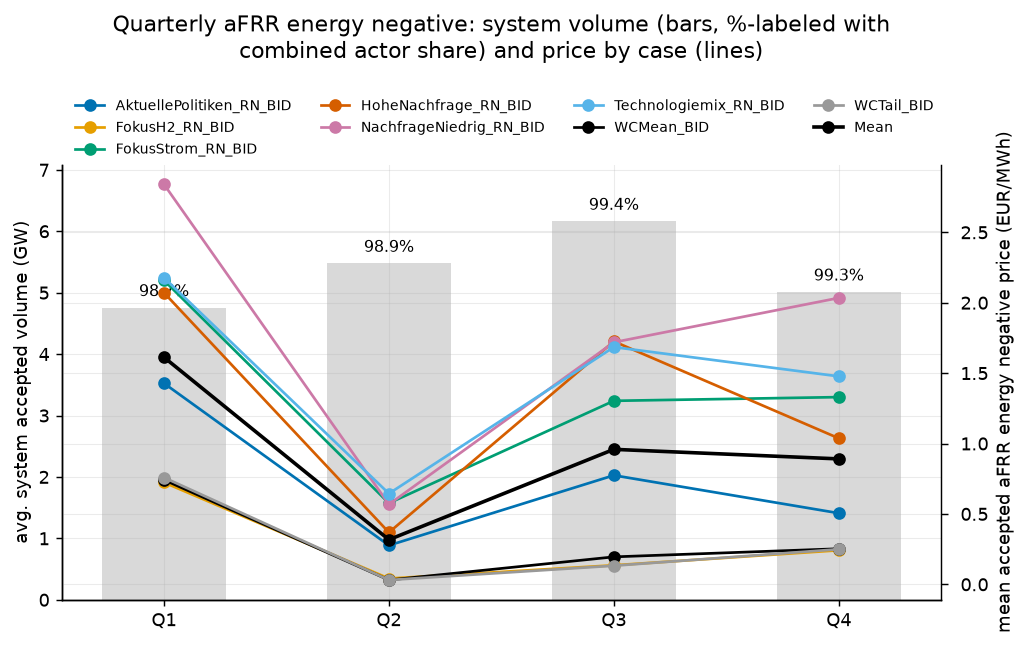

In [68]:
combined = share_panel.groupby("quarter").agg(
    system_mw=("system_accepted_volume", "mean"),
    system_sum=("system_accepted_volume", "sum"),
    **{c: (c, "sum") for c in CATEGORIES},
).reindex(quarters)
combined["actor_share_pct"] = combined[CATEGORIES].sum(axis=1) / combined["system_sum"] * 100

price_by_case = (
    afrr_energy_panel[afrr_energy_panel["market_id"] == "CRM_energy_neg"]
    .groupby(["quarter", "case"])["price_actor"].mean()
    .unstack("case").reindex(quarters)
)
price_by_case["Mean"] = price_by_case[cases_present_energy].mean(axis=1)

fig, ax1 = plt.subplots(figsize=(8, 5.2))
x = np.arange(len(quarters))
bar_vals = combined["system_mw"] / 1000
ax1.bar(x, bar_vals, color="#D9D9D9", width=0.55, zorder=1)
for xi, (val, pct) in enumerate(zip(bar_vals, combined["actor_share_pct"])):
    ax1.text(xi, val + bar_vals.max() * 0.02, f"{pct:.1f}%", ha="center", va="bottom", fontsize=9)
ax1.set_ylabel("avg. system accepted volume (GW)")
ax1.set_xticks(x)
ax1.set_xticklabels([f"Q{q}" for q in quarters])
ax1.set_ylim(0, bar_vals.max() * 1.15)

ax2 = ax1.twinx()
ax2.spines["right"].set_visible(True)
ax2.tick_params(axis="y", direction="out", length=4, pad=7)
for case in cases_present_energy:
    ax2.plot(x, price_by_case[case], marker="o", color=CASE_COLOR[case], linewidth=1.5, label=case)
ax2.plot(x, price_by_case["Mean"], marker="o", color="black", linewidth=2, label="Mean")
ax2.set_ylabel("mean accepted aFRR energy negative price (EUR/MWh)")

ax2.legend(loc="upper left", bbox_to_anchor=(0, 1.18), ncol=4, frameon=False, fontsize=8)
ax1.set_title("Quarterly aFRR energy negative: system volume (bars, %-labeled with\n"
              "combined actor share) and price by case (lines)", y=1.22)
fig.tight_layout()
plt.show()

In [69]:
share_range = f"{combined['actor_share_pct'].min():.1f}-{combined['actor_share_pct'].max():.1f}%"
case_means = price_by_case[cases_present_energy].mean()
price_spread = case_means.max() - case_means.min() if len(case_means) else float("nan")

display(Markdown(
    f"**Key finding:** the combined actor share sits at **{share_range}** of system volume across the quarters, "
    f"while aFRR energy negative prices differ between cases by about {price_spread:.3f} EUR/MWh on average — "
    f"the actors account for {'most' if combined['actor_share_pct'].min() > 50 else 'part'} of the volume in this market; "
    f"see Section B2 for how the day-ahead price responds."
))

**Key finding:** the combined actor share sits at **98.7-99.4%** of system volume across the quarters, while aFRR energy negative prices differ between cases by about 1.505 EUR/MWh on average — the actors account for most of the volume in this market; see Section B2 for how the day-ahead price responds.

## B9. Redispatch volume/cost and renewable curtailment by case

A system-level view rather than an actor-specific one: `market_id == "redispatch"`
in `market_orders.csv` covers every unit (not just steel/cement/aviation), and
renewable curtailment here means wind/solar units whose output was cut downward
via redispatch for grid congestion — identified by cross-referencing each
scenario's own `powerplant_units.csv` (`technology` in `solar`, `onshore wind`,
`offshore wind AC/DC`) against `unit_id` in the redispatch rows.

Same balance check as aFRR energy negative (Section B7): upward and downward
redispatch instructions balance system-wide per hour (every MW dispatched up
somewhere is matched by an equal MW dispatched down elsewhere), so
**redispatch volume and its cost are computed from the upward side only** —
summing both sides would double-count the same congestion-relief action.
Curtailment doesn't need this adjustment; it's inherently one-sided (only the
downward cut matters).

Each case's bars/lines average over whatever family/year scenarios have
finished for it so far (not a single fixed year) — same convention as
Sections B5, B6 and B8.

In [70]:
redispatch_panel = aiu.build_redispatch_panel(archives)
print(f"{len(redispatch_panel):,} scenarios with a redispatch summary.")

case_summary = (
    redispatch_panel.groupby("case")[
        ["redispatch_volume_twh", "avg_redispatch_cost"] + [f"{t}_curtailment_twh" for t in aiu.CURTAILMENT_SOURCES]
    ]
    .mean()
    .reindex(CASES)
    .dropna(how="all")
)
case_summary.round(2)

192 scenarios with a redispatch summary.


,redispatch_volume_twh,avg_redispatch_cost,Wind Offshore_curtailment_twh,Wind Onshore_curtailment_twh,Solar PV_curtailment_twh
case,,,,,
AktuellePolitiken_RN_BID,102.90,5.52,14.19,24.29,35.55
FokusH2_RN_BID,109.57,5.33,15.29,26.26,38.33
FokusStrom_RN_BID,96.93,6.67,12.89,23.01,35.06
HoheNachfrage_RN_BID,99.67,5.63,13.27,23.74,35.75
NachfrageNiedrig_RN_BID,98.46,5.68,13.42,24.34,36.11
Technologiemix_RN_BID,96.88,6.91,13.21,23.37,35.11
WCMean_BID,102.92,4.06,14.76,25.43,35.30
WCTail_BID,102.79,4.02,14.49,25.18,35.91


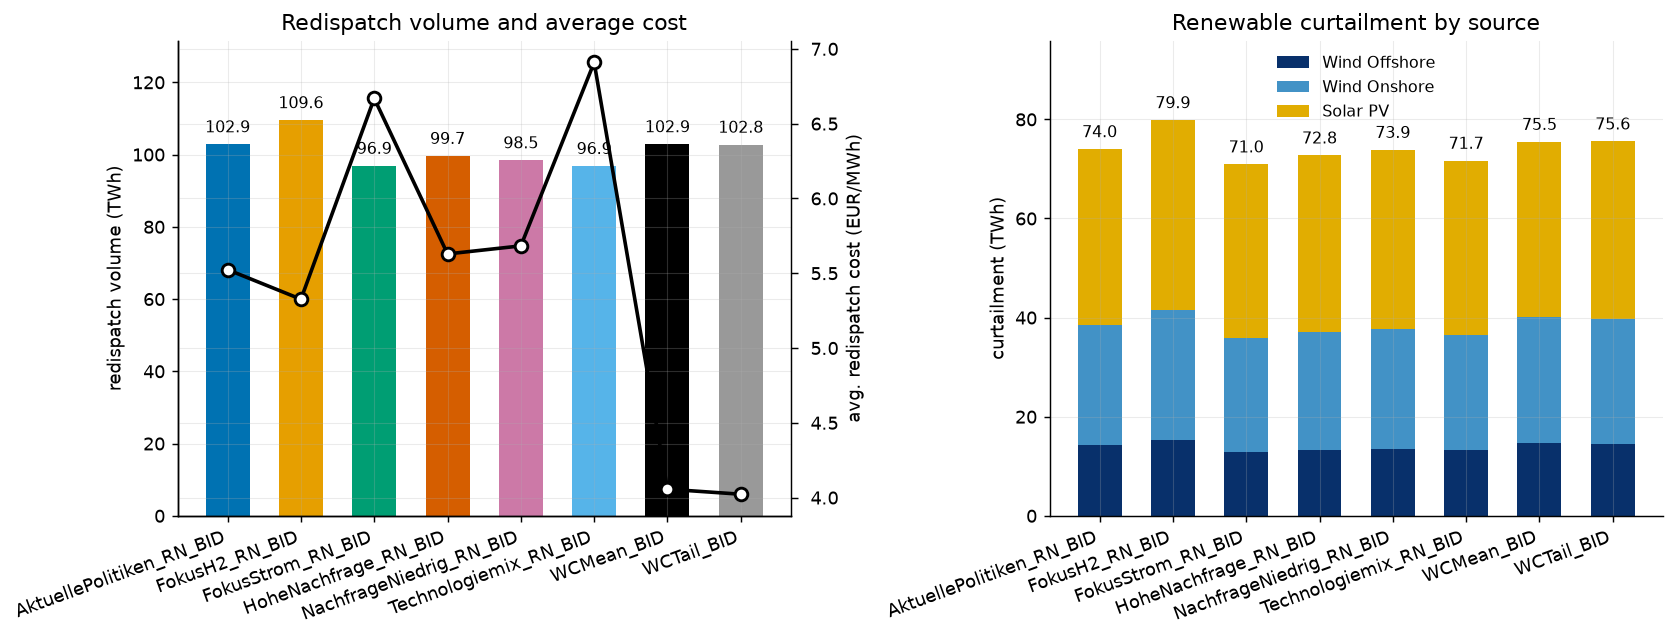

In [71]:
cases_rd = list(case_summary.index)
x = np.arange(len(cases_rd))

fig, (ax_rd, ax_ct) = plt.subplots(1, 2, figsize=(13, 5))

bars = ax_rd.bar(x, case_summary["redispatch_volume_twh"],
                  color=[CASE_COLOR[c] for c in cases_rd], width=0.6)
for xi, val in zip(x, case_summary["redispatch_volume_twh"]):
    ax_rd.text(xi, val + case_summary["redispatch_volume_twh"].max() * 0.02, f"{val:.1f}",
               ha="center", va="bottom", fontsize=9)
ax_rd.set_ylabel("redispatch volume (TWh)")
ax_rd.set_xticks(x)
ax_rd.set_xticklabels(cases_rd, rotation=20, ha="right")
ax_rd.set_ylim(0, case_summary["redispatch_volume_twh"].max() * 1.2)

ax_rd2 = ax_rd.twinx()
ax_rd2.spines["right"].set_visible(True)
ax_rd2.tick_params(axis="y", direction="out", length=4, pad=7)
ax_rd2.plot(x, case_summary["avg_redispatch_cost"], marker="o", color="black", linewidth=2,
            markerfacecolor="white", markeredgecolor="black", markeredgewidth=1.6, markersize=7, zorder=5)
ax_rd2.set_ylabel("avg. redispatch cost (EUR/MWh)")
ax_rd.set_title("Redispatch volume and average cost")

bottom = np.zeros(len(cases_rd))
for src in aiu.CURTAILMENT_SOURCES:
    vals = case_summary[f"{src}_curtailment_twh"].values
    ax_ct.bar(x, vals, bottom=bottom, color=SOURCE_COLOR[src], label=src, width=0.6)
    bottom += vals
for xi, val in zip(x, bottom):
    ax_ct.text(xi, val + bottom.max() * 0.02, f"{val:.1f}", ha="center", va="bottom", fontsize=9)
ax_ct.set_ylabel("curtailment (TWh)")
ax_ct.set_xticks(x)
ax_ct.set_xticklabels(cases_rd, rotation=20, ha="right")
ax_ct.set_ylim(0, bottom.max() * 1.2)
ax_ct.set_title("Renewable curtailment by source")
ax_ct.legend(frameon=False, fontsize=9)

fig.tight_layout()
plt.show()

In [72]:
biggest_source = (
    case_summary[[f"{s}_curtailment_twh" for s in aiu.CURTAILMENT_SOURCES]].sum().idxmax().replace("_curtailment_twh", "")
)
lowest_vol_case = case_summary["redispatch_volume_twh"].idxmin()
highest_cost_case = case_summary["avg_redispatch_cost"].idxmax()
same_case = lowest_vol_case == highest_cost_case

cost_clause = (
    f"it also has the highest average redispatch cost of any case "
    f"({case_summary.loc[highest_cost_case, 'avg_redispatch_cost']:.1f} EUR/MWh)"
    if same_case else
    f"while **{highest_cost_case}** has the highest average redispatch cost "
    f"({case_summary.loc[highest_cost_case, 'avg_redispatch_cost']:.1f} EUR/MWh)"
)
src_tot = case_summary[[f"{s}_curtailment_twh" for s in aiu.CURTAILMENT_SOURCES]].sum()
biggest_share = src_tot[f"{biggest_source}_curtailment_twh"] / src_tot.sum()
n_neg_cost = int((redispatch_panel["avg_redispatch_cost"] < 0).sum())
n_all_cost = len(redispatch_panel)
trace_note = (" (the most negative one traces to storage bids at a fixed -500 EUR/MWh)"
              if TREATMENT == "price-taker" and n_neg_cost else "")
display(Markdown(
    f"**Key finding:** {biggest_source} is the largest curtailed renewable source, "
    f"{biggest_share:.0%} of all curtailment across the cases. "
    f"**{lowest_vol_case}** has the lowest redispatch volume "
    f"({case_summary.loc[lowest_vol_case, 'redispatch_volume_twh']:.0f} TWh) -- {cost_clause}. "
    f"Average cost is a volume-weighted price on the upward side; {n_neg_cost} of {n_all_cost} scenarios have a negative "
    f"average{trace_note}, so read it together with volume rather than as a pure cost ranking."
))

**Key finding:** Solar PV is the largest curtailed renewable source, 48% of all curtailment across the cases. **Technologiemix_RN_BID** has the lowest redispatch volume (97 TWh) -- it also has the highest average redispatch cost of any case (6.9 EUR/MWh). Average cost is a volume-weighted price on the upward side; 2 of 192 scenarios have a negative average, so read it together with volume rather than as a pure cost ranking.

## B10. Cross-case summary: price impact and risk attitude

The headline question this whole notebook is really asking: **how much do
these hard-to-abate sectors move electricity prices, and does that depend on
how conservatively the actors sized their own demand?**

All 8 cases -- 6 risk-neutral (`_RN`) plus the two risk-averse ones (`WCMean`,
`WCTail`) -- are simulated against the *same* 6 families. The difference
isn't how many futures each case is tested against (it's always all 6); it's
*how the actor's demand decision was derived* before that stress test: an
`_RN` case commits to one fixed demand profile per year (identical across all
6 family subfolders, per the scenario design), while `WCMean`/`WCTail` derive
their demand from the mean/tail of the outcome distribution *across* those
same 6 families. So the chart below doesn't impose a "single dot vs. a
spread" distinction by design -- every case gets one point per finished
family, and the **width of that spread is itself the risk-attitude finding**:
a tight cluster means this case's committed demand produces a consistent
price effect regardless of which future materializes; a wide spread means
the realized impact is highly sensitive to that guess.

All 8 `_BID` cases have all 6 families finished, so every spread below is a full
6-family spread. Remember these are `_BID` runs: part of the spread comes from actors
being curtailed in expensive hours, not only from different demand levels.

Families finished per case (out of 6):
case
AktuellePolitiken_RN_BID    6
FokusH2_RN_BID              6
FokusStrom_RN_BID           6
HoheNachfrage_RN_BID        6
NachfrageNiedrig_RN_BID     6
Technologiemix_RN_BID       6
WCMean_BID                  6
WCTail_BID                  6
Name: family, dtype: int64


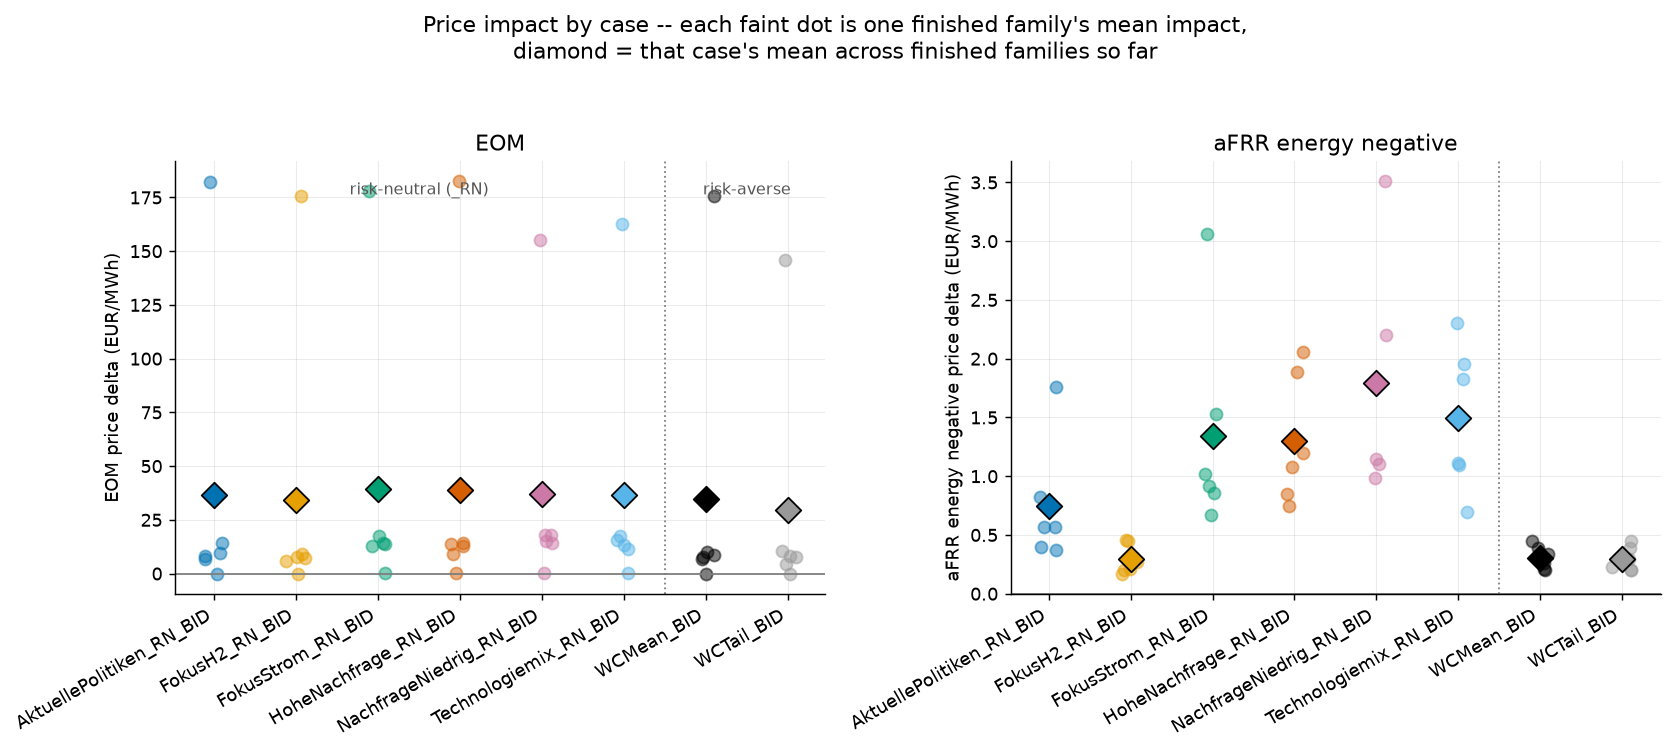

In [73]:
case_family_price = price_panel.groupby(["case", "family", "market_id"])["delta"].mean().reset_index()

case_order = [c for c in CASES if c in case_family_price["case"].unique()]
print("Families finished per case (out of 6):")
print(case_family_price[case_family_price["market_id"] == "EOM"].groupby("case")["family"].nunique()
      .reindex(case_order))

rn_present = [c for c in case_order if c in RN_LIKE]
wc_present = [c for c in case_order if c not in RN_LIKE]
divider_x = len(rn_present) - 0.5  # dynamic: only meaningful once both groups have data

rng = np.random.default_rng(0)
fig, axes = plt.subplots(1, 2, figsize=(13, 5.5))
for ax, market in zip(axes, ["EOM", "CRM_energy_neg"]):
    sub = case_family_price[case_family_price["market_id"] == market]
    for i, c in enumerate(case_order):
        vals = sub.loc[sub["case"] == c, "delta"].values
        if len(vals) == 0:
            continue
        jitter = rng.uniform(-0.12, 0.12, size=len(vals))
        ax.scatter(np.full(len(vals), i) + jitter, vals, color=CASE_COLOR[c], alpha=0.5, s=45, zorder=2)
        ax.scatter([i], [vals.mean()], color=CASE_COLOR[c], marker="D", s=100,
                   edgecolor="black", linewidth=1, zorder=3)
    ax.axhline(0, color=COLOR["baseline"], linewidth=1)
    if rn_present and wc_present:
        ax.axvline(divider_x, color=COLOR["baseline"], linewidth=1, linestyle=":")
    ax.set_xticks(range(len(case_order)))
    ax.set_xticklabels(case_order, rotation=30, ha="right")
    ax.set_ylabel(f"{MARKET_LABEL.get(market, market)} price delta (EUR/MWh)")
    ax.set_title(MARKET_LABEL.get(market, market))
if rn_present and wc_present:
    y0, y1 = axes[0].get_ylim()
    axes[0].text((len(rn_present) - 1) / 2, y1 * 0.92, "risk-neutral (_RN)",
                 ha="center", fontsize=9, color="#555")
    axes[0].text(len(rn_present) + (len(wc_present) - 1) / 2, y1 * 0.92, "risk-averse",
                 ha="center", fontsize=9, color="#555")
fig.suptitle("Price impact by case -- each faint dot is one finished family's mean impact,\n"
             "diamond = that case's mean across finished families so far", y=1.04)
fig.tight_layout()
plt.show()

In [74]:
eom_stats = (
    case_family_price[case_family_price["market_id"] == "EOM"]
    .groupby("case")["delta"].agg(["mean", "std", "count"])
    .reindex(case_order).dropna()
)
widest = eom_stats["std"].idxmax() if eom_stats["std"].notna().any() else None
rn_mean = eom_stats.loc[eom_stats.index.isin(rn_present), "mean"].mean() if rn_present else float("nan")
wc_mean = eom_stats.loc[eom_stats.index.isin(wc_present), "mean"].mean() if wc_present else float("nan")

msg = "**Key finding:** "
if widest is not None:
    msg += (
        f"**{widest}** currently shows the widest spread in EOM impact across its finished "
        f"families (std = {eom_stats.loc[widest, 'std']:.1f} EUR/MWh over "
        f"{int(eom_stats.loc[widest, 'count'])} families) — its committed demand level is highly "
        f"sensitive to which future actually plays out. "
    )
if wc_present and rn_present:
    typical_std = eom_stats["std"].mean()
    gap = rn_mean - wc_mean
    verdict = (
        "a gap smaller than the typical within-case spread, so no clear risk-attitude effect is visible"
        if abs(gap) < typical_std else
        ("risk-averse cases sit clearly lower" if gap > 0 else "risk-averse cases sit clearly higher")
    )
    msg += (
        f"The risk-averse case(s) ({', '.join(wc_present)}) average **{wc_mean:.1f} EUR/MWh** mean "
        f"impact vs. **{rn_mean:.1f} EUR/MWh** for the risk-neutral cases — a difference of "
        f"{gap:+.1f} against a typical within-case spread of {typical_std:.1f} EUR/MWh: {verdict}. "
        f"Run-to-run noise with identical inputs is quantified in Section B12."
    )
else:
    msg += "The risk-neutral-vs-hedged comparison isn't meaningful yet — one side has no finished data."
display(Markdown(msg))

**Key finding:** **AktuellePolitiken_RN_BID** currently shows the widest spread in EOM impact across its finished families (std = 71.5 EUR/MWh over 6 families) — its committed demand level is highly sensitive to which future actually plays out. The risk-averse case(s) (WCMean_BID, WCTail_BID) average **32.1 EUR/MWh** mean impact vs. **37.1 EUR/MWh** for the risk-neutral cases — a difference of +5.0 against a typical within-case spread of 65.8 EUR/MWh: a gap smaller than the typical within-case spread, so no clear risk-attitude effect is visible. Run-to-run noise with identical inputs is quantified in Section B12.

### The same view, year by year

Each row is one year, with the same cases, the same dot-per-family and diamond-per-case encoding, and **its own y-axis in every panel**: on a shared axis the 2040 outlier (about 700 EUR/MWh) flattens every other year, so read values from the ticks and do not compare bar heights across rows by eye. A dot is one family's mean impact in that year (6 dots per case per year).

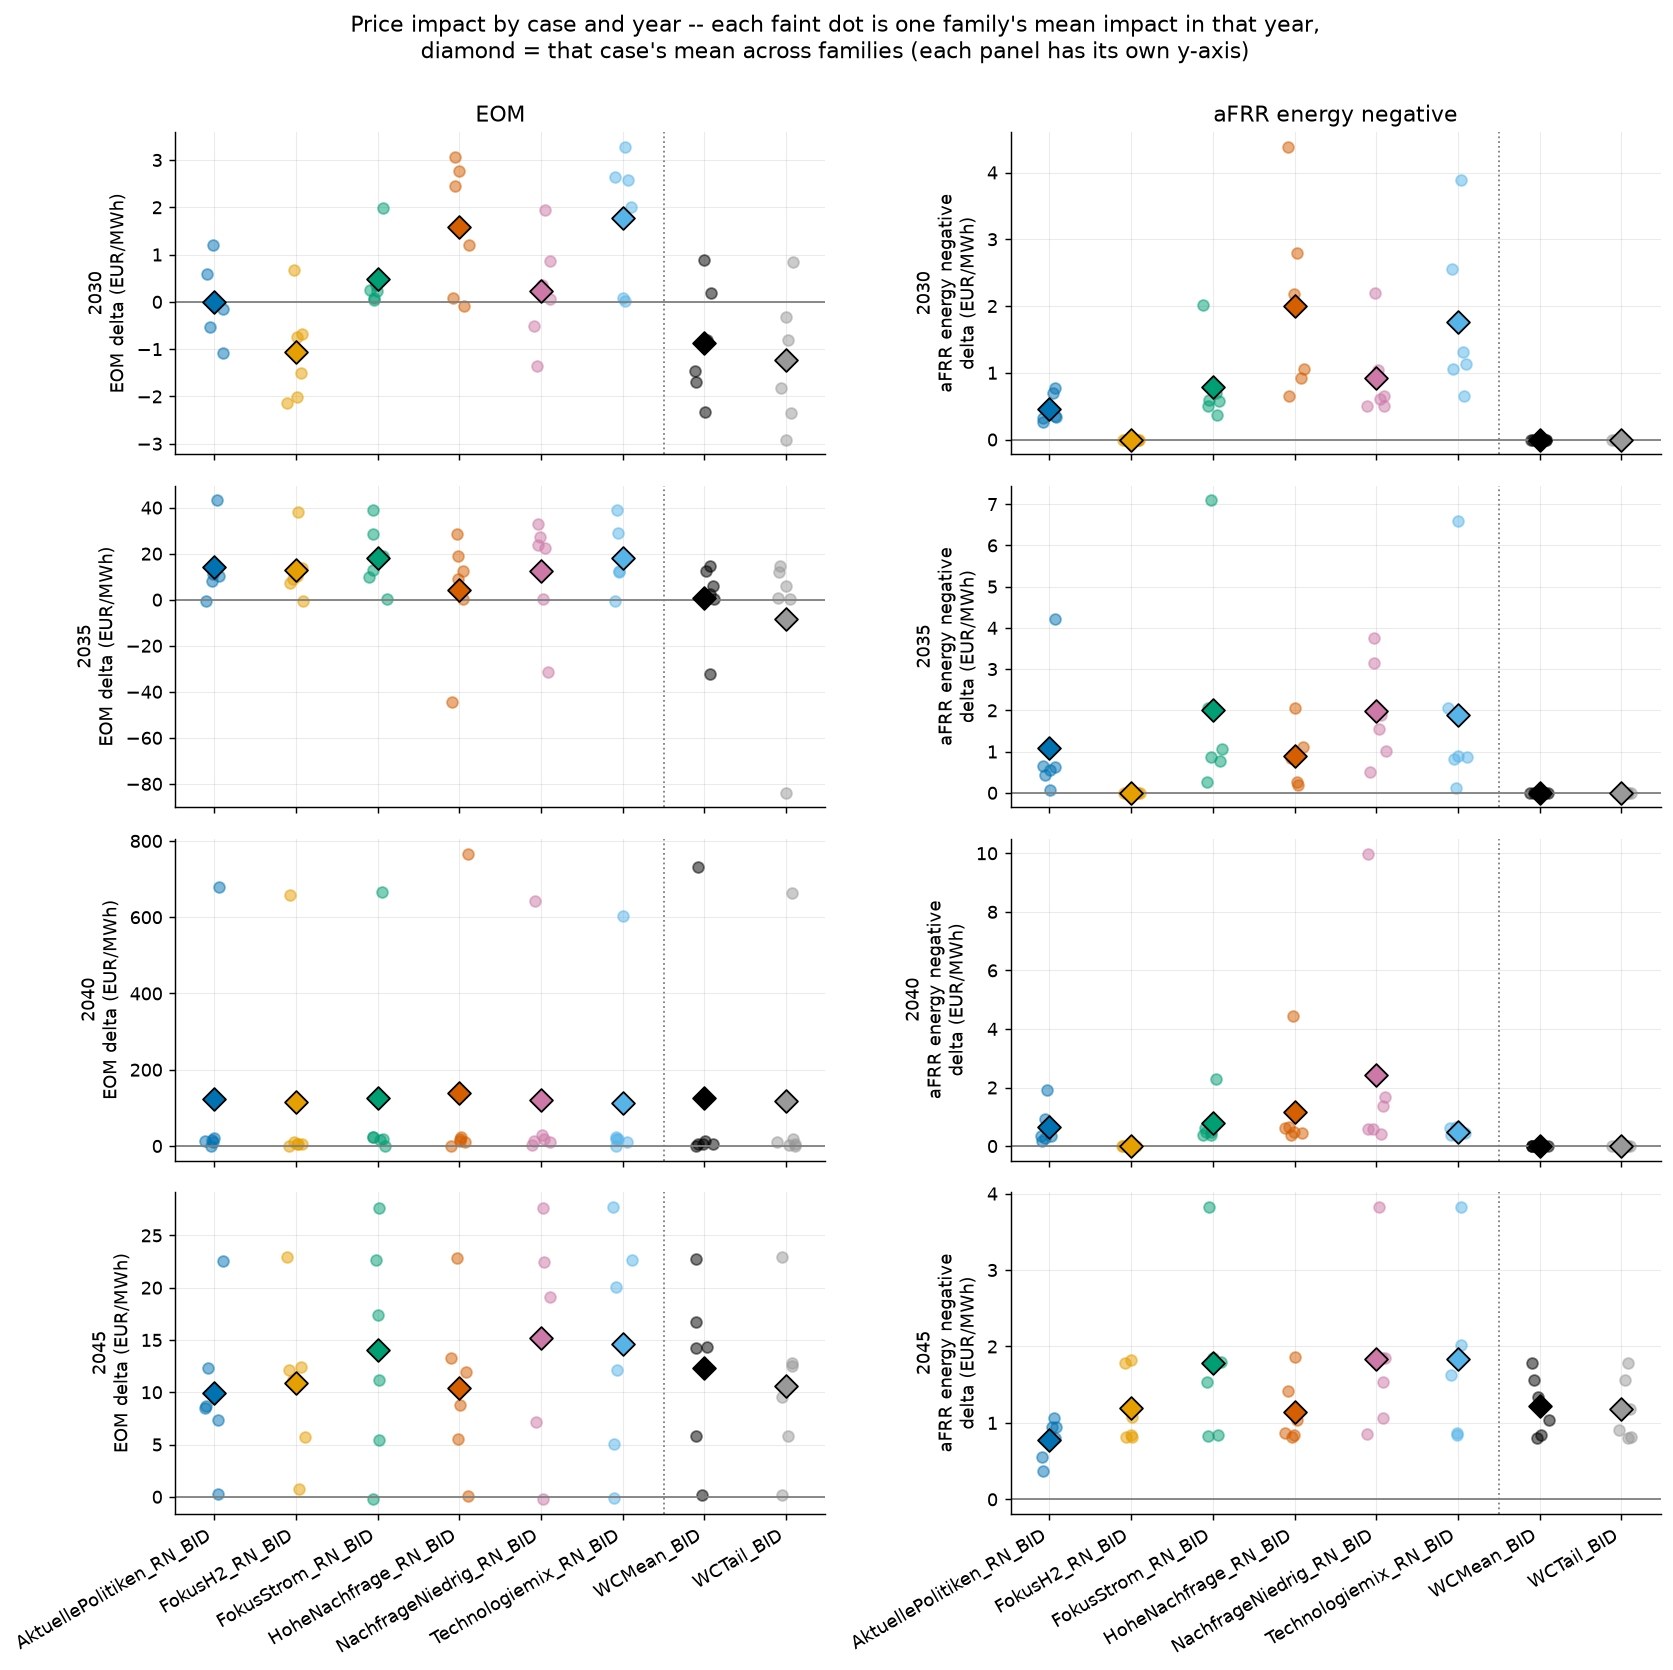

In [75]:
case_family_year = price_panel.groupby(["case", "family", "year", "market_id"])["delta"].mean().reset_index()
years_cf = sorted(case_family_year["year"].unique())
markets_cf = ["EOM", "CRM_energy_neg"]

rng_y = np.random.default_rng(1)
fig, axes = plt.subplots(len(years_cf), 2, figsize=(13, 3.2 * len(years_cf)), sharex=True, sharey=False)
for r, yr in enumerate(years_cf):
    for c_idx, market in enumerate(markets_cf):
        ax = axes[r, c_idx]
        sub = case_family_year[(case_family_year["year"] == yr) & (case_family_year["market_id"] == market)]
        for i, c in enumerate(case_order):
            vals = sub.loc[sub["case"] == c, "delta"].values
            if len(vals) == 0:
                continue
            jitter = rng_y.uniform(-0.12, 0.12, size=len(vals))
            ax.scatter(np.full(len(vals), i) + jitter, vals, color=CASE_COLOR[c], alpha=0.5, s=36, zorder=2)
            ax.scatter([i], [vals.mean()], color=CASE_COLOR[c], marker="D", s=80, edgecolor="black", linewidth=1, zorder=3)
        ax.axhline(0, color=COLOR["baseline"], linewidth=1)
        if rn_present and wc_present:
            ax.axvline(divider_x, color=COLOR["baseline"], linewidth=1, linestyle=":")
        ax.grid(alpha=0.25)
        if c_idx == 0:
            ax.set_ylabel(f"{yr}\nEOM delta (EUR/MWh)")
        else:
            ax.set_ylabel(f"{yr}\naFRR energy negative\ndelta (EUR/MWh)")
        if r == 0:
            ax.set_title(MARKET_LABEL.get(market, market))
for ax in axes[-1]:
    ax.set_xticks(range(len(case_order)))
    ax.set_xticklabels(case_order, rotation=30, ha="right")
fig.suptitle("Price impact by case and year -- each faint dot is one family's mean impact in that year,\n"
             "diamond = that case's mean across families (each panel has its own y-axis)", y=1.0)
fig.tight_layout()
plt.show()


In [76]:
eom_cfy = case_family_year[case_family_year["market_id"] == "EOM"]
eom_fy = eom_cfy.groupby(["family", "year"])["delta"].mean()
year_means = eom_fy.groupby("year").mean()
top_f, top_y = eom_fy.idxmax()
without_top = eom_fy.drop((top_f, top_y))
per_case_top = eom_cfy.groupby(["case", "family", "year"])["delta"].mean().groupby("case").idxmax()
n_top = sum((t[1], t[2]) == (top_f, top_y) for t in per_case_top)

sub_top = price_panel[(price_panel["market_id"] == "EOM") & (price_panel["family"] == top_f) & (price_panel["year"] == top_y)]
base_hours = int((sub_top[sub_top["case"] == sub_top["case"].iloc[0]]["price_baseline"] >= 1000).sum())
actor_hours = sub_top.groupby("case")["price_actor"].apply(lambda s: int((s >= 1000).sum()))
outlier = eom_fy.max() > 3 * max(without_top.max(), 1e-9)

text = (
    "**Key finding:** the all-case mean EOM impact by year is "
    + ", ".join(f"{y}: **{v:+.1f}**" for y, v in year_means.items())
    + f" EUR/MWh. The largest single family-year is **{top_f} {top_y}** (mean impact {eom_fy.max():+.0f} EUR/MWh), "
    f"the largest of its case's family-years in {n_top} of {len(per_case_top)} cases; without it the pooled mean impact over "
    f"all other family-years is {without_top.mean():+.1f} instead of {eom_fy.mean():+.1f} EUR/MWh. "
    f"In that system the no-actor baseline has {base_hours} hours at or above 1,000 EUR/MWh (price cap 3,000) and with the "
    f"actors {actor_hours.min():,}-{actor_hours.max():,} such hours depending on the case "
    f"({actor_hours.min() / 87.6:.0f}-{actor_hours.max() / 87.6:.0f}% of the year)."
)
if outlier:
    text += " That one system pulls the diamonds up, so the dots describe a typical year better than the means."
display(Markdown(text))


**Key finding:** the all-case mean EOM impact by year is 2030: **+0.1**, 2035: **+9.1**, 2040: **+122.1**, 2045: **+12.3** EUR/MWh. The largest single family-year is **fokusH2 2040** (mean impact +676 EUR/MWh), the largest of its case's family-years in 8 of 8 cases; without it the pooled mean impact over all other family-years is +8.0 instead of +35.9 EUR/MWh. In that system the no-actor baseline has 124 hours at or above 1,000 EUR/MWh (price cap 3,000) and with the actors 1,347-1,964 such hours depending on the case (15-22% of the year). That one system pulls the diamonds up, so the dots describe a typical year better than the means.

## B11. Grid maps at one timestep: congestion, redispatch, and the result

Three views of the **same hour** for every case of this part (same family and year, so the only
difference between panels is the case): line loading **before** redispatch, the redispatch
itself (net change per node, blue = upward, red = downward), and line loading **after**.

How the three are obtained, and what to keep in mind:
- **Before:** `grid_line_loading.csv` is written from the linear power flow of the market
  dispatch *before* the redispatch optimisation, so it is read as-is (loading = |flow| / `s_nom`).
- **Redispatch:** accepted `redispatch` orders summed per node (`node` column). Upward and
  downward volumes balance system-wide per hour, so the per-node *net* is what moves flows.
- **After:** the output does not store post-redispatch flows, so they are reconstructed as
  pre-redispatch flow + PTDF x net nodal redispatch (DC power-transfer matrix of the 94 lines,
  all 380 kV AC). The cell below validates this: over every congested hour of every case the
  worst line must come back to 100% loading, and it does not with the opposite sign.
- **Resolution:** the grid has 30 German nodes (44 buses incl. neighbours), not the
  hundreds of nodes of a detailed model, so bubbles and plants sit at node level and a
  node's bubble aggregates all units there. Plants are drawn at their node, not their site.
  The Germany outline is a coarse Natural Earth polygon.
- The hour is chosen automatically as the one congested in the most cases with the largest
  combined overload; set `TS` below to look at another hour (for example a windy hour, to
  see the usual north-down / south-up pattern instead).

In [77]:
import os
import geopandas as gpd
import pyogrio
from matplotlib.lines import Line2D

FAMILY, YEAR = "aktuellepolitiken", 2035
TS = None  # e.g. pd.Timestamp("2035-01-28 20:00"); None = auto-select

arch_g = archives[(archives["family"] == FAMILY) & (archives["year"] == YEAR)].set_index("case")
cases_g = [c for c in CASES if c in arch_g.index]

buses_g, lines_g = aiu.load_grid(cases_g[0], FAMILY, YEAR)
max_load = pd.DataFrame({
    c: (aiu.load_line_flows(c, FAMILY, YEAR, arch_g.loc[c, "path"]).abs()
        / lines_g["s_nom"].reindex(aiu.load_line_flows(c, FAMILY, YEAR, arch_g.loc[c, "path"]).columns).to_numpy()).max(axis=1)
    for c in cases_g
})
if TS is None:
    n_cong = (max_load > 1).sum(axis=1)
    overload = (max_load.clip(lower=1) - 1).sum(axis=1)
    TS = (pd.DataFrame({"n": n_cong, "o": overload}).sort_values(["n", "o"], ascending=False).index[0])
TS = pd.Timestamp(TS)
print(f"{FAMILY} {YEAR}, hour {TS}: congested in {(max_load.loc[TS] > 1).sum()} of {len(cases_g)} cases")

snaps = {c: aiu.grid_snapshot(c, FAMILY, YEAR, arch_g.loc[c, "path"], TS) for c in cases_g}

# validation of the post-redispatch reconstruction over all congested hours (one case)
c0 = cases_g[0]
fl = aiu.load_line_flows(c0, FAMILY, YEAR, arch_g.loc[c0, "path"])
rd0 = aiu.load_redispatch_nodal(c0, FAMILY, YEAR, arch_g.loc[c0, "path"])
b0, l0 = aiu.load_grid(c0, FAMILY, YEAR)
P0 = aiu.build_ptdf(b0, l0)
net0 = rd0.pivot_table(index="start_time", columns="node", values="net", aggfunc="sum").reindex(columns=b0["name"]).fillna(0)
ri = l0.index.get_indexer(fl.columns); cap0 = l0["s_nom"].reindex(fl.columns).to_numpy()
hrs = max_load.index[max_load[c0] > 1]
worst_after = [np.abs((fl.loc[t].to_numpy() + (P0 @ (net0.loc[t].to_numpy() if t in net0.index else np.zeros(len(b0))))[ri]) / cap0).max() for t in hrs]
worst_wrong = [np.abs((fl.loc[t].to_numpy() - (P0 @ (net0.loc[t].to_numpy() if t in net0.index else np.zeros(len(b0))))[ri]) / cap0).max() for t in hrs]
print(f"Validation on {c0}, {len(hrs)} congested hours: worst line after redispatch -> median {np.median(worst_after):.3f}, "
      f"max {np.max(worst_after):.3f}  (opposite sign: median {np.median(worst_wrong):.2f})")

aktuellepolitiken 2035, hour 2035-04-21 06:00:00: congested in 8 of 8 cases
Validation on AktuellePolitiken_RN_BID, 334 congested hours: worst line after redispatch -> median 1.000, max 1.000  (opposite sign: median 1.28)


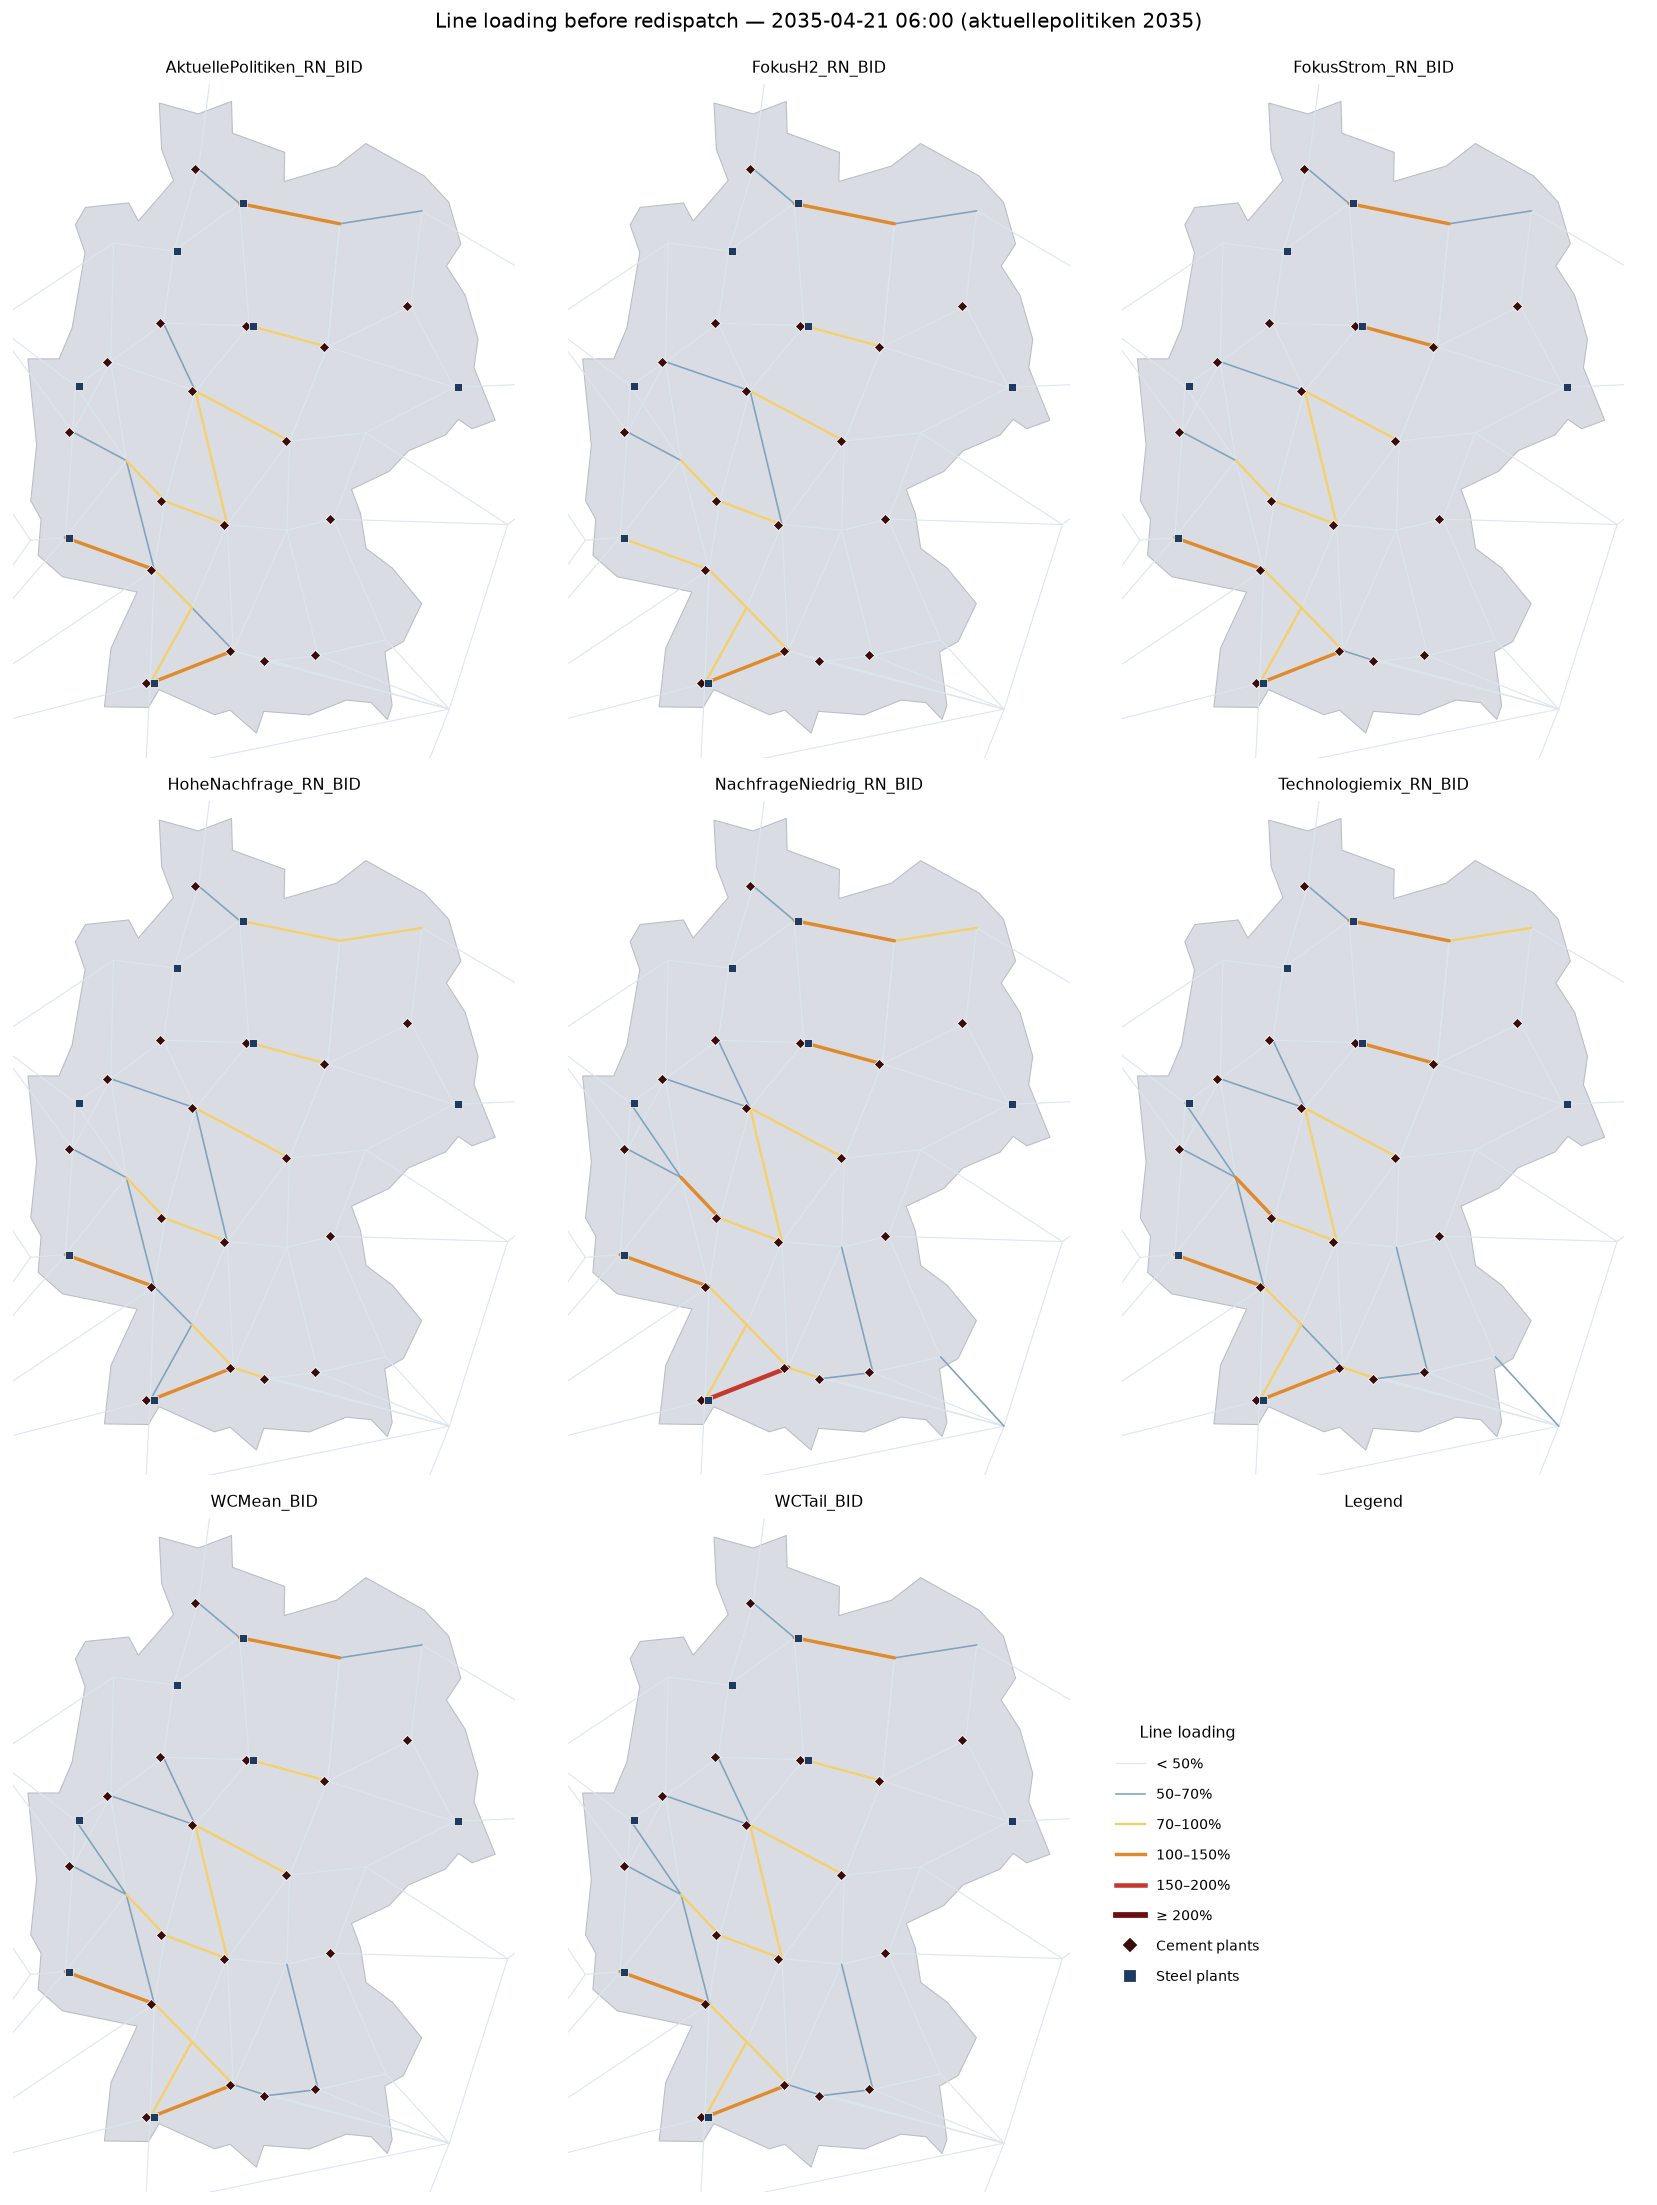

In [78]:
shp = os.path.join(os.path.dirname(pyogrio.__file__), "tests/fixtures/naturalearth_lowres/naturalearth_lowres.shp")
germany = gpd.read_file(shp).query("name == 'Germany'").geometry.iloc[0]

LOAD_BINS = [0.5, 0.7, 1.005, 1.5, 2.0]            # 1.005: float noise at exactly 100% stays in "70-100%"
LOAD_LABELS = ["< 50%", "50–70%", "70–100%", "100–150%", "150–200%", "≥ 200%"]
LOAD_COLORS = ["#dbe6ee", "#7fa3bd", "#f4cf6a", "#e08a2e", "#c4382f", "#6b0f10"]
LOAD_WIDTHS = [0.6, 0.9, 1.3, 1.9, 2.5, 3.2]
XLIM, YLIM = (5.7, 15.4), (47.0, 55.2)
UP_COLOR, DOWN_COLOR = "#2f77b5", "#d6604d"

def base_map(ax, title):
    ax.add_patch(plt.Polygon(np.array(germany.exterior.coords), fc="#d9dde3", ec="#b9bec6", lw=0.6, zorder=0))
    ax.set_xlim(*XLIM); ax.set_ylim(*YLIM); ax.set_aspect(1 / np.cos(np.radians(51)))
    ax.axis("off"); ax.set_title(title, fontsize=9)

def draw_plants(ax, s):
    pos = s["buses"].set_index("name")[["x", "y"]]
    for tech, marker, color, dx in [("cement", "D", "#3a0d0d", -0.07), ("steel", "s", "#1f3a5f", 0.07)]:
        for node in s["plants"][tech]:
            ax.scatter(pos.loc[node, "x"] + dx, pos.loc[node, "y"], marker=marker, s=16, c=color,
                       ec="white", lw=0.4, zorder=6)

def draw_loading(ax, s, key):
    pos = s["buses"].set_index("name")[["x", "y"]]
    cls = np.digitize(s[key], LOAD_BINS)
    for i in np.argsort(cls):                       # heavily loaded lines drawn last, on top
        ln = s["lines"].iloc[i]; a, b = pos.loc[ln.bus0], pos.loc[ln.bus1]
        ax.plot([a.x, b.x], [a.y, b.y], color=LOAD_COLORS[cls[i]], lw=LOAD_WIDTHS[cls[i]],
                solid_capstyle="round", zorder=2 + cls[i])
    draw_plants(ax, s)

vmax_net = max(np.abs(s["net"]).max() for s in snaps.values())
def bubble_area(v):
    return 40 + (abs(v) / vmax_net) * 700

def draw_redispatch(ax, s):
    pos = s["buses"].set_index("name")[["x", "y"]]
    for node, v in s["net"].items():
        if abs(v) >= 1:
            ax.scatter(pos.loc[node, "x"], pos.loc[node, "y"], s=bubble_area(v),
                       c=UP_COLOR if v > 0 else DOWN_COLOR, alpha=0.85, ec="white", lw=0.4, zorder=4)
    draw_plants(ax, s)

plant_handles = [Line2D([], [], marker="D", ls="", c="#3a0d0d", ms=5, label="Cement plants"),
                 Line2D([], [], marker="s", ls="", c="#1f3a5f", ms=5, label="Steel plants")]
load_handles = [Line2D([], [], color=c, lw=w, label=l) for c, w, l in zip(LOAD_COLORS, LOAD_WIDTHS, LOAD_LABELS)] + plant_handles
size_steps = [g for g in (0.5, 1, 2, 4) if g * 1000 <= vmax_net * 1.05]
rd_handles = ([Line2D([], [], marker="o", ls="", c=UP_COLOR, ms=8, label="Upward redispatch"),
               Line2D([], [], marker="o", ls="", c=DOWN_COLOR, ms=8, label="Downward redispatch")] + plant_handles +
              [Line2D([], [], marker="o", ls="", mfc="none", mec="#444", ms=np.sqrt(bubble_area(g * 1000)), label=f"{g:g} GW")
               for g in size_steps])

def grid_figure(draw, handles, legend_title, suptitle, note=None):
    fig, axes = plt.subplots(3, 3, figsize=(13, 17))
    for ax, c in zip(axes.flat, cases_g):
        base_map(ax, c); draw(ax, snaps[c])
    for ax in list(axes.flat)[len(cases_g):]:
        ax.axis("off")
    leg = axes.flat[len(cases_g)]
    leg.set_title("Legend", fontsize=9)
    leg.legend(handles=handles, title=legend_title, loc="center left", frameon=False, fontsize=8,
               title_fontsize=9, labelspacing=1.1)
    if note:
        leg.text(0.02, 0.02, note, transform=leg.transAxes, fontsize=7.5, va="bottom")
    fig.suptitle(suptitle, y=0.995, fontsize=11); fig.tight_layout()
    plt.show()

ts_label = f"{TS:%Y-%m-%d %H:%M} ({FAMILY} {YEAR})"
grid_figure(lambda ax, s: draw_loading(ax, s, "pre"), load_handles, "Line loading",
            f"Line loading before redispatch — {ts_label}")

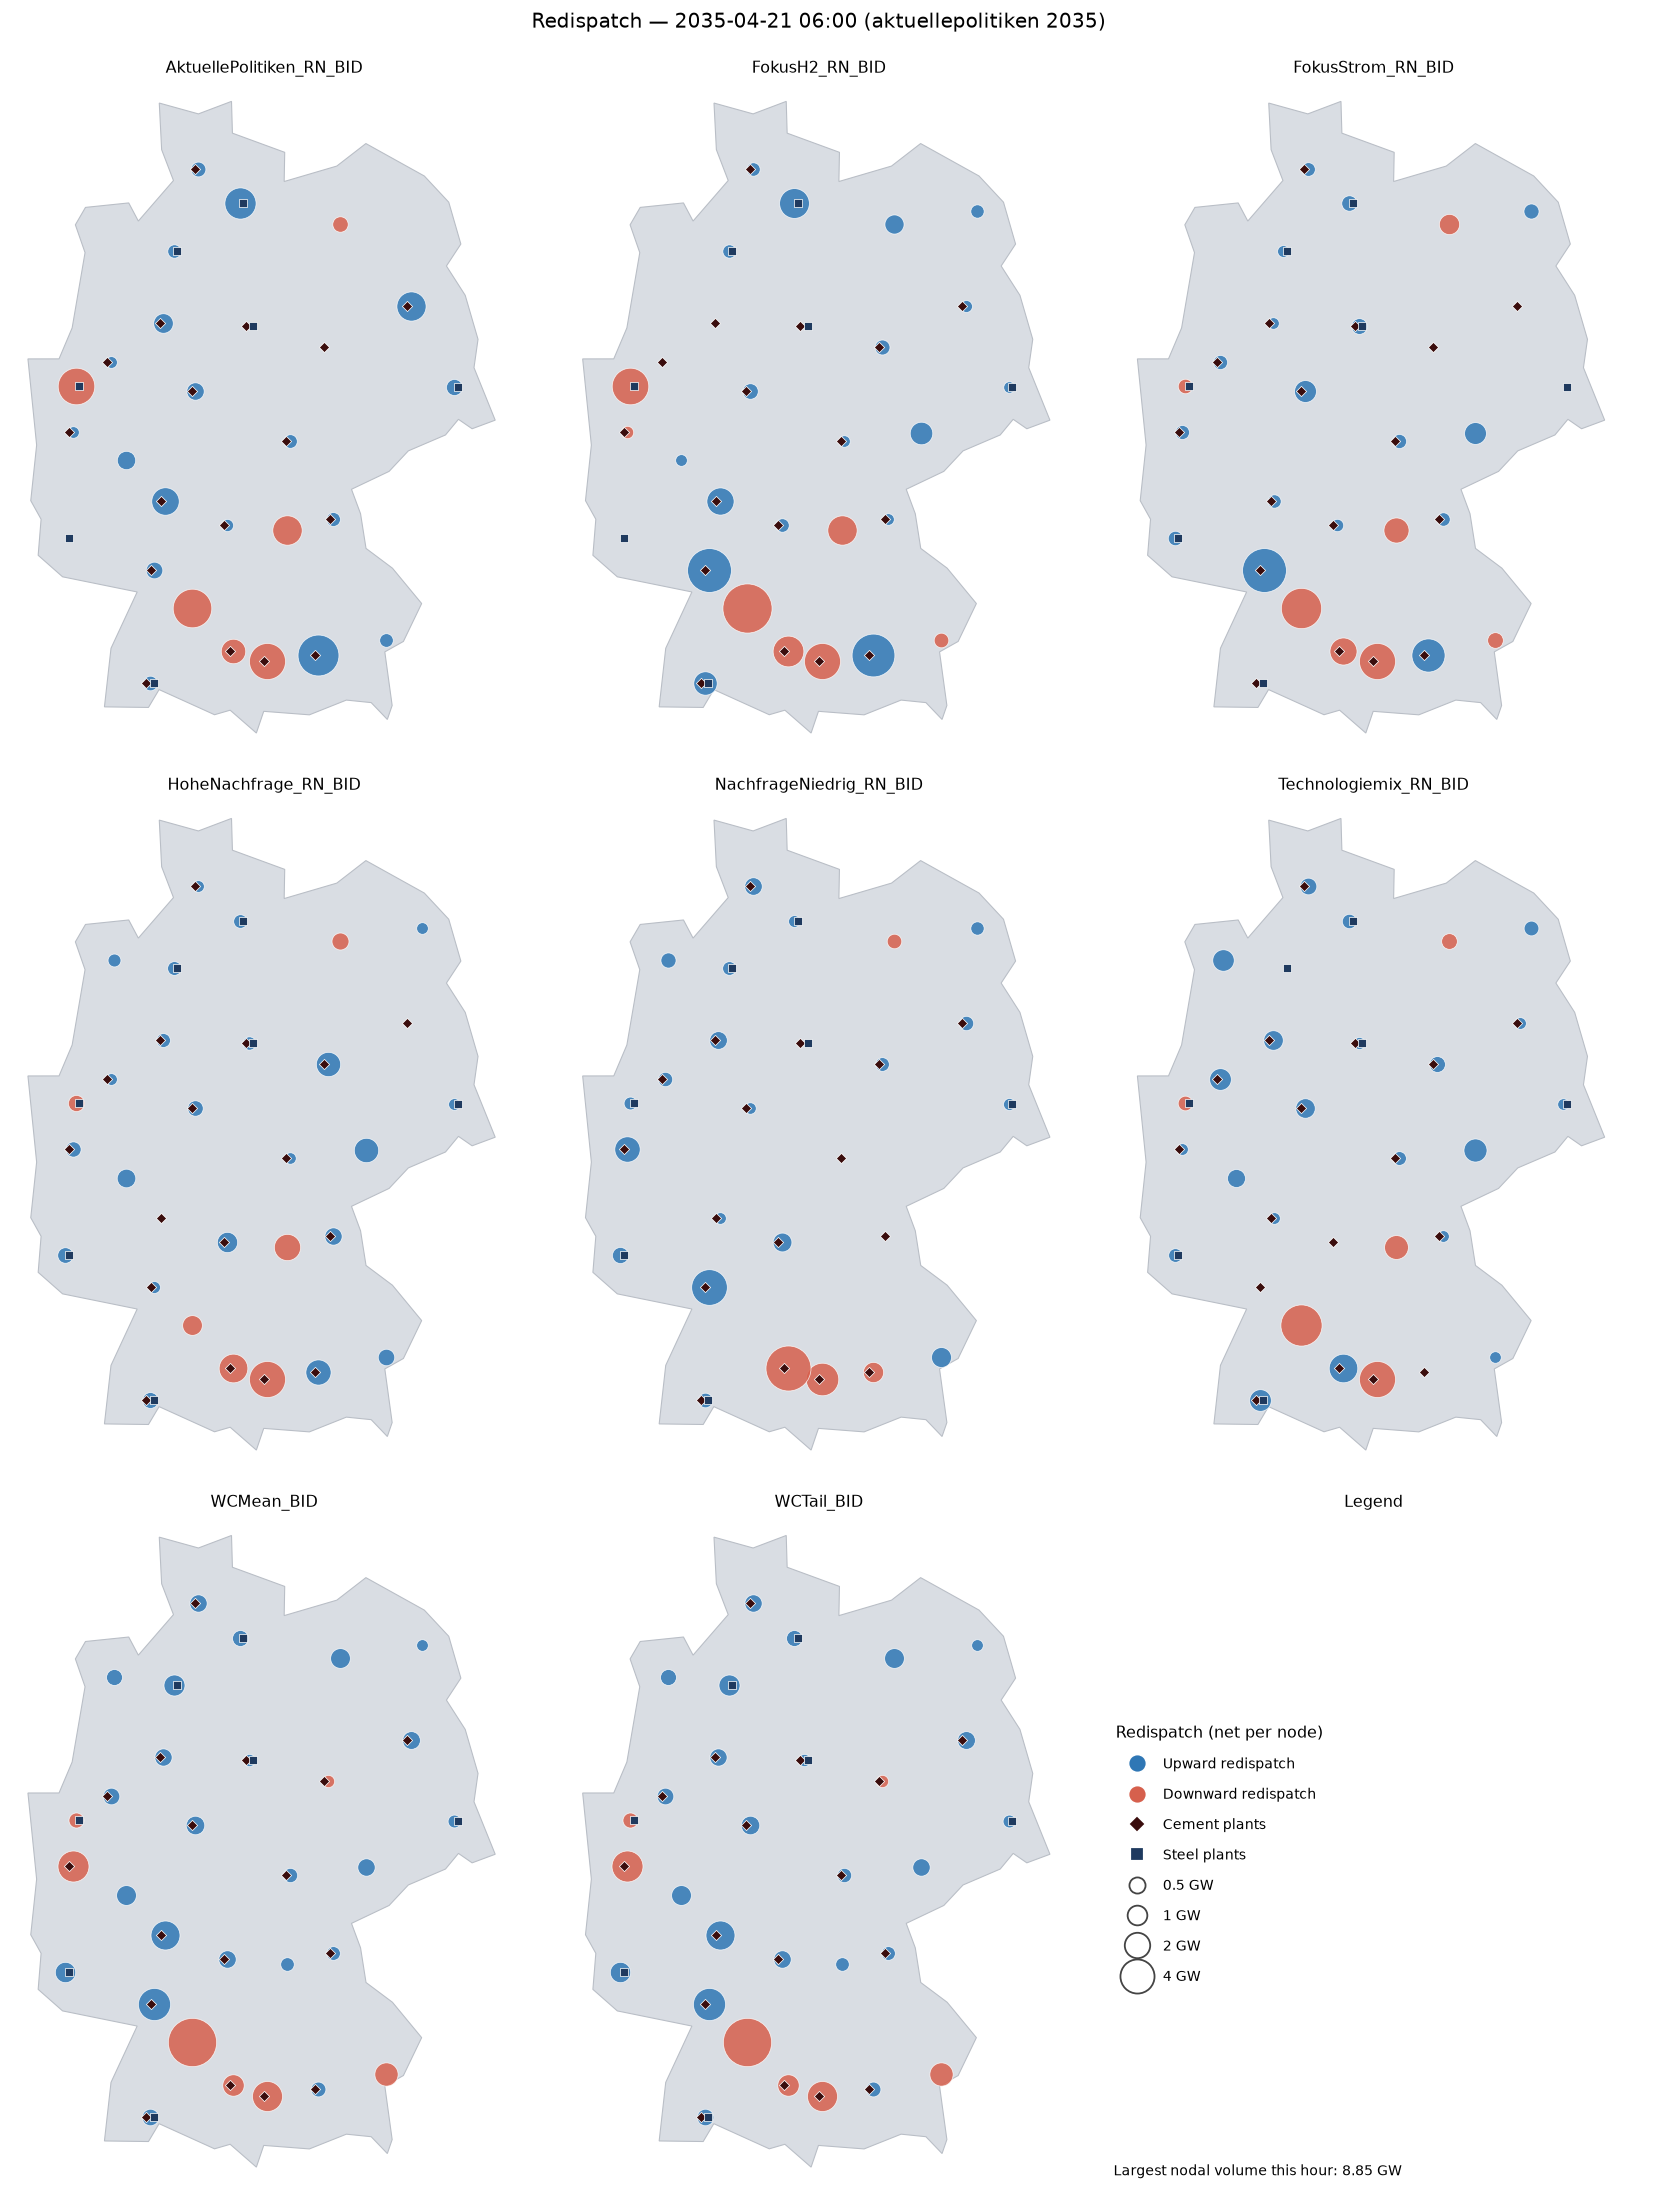

In [79]:
grid_figure(draw_redispatch, rd_handles, "Redispatch (net per node)",
            f"Redispatch — {ts_label}", note=f"Largest nodal volume this hour: {vmax_net / 1000:.2f} GW")

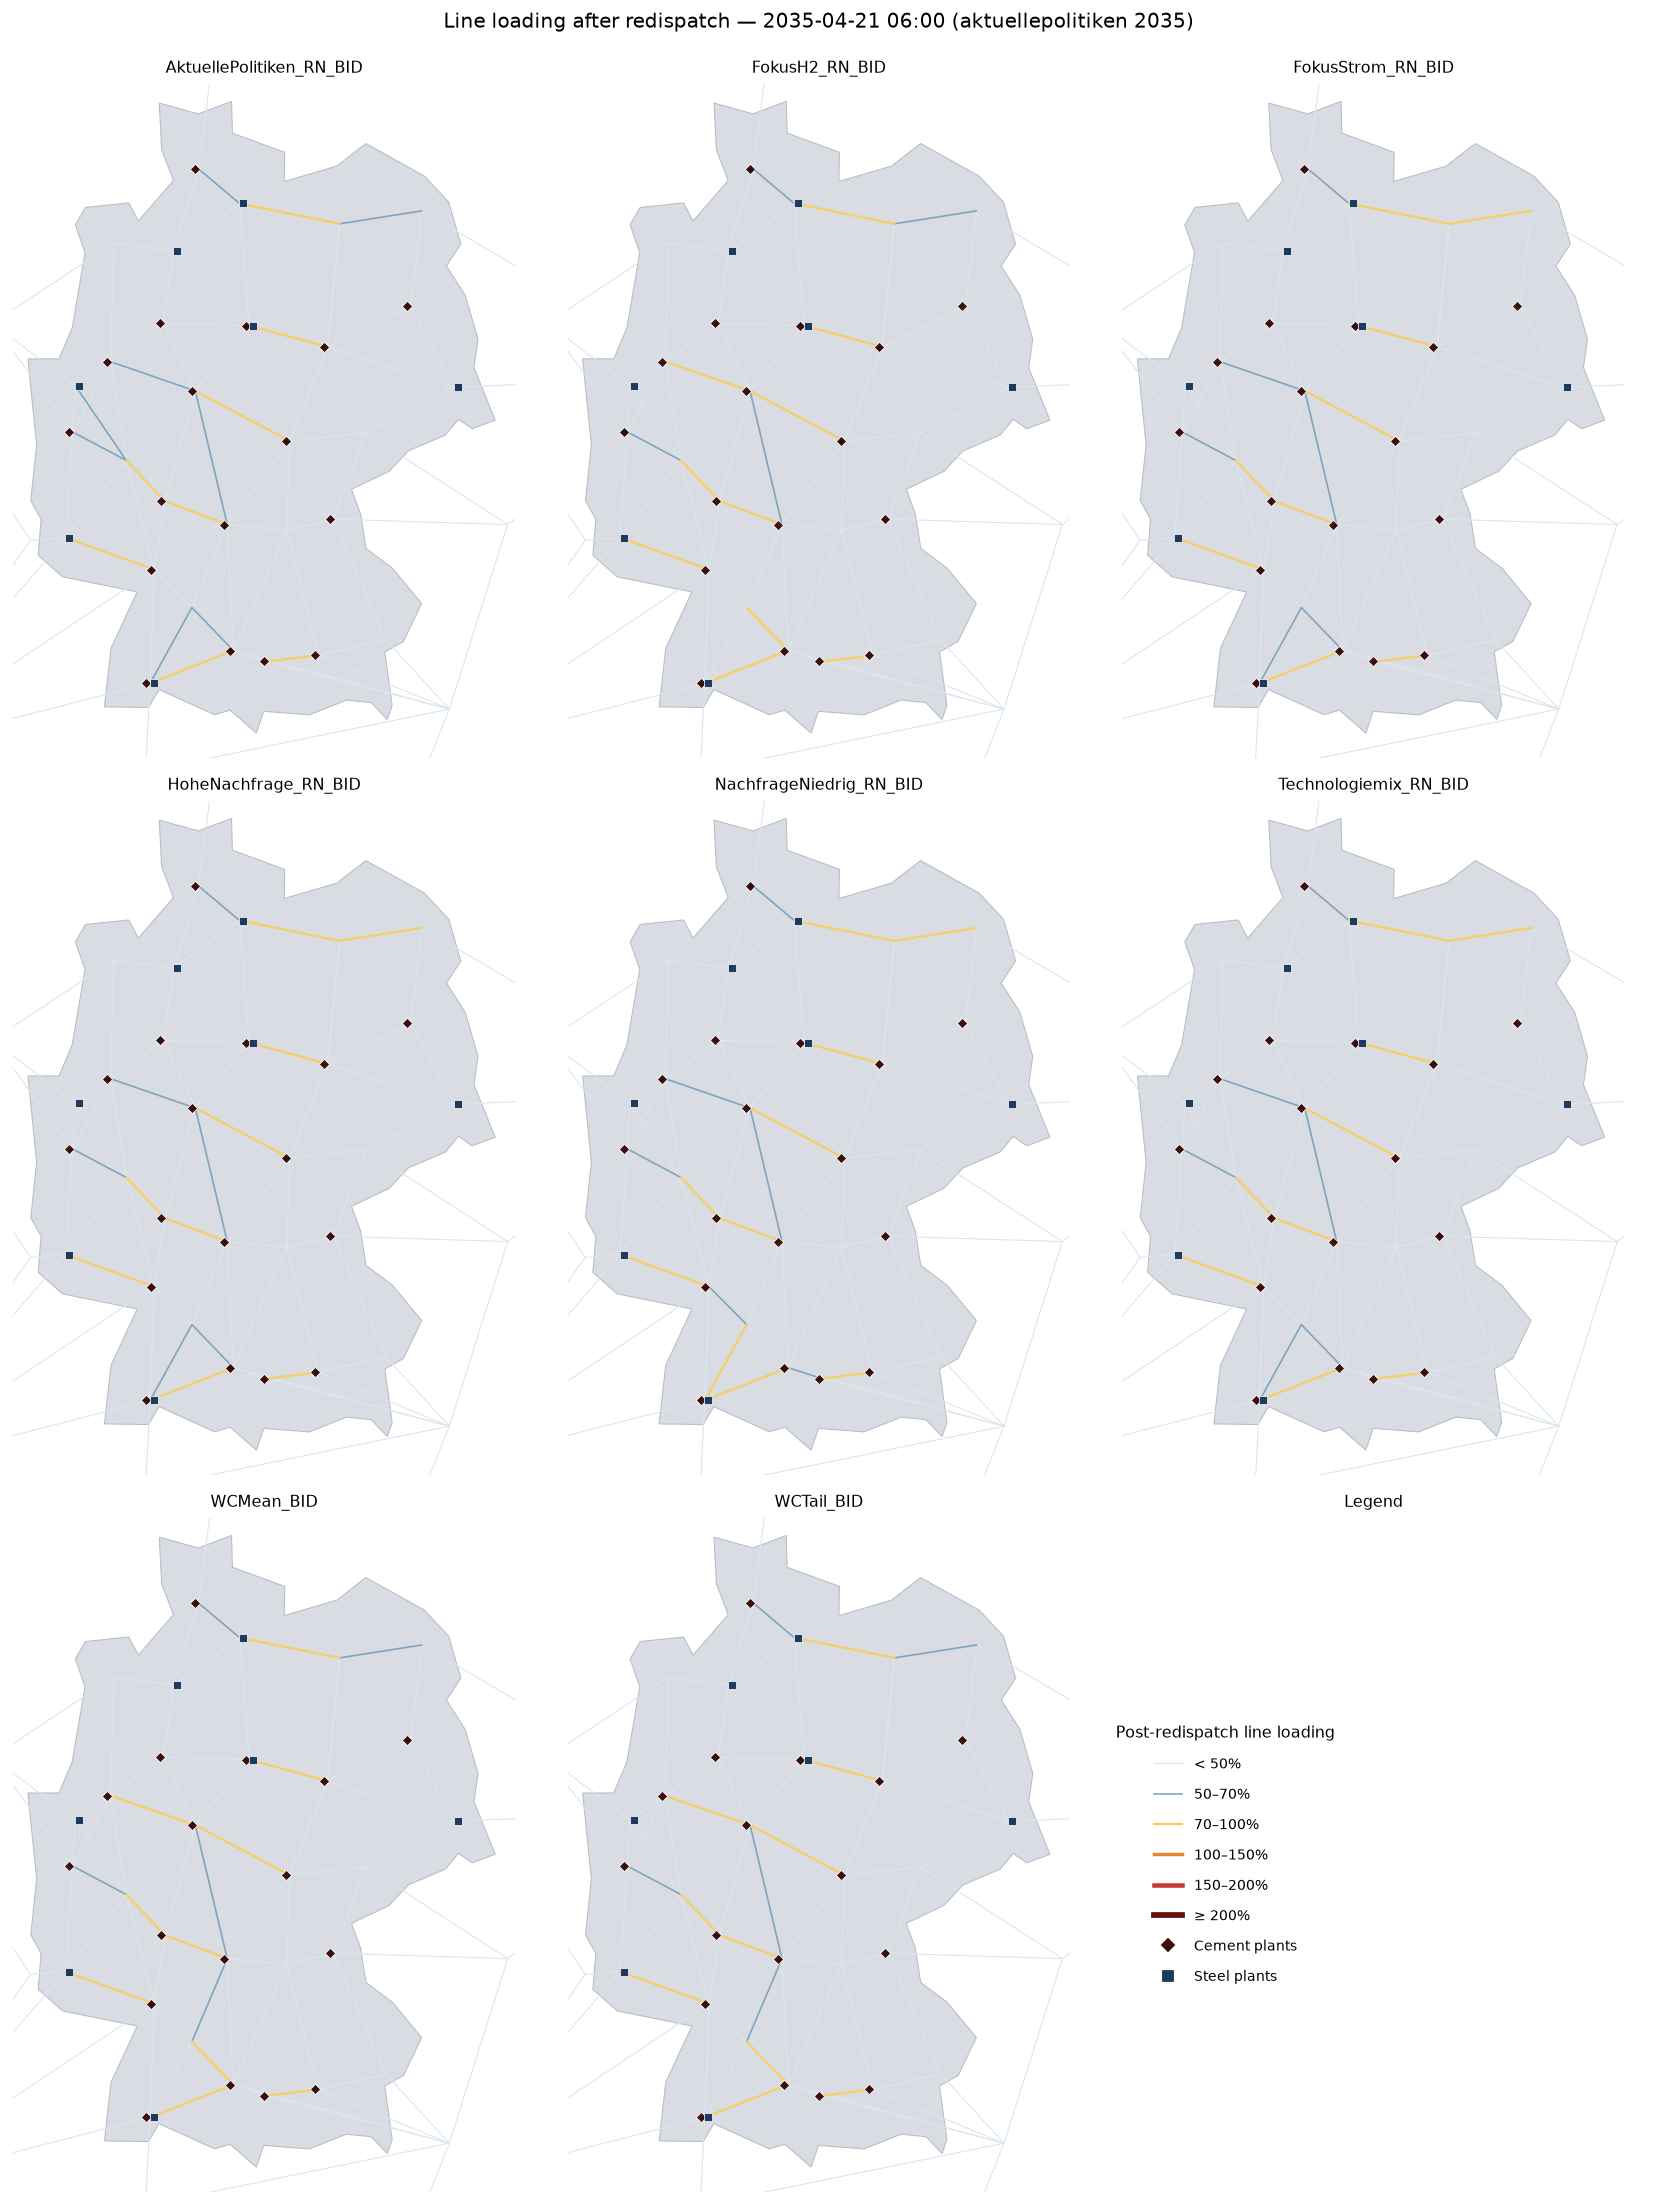

In [80]:
grid_figure(lambda ax, s: draw_loading(ax, s, "post"), load_handles, "Post-redispatch line loading",
            f"Line loading after redispatch — {ts_label}")

In [81]:
summary_g = pd.DataFrame({
    c: {
        "lines >100% before": int((s["pre"] > 1.005).sum()),
        "worst line before (%)": round(s["pre"].max() * 100),
        "lines >100% after": int((s["post"] > 1.005).sum()),
        "worst line after (%)": round(s["post"].max() * 100),
        "upward redispatch (GW)": round(s["net"].clip(lower=0).sum() / 1000, 1),
        "nodes up / down": f"{int((s['net'] > 1).sum())} / {int((s['net'] < -1).sum())}",
    } for c, s in snaps.items()
}).T
display(summary_g)

worst = summary_g["worst line before (%)"].astype(float).idxmax()
biggest = summary_g["upward redispatch (GW)"].astype(float).idxmax()
plant_net = [s["net"][n] for s in snaps.values() for n in set(s["plants"]["cement"]) | set(s["plants"]["steel"])]
n_pl, n_up_pl, n_dn_pl = len(plant_net), sum(v > 1 for v in plant_net), sum(v < -1 for v in plant_net)
wm, wt = CASES[-2], CASES[-1]
twins = (wm in snaps and wt in snaps and np.allclose(snaps[wm]["pre"], snaps[wt]["pre"]))
n_over = int((summary_g["lines >100% before"] > 0).sum())
n_over_after = int((summary_g["lines >100% after"] > 0).sum())
display(Markdown(
    f"**Key finding:** at {TS:%Y-%m-%d %H:%M} {n_over} of {len(snaps)} cases have overloaded lines before redispatch "
    f"(worst: **{worst}**, {summary_g.loc[worst, 'worst line before (%)']:.0f}% loading) and {n_over_after} have any after "
    f"(reconstructed worst line {summary_g['worst line after (%)'].astype(float).max():.0f}%). "
    f"The redispatch volume needed to get there is largest in **{biggest}** "
    f"({summary_g.loc[biggest, 'upward redispatch (GW)']} GW up). "
    + (f"`{wm}` and `{wt}` are identical for this family/year because their inputs "
       "are identical here, so they are not two independent cases at this hour. " if twins else "")
    + f"At nodes that host steel or cement plants (counted per case), redispatch was upward in {n_up_pl} of "
    f"{n_pl} cases-nodes, downward in {n_dn_pl}, and negligible in {n_pl - n_up_pl - n_dn_pl}."
))

,lines >100% before,worst line before (%),lines >100% after,worst line after (%),upward redispatch (GW),nodes up / down
AktuellePolitiken_RN_BID,3,117,0,100,19.6,18 / 6
FokusH2_RN_BID,2,141,0,100,24.4,18 / 7
FokusStrom_RN_BID,4,136,0,100,16.4,17 / 7
HoheNachfrage_RN_BID,2,130,0,100,11.5,22 / 6
NachfrageNiedrig_RN_BID,5,162,0,100,12.3,19 / 4
Technologiemix_RN_BID,5,118,0,100,13.1,21 / 5
WCMean_BID,3,130,0,100,18.1,23 / 7
WCTail_BID,3,130,0,100,18.1,23 / 7


**Key finding:** at 2035-04-21 06:00 8 of 8 cases have overloaded lines before redispatch (worst: **NachfrageNiedrig_RN_BID**, 162% loading) and 0 have any after (reconstructed worst line 100%). The redispatch volume needed to get there is largest in **FokusH2_RN_BID** (24.4 GW up). `WCMean_BID` and `WCTail_BID` are identical for this family/year because their inputs are identical here, so they are not two independent cases at this hour. At nodes that host steel or cement plants (counted per case), redispatch was upward in 128 of 176 cases-nodes, downward in 28, and negligible in 20.

## B12. Run-to-run reproducibility: do identical inputs give identical results?

The two risk-averse cases get byte-identical input files for several family-years, so their simulations should give
identical results there. Wherever that holds, any difference between the two runs is **run-to-run noise** (solver ties,
or code or inputs that changed between the times the runs were made), not an effect of the case. The table shows how large
that noise is for the day-ahead price; it sets the size of case differences that can be trusted in this part.

In [82]:
import hashlib

def _md5(p):
    return hashlib.md5(open(p, "rb").read()).hexdigest()

INPUT_FILES = ["demand_df.csv", "demand_units.csv", "forecasts_df.csv", "powerplant_units.csv",
               "storage_units.csv", "availability_df.csv"]
c1, c2 = CASES[-2], CASES[-1]
arch_r = archives.set_index(["case", "family", "year"])
rows_r = []
for fam in aiu.FAMILIES:
    for yr in aiu.YEARS:
        d1, d2 = aiu.INPUTS_DIR / c1 / f"{fam}_{yr}", aiu.INPUTS_DIR / c2 / f"{fam}_{yr}"
        if not all(_md5(d1 / f) == _md5(d2 / f) for f in INPUT_FILES):
            continue
        pr = []
        for c in (c1, c2):
            a = aiu.load_actor_price(c, fam, yr, arch_r.loc[(c, fam, yr), "path"])
            pr.append(a[a.market_id == "EOM"].set_index("time")["price"])
        diff = (pr[0] - pr[1]).abs()
        rows_r.append({"family": fam, "year": yr, "mean EOM price run 1": pr[0].mean(),
                       "mean EOM price run 2": pr[1].mean(), "difference of means": pr[0].mean() - pr[1].mean(),
                       "hours differing (>0.01)": int((diff > 0.01).sum()), "largest hourly difference": diff.max()})
repro = pd.DataFrame(rows_r)
repro.round(2)

,family,year,mean EOM price run 1,mean EOM price run 2,difference of means,hours differing (>0.01),largest hourly difference
0,aktuellepolitiken,2030,10.63,11.29,-0.65,906,32.85
1,aktuellepolitiken,2035,6.87,6.87,0.00,0,0.00
2,aktuellepolitiken,2040,17.14,17.60,-0.46,957,52.10
3,aktuellepolitiken,2045,18.41,18.41,0.00,0,0.00
4,fokusH2,2045,21.64,21.64,0.00,0,0.00
5,fokusstrom,2045,37.48,36.02,1.46,1568,246.49
6,hohenachfrage,2045,39.12,31.87,7.25,1653,725.70
7,niedrigenachfrage,2045,42.79,42.97,-0.18,182,169.08
8,technologiemix,2045,35.76,33.99,1.77,1155,253.37


In [83]:
if repro.empty:
    display(Markdown("No family-year has byte-identical inputs for the two risk-averse cases, so reproducibility cannot be measured this way."))
else:
    n_pairs = len(repro)
    n_diff = int((repro["hours differing (>0.01)"] > 0).sum())
    display(Markdown(
        f"**Key finding:** {n_pairs} family-years have byte-identical inputs for `{c1}` and `{c2}`; in {n_diff} of them the "
        f"two runs nonetheless give different day-ahead prices (up to {repro['hours differing (>0.01)'].max():,} hours differ, the "
        f"largest hourly difference is {repro['largest hourly difference'].max():.0f} EUR/MWh, and the yearly mean price differs by up to "
        f"{repro['difference of means'].abs().max():.1f} EUR/MWh, median {repro['difference of means'].abs().median():.1f}). "
        f"Differences between cases that are smaller than this cannot be attributed to the case."
    ))

**Key finding:** 9 family-years have byte-identical inputs for `WCMean_BID` and `WCTail_BID`; in 6 of them the two runs nonetheless give different day-ahead prices (up to 1,653 hours differ, the largest hourly difference is 726 EUR/MWh, and the yearly mean price differs by up to 7.2 EUR/MWh, median 0.5). Differences between cases that are smaller than this cannot be attributed to the case.

## Re-running

Everything is recomputed from the archives found in `examples/outputs/` (price-taker: `<case>/`, price-setter:
`<case>_BID/`) each time the notebook runs. Per-scenario results are cached under `examples/outputs/_analysis_cache/`
(namespaces `baseline_meta`, `baseline_capacity`, `baseline_afrr_energy`, `actor_meta`, `actor_capacity_meta`,
`actor_afrr_energy_meta`, `actor_orders_agg`, `system_energy_neg_volume`, `redispatch_summary`, `line_flows`,
`redispatch_nodal`). The cache is keyed by case/family/year and is **not** checked against the age of the archive:
if scenarios are re-simulated, move the affected `<namespace>/<case>/` cache folders aside before re-running, otherwise
the old results are reused.